# 6BUIS017C.1 CRM & CM with Business Intelligence
#Individual Coursework w2083128 | 20232566


##Task 1: Data Preparation and Feature Engineering

## Setup

In [ ]:
!pip install -q yfinance lxml seaborn

import os, sys, json, time, hashlib, shutil, subprocess, platform, warnings
from io import StringIO
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# ---- Settings taken from the brief ----
START, END, BENCH = "2021-01-01", "2025-01-01", "^GSPC"   # END is exclusive
BASE_WINDOW = 20          # sessions in the volume baseline
ACTIVITY_WINDOW = 60      # sessions for Frequency and Monetary
HIGH_VOL_MULT = 2.0       # high-volume day: volume > 2 x baseline
SPLIT_JUMP_LIMIT = 0.25   # my validation rule: |log change in Close| on a split date must be below this
MIN_WEEKS = 52            # my rule: minimum paired weekly observations for a beta
FIG = "figures"
DATA = "data"
ALLOW_LIVE_DOWNLOAD = False   # True ONLY for your first run (to download the data); then set back to False

os.makedirs(DATA, exist_ok=True)
os.makedirs(FIG, exist_ok=True)

# ---- Restore the frozen snapshot: ask for data_snapshot.zip if the data is not here yet ----
if not os.path.exists(f"{DATA}/price_metadata.json") and not ALLOW_LIVE_DOWNLOAD:
    import zipfile
    from google.colab import files
    print("Click 'Choose Files' and select data_snapshot.zip")
    uploaded = files.upload()
    zip_name = next(n for n in uploaded if n.lower().endswith(".zip"))
    with zipfile.ZipFile(zip_name) as z:
        z.extractall(DATA)
    # handle a zip that has an extra top-level folder
    if not os.path.exists(f"{DATA}/price_metadata.json") and os.path.isdir(f"{DATA}/data"):
        shutil.copytree(f"{DATA}/data", DATA, dirs_exist_ok=True)
        shutil.rmtree(f"{DATA}/data")
    print("Snapshot restored.")

def verify(name, condition, hard=True):
    """PASSED, or FAILED (hard=True stops the notebook) / REVIEW (hard=False only flags it)."""
    ok = bool(condition)
    print(("PASSED: " if ok else ("FAILED: " if hard else "REVIEW: ")) + name)
    if hard:
        assert ok, name
    return ok

VERSIONS = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
            "yfinance": yf.__version__, "matplotlib": matplotlib.__version__, "seaborn": sns.__version__,
            "scipy": scipy.__version__, "requests": requests.__version__}
json.dump(VERSIONS, open(f"{DATA}/package_versions.json", "w"), indent=2)
print(VERSIONS)

Click 'Choose Files' and select data_snapshot.zip


Saving CWK1_snapshot-20261124T175852Z-1-001.zip to CWK1_snapshot-20261124T175852Z-1-001 (1).zip
Snapshot restored.
{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'scipy': '1.16.3', 'requests': '2.32.4'}


## 1. Task 1.1 Ticker selection and data acquisition



In [ ]:
import os
import glob
import shutil
import pandas as pd
import requests
from io import StringIO
from datetime import datetime, timezone

WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
CONST_CSV = f"{DATA}/sp500_constituents.csv"

# ---- Robust alignment helper to locate and extract nested datasets ----
if not os.path.exists(CONST_CSV):
    # Look for any extracted sp500_constituents.csv in subdirectories
    candidates = glob.glob("**/sp500_constituents.csv", recursive=True)
    for candidate in candidates:
        source_dir = os.path.dirname(candidate)
        if source_dir and source_dir != DATA:
            print(f"Found dataset at '{candidate}'. Aligning all snapshot files to '{DATA}/'...")
            shutil.copytree(source_dir, DATA, dirs_exist_ok=True)
            print("Files aligned successfully.")
            break

if not os.path.exists(CONST_CSV):
    if not ALLOW_LIVE_DOWNLOAD:
        raise RuntimeError("No constituent snapshot and ALLOW_LIVE_DOWNLOAD is False: restore data/ first.")
    html = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (university coursework)"}, timeout=30).text
    table = pd.read_html(StringIO(html))[0]                       # first table = current constituents
    sp500 = table[["Symbol", "Security", "GICS Sector", "Date added"]].copy()
    sp500.columns = ["Wiki_Symbol", "Security", "Sector", "Date_added"]     # Date_added = date the company joined the index
    sp500["Ticker"] = sp500["Wiki_Symbol"].str.replace(".", "-", regex=False)   # Yahoo style: BRK.B -> BRK-B
    sp500["Retrieved"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")
    sp500.to_csv(CONST_CSV, index=False)
    print("Scraped Wikipedia and saved a new constituent snapshot.")
else:
    sp500 = pd.read_csv(CONST_CSV, keep_default_na=False, na_values=[""])
    print("Loaded the saved constituent snapshot (no new scrape).")
    if "Date_added" not in sp500.columns:
        print("NOTE: this snapshot has no Date_added column, so the survivorship table below will be skipped.")

assert sp500["Ticker"].notna().all() and sp500["Ticker"].is_unique, "Missing or duplicate tickers"
assert sp500["Sector"].notna().all(), "Missing sectors"
tickers = sp500["Ticker"].tolist()
print("Tickers:", len(tickers), "| retrieved:", sp500["Retrieved"].iloc[0])
print("Limitation: current constituents on the retrieval date, not historical membership (survivorship bias).")
sp500["Sector"].value_counts()

Found dataset at 'data/CWK1_snapshot/data/sp500_constituents.csv'. Aligning all snapshot files to 'data/'...
Files aligned successfully.
Loaded the saved constituent snapshot (no new scrape).
Tickers: 503 | retrieved: 2026-11-20 08:32 UTC
Limitation: current constituents on the retrieval date, not historical membership (survivorship bias).


,count
Sector,
Industrials,83
Information Technology,76
Financials,76
Health Care,60
Consumer Discretionary,47
Consumer Staples,33
Utilities,31
Real Estate,30
Materials,24


In [ ]:
FIELDS = ["Adj Close", "Close", "Volume", "Dividends", "Stock Splits"]
FILES = {"Adj Close": "adj_close", "Close": "close", "Volume": "volume",
         "Dividends": "dividends", "Stock Splits": "splits"}
META = f"{DATA}/price_metadata.json"

def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def pick(d, field, symbols):
    """Return one field as a (date x ticker) table, whatever shape yfinance returned."""
    top = d.columns.get_level_values(0) if isinstance(d.columns, pd.MultiIndex) else d.columns
    if field not in set(top):
        return pd.DataFrame(index=d.index)
    x = d[field]
    return x.to_frame(symbols[0]) if isinstance(x, pd.Series) else x

def has_data(wide, t):
    return t in wide["Adj Close"].columns and wide["Adj Close"][t].notna().any()

if not os.path.exists(META) and not ALLOW_LIVE_DOWNLOAD:
    raise RuntimeError("No price snapshot and ALLOW_LIVE_DOWNLOAD is False: restore data/ from Drive, the zip or GitHub.")

if not os.path.exists(META):                                   # first run only: download and freeze
    parts = {f: [] for f in FIELDS}
    for i in range(0, len(tickers), 50):                       # batches of 50 to avoid rate limits
        chunk = tickers[i:i + 50]
        d = yf.download(chunk, start=START, end=END, auto_adjust=False, actions=True,
                        group_by="column", progress=False, threads=True)
        for f in FIELDS:
            parts[f].append(pick(d, f, chunk))
        time.sleep(1)
    wide = {f: pd.concat(parts[f], axis=1) for f in FIELDS}

    failed = [t for t in tickers if not has_data(wide, t)]
    print("Failed first pass:", len(failed), failed[:15])
    for t in failed:                                           # one retry per failed ticker
        d = yf.download([t], start=START, end=END, auto_adjust=False, actions=True,
                        group_by="column", progress=False)
        r = {f: pick(d, f, [t]) for f in FIELDS}
        if has_data(r, t):
            for f in FIELDS:
                wide[f][t] = r[f][t].reindex(wide[f].index) if t in r[f].columns else np.nan
    still_failed = [t for t in tickers if not has_data(wide, t)]

    gspc = yf.download(BENCH, start=START, end=END, auto_adjust=False, progress=False)
    if isinstance(gspc.columns, pd.MultiIndex):
        gspc.columns = gspc.columns.get_level_values(0)

    for f in FIELDS:
        wide[f].sort_index(axis=1).to_csv(f"{DATA}/{FILES[f]}.csv")
    gspc[["Adj Close", "Close", "Volume"]].to_csv(f"{DATA}/gspc.csv")

    saved = [f"{FILES[f]}.csv" for f in FIELDS] + ["gspc.csv", "sp500_constituents.csv"]
    meta = {"downloaded_utc": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
            "source": f"Yahoo Finance via yfinance {yf.__version__}",
            "start": START, "end_exclusive": END, "auto_adjust": False, "actions": True,
            "tickers_requested": len(tickers), "tickers_failed": still_failed,
            "md5": {name: md5(f"{DATA}/{name}") for name in saved}}
    json.dump(meta, open(META, "w"), indent=2)
    print("Downloaded and saved a new price snapshot.")
else:
    print("Price snapshot already exists: skipping download.")

Price snapshot already exists: skipping download.


In [ ]:
# Load the frozen snapshot and verify that no file has changed since it was saved
meta = json.load(open(META))
for name, h in meta["md5"].items():
    assert md5(f"{DATA}/{name}") == h, f"{name} has changed since the snapshot was taken"
print(f"All {len(meta['md5'])} files match their saved MD5 hashes.")

load = lambda n: pd.read_csv(f"{DATA}/{n}.csv", index_col=0, parse_dates=True)
adj, close, vol = load("adj_close"), load("close"), load("volume")
div, splits, bench = load("dividends"), load("splits"), load("gspc")

print("Source      :", meta["source"], "| downloaded", meta["downloaded_utc"])
print("Requested   :", meta["tickers_requested"], "| no data after retry:", len(meta["tickers_failed"]), meta["tickers_failed"])
print("Share data  :", adj.index.min().date(), "to", adj.index.max().date(), "|", adj.shape[0], "rows,", adj.shape[1], "tickers")
print("Benchmark   :", bench.index.min().date(), "to", bench.index.max().date(), "|", len(bench), "rows")
assert bench.index.max() < pd.Timestamp(END), "End date must be exclusive"

All 7 files match their saved MD5 hashes.
Source      : Yahoo Finance via yfinance 0.2.66 | downloaded 2026-11-20 08:34 UTC
Requested   : 503 | no data after retry: 5 ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Share data  : 2021-01-04 to 2024-12-31 | 1005 rows, 503 tickers
Benchmark   : 2021-01-04 to 2024-12-31 | 1005 rows


### Task 1.2 Data validation and alignment



In [ ]:
dates = bench.index.sort_values()                    # master calendar = S&P 500 trading sessions

print("Duplicate dates, shares   :", adj.index.duplicated().sum())
print("Duplicate dates, benchmark:", bench.index.duplicated().sum())
print("Share dates not in benchmark calendar:", len(adj.index.difference(dates)),
      "| benchmark dates not in share data:", len(dates.difference(adj.index)))
print("Benchmark missing values:", int(bench[["Adj Close", "Close", "Volume"]].isna().sum().sum()),
      "| nonpositive prices:", int((bench[["Adj Close", "Close"]] <= 0).sum().sum()))
print("^GSPC Adj Close equals Close on every date:", bool(np.allclose(bench["Adj Close"], bench["Close"])),
      "(a price index pays no dividends)")
print("Master calendar:", dates.min().date(), "to", dates.max().date(), "|", len(dates), "sessions")

# Put every share on the benchmark calendar WITHOUT filling: a missing session stays NaN
adj, close, vol = adj.reindex(dates), close.reindex(dates), vol.reindex(dates)
div, splits = div.reindex(dates).fillna(0), splits.reindex(dates).fillna(0)   # 0 = "no event", not a price

Duplicate dates, shares   : 0
Duplicate dates, benchmark: 0
Share dates not in benchmark calendar: 0 | benchmark dates not in share data: 0
Benchmark missing values: 0 | nonpositive prices: 0
^GSPC Adj Close equals Close on every date: True (a price index pays no dividends)
Master calendar: 2021-01-04 to 2024-12-31 | 1005 sessions


In [ ]:
any_na = adj.isna() | close.isna() | vol.isna()
seen_before = adj.notna().cummax()                         # True from a share's first price onward
seen_after = adj.iloc[::-1].notna().cummax().iloc[::-1]    # True up to a share's last price
close_jump = np.log(close / close.shift(1)).abs()
factor = adj / close                                       # dividend adjustment factor
factor_moved = factor.pct_change(fill_method=None).abs() > 0.001

log = pd.DataFrame(index=pd.Index(tickers, name="Ticker"))
log["First_Date"] = adj.apply(pd.Series.first_valid_index)
log["Last_Date"] = adj.apply(pd.Series.last_valid_index)
log["Missing_Sessions"] = any_na.sum()
log["Missing_Internal"] = (any_na & seen_before & seen_after).sum()
log["Nonpositive_Price_Days"] = ((adj <= 0) | (close <= 0)).sum()
log["Nonpositive_Volume_Days"] = (vol <= 0).sum()
log["Dividend_Events"] = (div > 0).sum()
log["Split_Events"] = (splits > 0).sum()
log["Max_Close_Jump_On_Split"] = close_jump.where(splits > 0).max()
log["Factor_Changes"] = factor_moved.sum()
log["Factor_Changes_Unexplained"] = (factor_moved & (div <= 0) & (splits <= 0)).sum()
log["Max_Abs_Daily_AdjReturn"] = adj.pct_change(fill_method=None).abs().max()

def reason(r):
    if pd.isna(r["First_Date"]):
        return "V1: no data returned by Yahoo Finance"
    out = []
    if r["First_Date"] > dates[0]:
        out.append(f"V2: history starts {r['First_Date'].date()} (listed after study start)")
    if r["Last_Date"] < dates[-1]:
        out.append(f"V2: history ends {r['Last_Date'].date()}")
    if r["Missing_Internal"] > 0:
        out.append(f"V3: {int(r['Missing_Internal'])} missing sessions inside history")
    if r["Nonpositive_Price_Days"] > 0:
        out.append("V4: nonpositive price")
    if r["Nonpositive_Volume_Days"] > 0:
        out.append(f"V5: {int(r['Nonpositive_Volume_Days'])} zero or negative volume days")
    if r["Max_Close_Jump_On_Split"] >= SPLIT_JUMP_LIMIT:
        out.append("V6: Close jumps on a split date (not split-adjusted)")
    return "; ".join(out)

log["Exclusion_Reason"] = log.apply(reason, axis=1)
log["Included"] = log["Exclusion_Reason"] == ""
log = log.join(sp500.set_index("Ticker")[[c for c in ["Security", "Sector", "Date_added"] if c in sp500.columns]])
keep = log.index[log["Included"]].tolist()

excl_log = log.loc[~log["Included"], ["Security", "Sector", "First_Date", "Last_Date", "Exclusion_Reason"]]
excl_log.to_csv(f"{DATA}/exclusion_log.csv")
log.to_csv(f"{DATA}/validation_log_all_tickers.csv")
pd.Series(keep, name="Ticker").to_csv(f"{DATA}/retained_tickers.csv", index=False)

print("Requested:", len(tickers), "| Excluded:", len(excl_log), "| Retained:", len(keep))
rule_counts = (excl_log["Exclusion_Reason"].str.split("; ").explode().str.split(":").str[0].value_counts())
print("\nExclusions by rule (a share can break more than one):\n", rule_counts.to_string())
display(excl_log.head(25))

Requested: 503 | Excluded: 17 | Retained: 486

Exclusions by rule (a share can break more than one):
 Exclusion_Reason
V2    10
V1     5
V5     2


,Security,Sector,First_Date,Last_Date,Exclusion_Reason
Ticker,,,,,
APP,AppLovin,Communication Services,2021-04-15,2024-12-31,V2: history starts 2021-04-15 (listed after st...
COIN,Coinbase,Financials,2021-04-14,2024-12-31,V2: history starts 2021-04-14 (listed after st...
CEG,Constellation Energy,Utilities,2022-01-19,2024-12-31,V2: history starts 2022-01-19 (listed after st...
EXE,Expand Energy,Energy,2021-02-10,2024-12-31,V2: history starts 2021-02-10 (listed after st...
FDXF,FedEx Freight,Industrials,NaT,NaT,V1: no data returned by Yahoo Finance
FERG,Ferguson Enterprises,Industrials,2021-01-04,2024-12-31,V5: 27 zero or negative volume days
GEHC,GE HealthCare,Health Care,2022-12-15,2024-12-31,V2: history starts 2022-12-15 (listed after st...
GEV,GE Vernova,Industrials,2024-03-27,2024-12-31,V2: history starts 2024-03-27 (listed after st...
HONA,Honeywell Aerospace,Industrials,NaT,NaT,V1: no data returned by Yahoo Finance


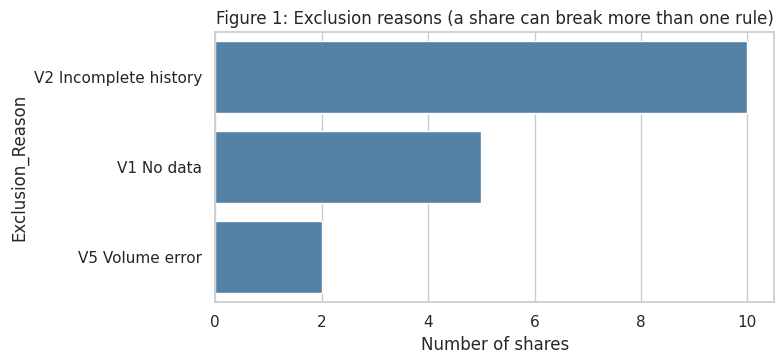

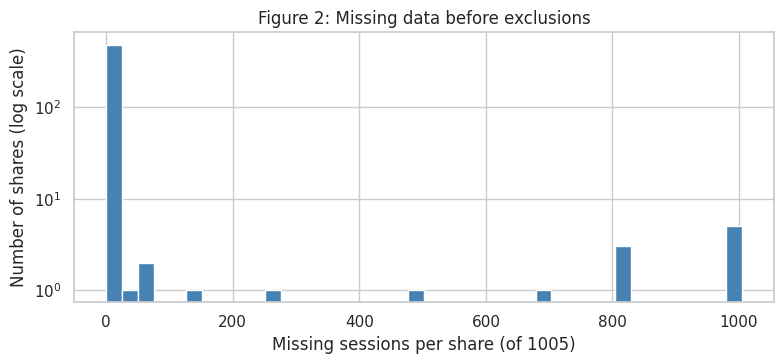

In [ ]:
# Figure 1: why shares were excluded
labels = {"V1": "V1 No data", "V2": "V2 Incomplete history", "V3": "V3 Missing sessions",
          "V4": "V4 Nonpositive price", "V5": "V5 Volume error", "V6": "V6 Split not adjusted"}
fig, ax = plt.subplots(figsize=(8, 3.8))
vals = rule_counts.rename(index=labels)
sns.barplot(x=vals.values, y=vals.index, ax=ax, color="steelblue")
ax.set_xlabel("Number of shares"); ax.set_title("Figure 1: Exclusion reasons (a share can break more than one rule)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig1_exclusions.png", dpi=150); plt.show()

# Figure 2: missing sessions per share, before exclusions
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(log["Missing_Sessions"].dropna(), bins=40, color="steelblue")
ax.set_yscale("log")
ax.set_xlabel("Missing sessions per share (of %d)" % len(dates)); ax.set_ylabel("Number of shares (log scale)")
ax.set_title("Figure 2: Missing data before exclusions")
plt.tight_layout(); plt.savefig(f"{FIG}/fig2_missing.png", dpi=150); plt.show()

                         Retained_shares  Percent
joined before 2021                   414     85.2
joined during 2021-2024               47      9.7
joined 2025 or later                  25      5.1
date missing                           0      0.0

Retained shares that joined the index after the study window (never members during 2021-2024): 25
                  Security  Date_added
Ticker                                
OKTA            Okta, Inc.  2026-11-04
TWLO                Twilio  2026-10-06
BE            Bloom Energy  2026-09-21
ILMN        Illumina, Inc.  2026-09-21
P                 Everpure  2026-09-21
FLEX             Flex Ltd.  2026-06-22
MRVL    Marvell Technology  2026-06-22
VEEV         Veeva Systems  2026-05-07


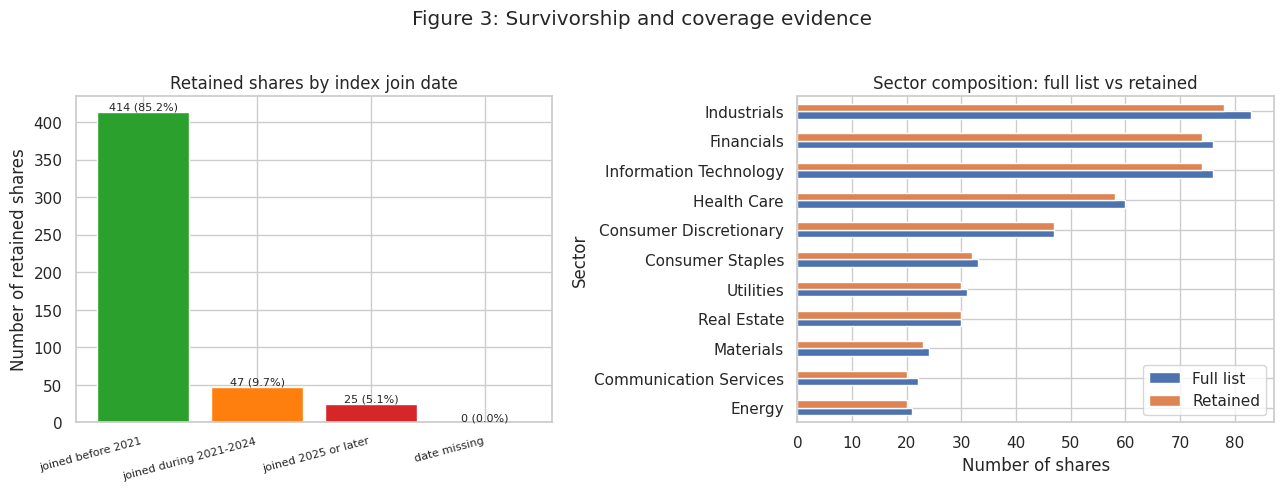


Exclusions by sector (%):
Sector
Communication Services    9.1
Industrials               6.0
Energy                    4.8
Materials                 4.2
Health Care               3.3
Utilities                 3.2
Consumer Staples          3.0
Financials                2.6
Information Technology    2.6
Consumer Discretionary    0.0
Real Estate               0.0


In [ ]:
# Survivorship bias: how many retained shares were NOT yet index members for part or all of the study window?
# Date_added is the date a company joined the S&P 500 (not its listing date). Companies REMOVED from the index during
# 2021 to 2024 are not on today's list at all, so they are missing from this dataset and cannot be counted here.
sector_view = pd.DataFrame({"Full list": sp500["Sector"].value_counts(),
                            "Retained": log.loc[keep, "Sector"].value_counts()}).fillna(0).astype(int)
sector_view["Percent_excluded"] = (100 * (1 - sector_view["Retained"] / sector_view["Full list"])).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
if "Date_added" in log.columns:
    added = pd.to_datetime(log["Date_added"], errors="coerce")
    group = pd.Series("date missing", index=log.index)
    group.loc[added < pd.Timestamp(START)] = "joined before 2021"
    group.loc[(added >= pd.Timestamp(START)) & (added < pd.Timestamp(END))] = "joined during 2021-2024"
    group.loc[added >= pd.Timestamp(END)] = "joined 2025 or later"
    order = ["joined before 2021", "joined during 2021-2024", "joined 2025 or later", "date missing"]
    counts = group[log["Included"]].value_counts().reindex(order).fillna(0).astype(int)
    print(pd.DataFrame({"Retained_shares": counts, "Percent": (100 * counts / len(keep)).round(1)}).to_string())
    recent = log.loc[log["Included"] & (added >= pd.Timestamp(END)), ["Security", "Date_added"]]
    print("\nRetained shares that joined the index after the study window (never members during 2021-2024):", len(recent))
    print(recent.sort_values("Date_added", ascending=False).head(8).to_string())
    axes[0].bar(range(len(counts)), counts.values, color=["tab:green", "tab:orange", "tab:red", "grey"])
    axes[0].set_xticks(range(len(counts))); axes[0].set_xticklabels(counts.index, rotation=15, ha="right", fontsize=8)
    for i_, v_ in enumerate(counts.values):
        axes[0].text(i_, v_, f"{v_} ({100 * v_ / len(keep):.1f}%)", ha="center", va="bottom", fontsize=8)
    axes[0].set_ylabel("Number of retained shares"); axes[0].set_title("Retained shares by index join date")
else:
    axes[0].text(0.5, 0.5, "No Date_added column in the snapshot", ha="center"); axes[0].set_axis_off()
sector_view[["Full list", "Retained"]].sort_values("Full list").plot.barh(ax=axes[1])
axes[1].set_xlabel("Number of shares"); axes[1].set_title("Sector composition: full list vs retained")
plt.suptitle("Figure 3: Survivorship and coverage evidence", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/fig3_survivorship.png", dpi=150, bbox_inches="tight"); plt.show()
print("\nExclusions by sector (%):")
print(sector_view["Percent_excluded"].sort_values(ascending=False).to_string())

Shares with a stock split in the period: 53 | shares paying dividends: 392
Split events among retained shares: 61


,Ticker,Date,Split_ratio,Close_abs_log_change,AdjClose_abs_return
22,DXCM,2022-06-13,4.000,0.0764,0.0735
20,T,2022-04-11,1.324,0.0738,0.0766
43,MMM,2024-04-01,1.196,0.0584,0.0601
31,GE,2023-01-04,1.281,0.0566,0.0582
38,FLEX,2024-01-03,1.327,0.0389,0.0397
30,TECH,2022-11-30,4.000,0.0387,0.0394
3,CSGP,2021-06-28,10.000,0.0386,0.0379
16,EXC,2022-02-02,1.402,0.0383,0.0391
12,DELL,2021-11-02,1.973,0.0343,0.0338
59,PANW,2024-12-16,2.000,0.0298,0.0302



Events tested for the Volume basis: {'ordinary split': 40, 'fractional ratio': 17}
PASSED: no ordinary split shows unadjusted Volume
Median traded-value ratio after/before for ordinary splits (about 1 means Close x Volume is continuous): 0.907
Fractional ratios (about 1.02 to 1.4) look like spin-off style adjustments and give the test little power.


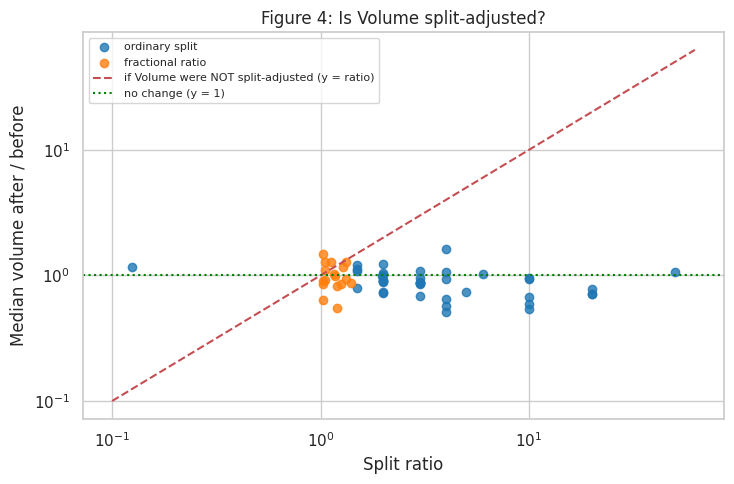


Adj Close / Close factor changes: 5769 | not on a dividend or split date: 0 (100.0% explained). Yahoo sometimes books an adjustment a day late.
PASSED: Adj Close never exceeds Close

Shares with a one-day Adj Close move above 50%: 3


,Max_Abs_Daily_AdjReturn
Ticker,
BE,0.591867
CVNA,0.560206
GL,0.531402


Longest run of unchanged adjusted prices: 2 days | shares with 5 or more: 0
PASSED: no retained share has a frozen price feed (5+ unchanged days in a row)


True

In [ ]:
# Corporate action checks on the retained shares
ret = log.loc[keep]
print("Shares with a stock split in the period:", int((ret["Split_Events"] > 0).sum()),
      "| shares paying dividends:", int((ret["Dividend_Events"] > 0).sum()))

# (1) Does Close jump on a split date?
sp = splits[keep].stack()
sp = sp[sp > 0]
split_table = pd.DataFrame([(t_, d_.date(), ratio, round(close_jump.loc[d_, t_], 4),
                             round(abs(adj[t_].pct_change(fill_method=None).loc[d_]), 4))
                            for (d_, t_), ratio in sp.items()],
                           columns=["Ticker", "Date", "Split_ratio", "Close_abs_log_change", "AdjClose_abs_return"])
split_table.to_csv(f"{DATA}/split_check.csv", index=False)
print("Split events among retained shares:", len(split_table))
display(split_table.sort_values("Close_abs_log_change", ascending=False).head(10))

# (2) Is VOLUME on the same split-adjusted basis? Monetary multiplies Close by Volume, so both must be on one basis.
# If Volume were not adjusted, a 2-for-1 split would roughly double volume after the split (ratio near 2);
# if it is adjusted, volume stays continuous (ratio near 1). Compare median volume 20 sessions after vs before.
value = close[keep] * vol[keep]
rows = []
for (d_, t_), ratio in sp.items():
    i_ = dates.get_loc(d_)
    if i_ < 21 or i_ > len(dates) - 22:
        continue                                              # too close to the edge of the data to test
    b_, a_ = slice(i_ - 20, i_), slice(i_ + 1, i_ + 21)
    rows.append((t_, d_.date(), ratio, vol[t_].iloc[a_].median() / vol[t_].iloc[b_].median(),
                 value[t_].iloc[a_].median() / value[t_].iloc[b_].median()))
vsplit = pd.DataFrame(rows, columns=["Ticker", "Date", "Split_ratio", "Volume_after_over_before", "Value_after_over_before"])
vsplit["Type"] = np.where((vsplit["Split_ratio"] >= 1.5) | (vsplit["Split_ratio"] <= 0.67), "ordinary split", "fractional ratio")
dist_adjusted = np.abs(np.log(vsplit["Volume_after_over_before"]))                         # distance from "no change"
dist_raw = np.abs(np.log(vsplit["Volume_after_over_before"] / vsplit["Split_ratio"]))      # distance from "volume moved by the ratio"
vsplit["Looks_unadjusted"] = (vsplit["Type"] == "ordinary split") & (dist_raw < dist_adjusted)
vsplit.to_csv(f"{DATA}/split_volume_check.csv", index=False)
tested = vsplit[vsplit["Type"] == "ordinary split"]
print("\nEvents tested for the Volume basis:", vsplit["Type"].value_counts().to_dict())
verify("no ordinary split shows unadjusted Volume", int(tested["Looks_unadjusted"].sum()) == 0, hard=False)
if len(tested):
    print("Median traded-value ratio after/before for ordinary splits (about 1 means Close x Volume is continuous):",
          round(float(tested["Value_after_over_before"].median()), 3))
print("Fractional ratios (about 1.02 to 1.4) look like spin-off style adjustments and give the test little power.")

if len(vsplit):
    fig, ax = plt.subplots(figsize=(7.5, 5))
    for typ, col_ in [("ordinary split", "tab:blue"), ("fractional ratio", "tab:orange")]:
        s_ = vsplit[vsplit["Type"] == typ]
        ax.scatter(s_["Split_ratio"], s_["Volume_after_over_before"], label=typ, color=col_, alpha=0.8)
    xs = np.logspace(np.log10(vsplit["Split_ratio"].min() * 0.8), np.log10(vsplit["Split_ratio"].max() * 1.25), 50)
    ax.plot(xs, xs, "r--", label="if Volume were NOT split-adjusted (y = ratio)")
    ax.axhline(1, color="green", ls=":", label="no change (y = 1)")
    ax.set(xscale="log", yscale="log", xlabel="Split ratio", ylabel="Median volume after / before",
           title="Figure 4: Is Volume split-adjusted?")
    ax.legend(fontsize=8); plt.tight_layout()
    plt.savefig(f"{FIG}/fig4_split_volume.png", dpi=150); plt.show()

# (3) Adj Close vs Close: should differ only by dividends
fc, fu = int(ret["Factor_Changes"].sum()), int(ret["Factor_Changes_Unexplained"].sum())
print(f"\nAdj Close / Close factor changes: {fc} | not on a dividend or split date: {fu} "
      f"({100 * (1 - fu / max(fc, 1)):.1f}% explained). Yahoo sometimes books an adjustment a day late.")
verify("Adj Close never exceeds Close", int(((adj[keep] / close[keep]) > 1.0001).sum().sum()) == 0, hard=False)

# (4) Extreme moves and frozen prices
big = ret["Max_Abs_Daily_AdjReturn"]
print("\nShares with a one-day Adj Close move above 50%:", int((big > 0.5).sum()))
display(big[big > 0.5].sort_values(ascending=False))

def longest_run(flags_):
    g_ = (flags_ != flags_.shift()).cumsum()
    return int(flags_.groupby(g_).sum().max())
stale = (adj[keep].pct_change(fill_method=None) == 0).apply(longest_run)
print("Longest run of unchanged adjusted prices:", int(stale.max()), "days | shares with 5 or more:", int((stale >= 5).sum()))
verify("no retained share has a frozen price feed (5+ unchanged days in a row)", int((stale >= 5).sum()) == 0, hard=False)

In [ ]:
# Evidence that the retained set is compatible
print("Retained shares:", len(keep))
print("Retained shares with a complete history (all", len(dates), "sessions):",
      int((adj[keep].notna().sum() == len(dates)).sum()))
print("Missing sessions in retained shares:", int(ret["Missing_Sessions"].sum()),
      "| nonpositive prices:", int(ret["Nonpositive_Price_Days"].sum()),
      "| zero/negative volume:", int(ret["Nonpositive_Volume_Days"].sum()))

Retained shares: 486
Retained shares with a complete history (all 1005 sessions): 486
Missing sessions in retained shares: 0 | nonpositive prices: 0 | zero/negative volume: 0


##  Task 1.3 Weekly return and weekly beta



In [ ]:
def to_weekly(df):
    w = df.resample("W-FRI").last()                                   # last available price in each Friday-ending week
    complete = (w.index - pd.Timedelta(days=4) >= pd.Timestamp(START)) & (w.index < pd.Timestamp(END))
    return w[complete]

wk_px = to_weekly(adj[keep])
wk_bench = to_weekly(bench[["Adj Close"]])["Adj Close"]
assert wk_px.index.equals(wk_bench.index), "Share and benchmark week labels differ"
assert (wk_px.index.dayofweek == 4).all(), "Week labels must be Fridays"

# the first complete week only supplies the base price, so its return is undefined and is dropped
wk_ret = wk_px.pct_change(fill_method=None).iloc[1:]
bench_ret = wk_bench.pct_change(fill_method=None).iloc[1:]
assert wk_ret.index.equals(bench_ret.index)

print("Weekly prices:", len(wk_px), "| weekly returns:", len(wk_ret))
print("First return week:", wk_ret.index.min().date(), "| last week:", wk_ret.index.max().date())
print("Missing weekly returns, shares:", int(wk_ret.isna().sum().sum()), "| benchmark:", int(bench_ret.isna().sum()))

# Evidence for the weekly calendar
sessions = pd.Series(1, index=dates).resample("W-FRI").sum()
kept_week = (sessions.index - pd.Timedelta(days=4) >= pd.Timestamp(START)) & (sessions.index < pd.Timestamp(END))
print("\nWeeks removed as incomplete calendar weeks:")
print(sessions[~kept_week].rename("Trading_sessions").to_string())
short = sessions[kept_week & (sessions < 5)]
print("\nHoliday-shortened weeks kept (fewer than 5 sessions):", len(short))
# Independent check: every weekly price must equal the Adj Close on that week's final trading session
last_session = pd.Series(dates, index=dates).resample("W-FRI").max().dropna()
by_hand = adj[keep].loc[last_session.values]
by_hand.index = last_session.index
verify("weekly prices equal the final trading-session Adj Close of each week",
       np.allclose(by_hand.loc[wk_px.index].to_numpy(), wk_px.to_numpy()))
verify("no week skipped: labels are exactly 7 days apart", (wk_px.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all())
verify("no missing weekly prices (nothing filled)", wk_px.notna().all().all())
if len(short):
    h_ = short.index[0]
    last_day = dates[dates <= h_][-1]
    print(f"Holiday-shortened week {h_.date()}: last session {last_day.date()} ({last_day.day_name()})")
    verify("a holiday-shortened week uses its last trading session", np.allclose(wk_px.loc[h_], adj.loc[last_day, keep]))

wk_px.assign(**{BENCH: wk_bench}).to_csv(f"{DATA}/weekly_adj_close.csv")
wk_ret.assign(**{BENCH: bench_ret}).to_csv(f"{DATA}/weekly_returns.csv")

Weekly prices: 208 | weekly returns: 207
First return week: 2021-01-15 | last week: 2024-12-27
Missing weekly returns, shares: 0 | benchmark: 0

Weeks removed as incomplete calendar weeks:
Date
2025-01-03    2
Freq: W-FRI

Holiday-shortened weeks kept (fewer than 5 sessions): 37
PASSED: weekly prices equal the final trading-session Adj Close of each week
PASSED: no week skipped: labels are exactly 7 days apart
PASSED: no missing weekly prices (nothing filled)
Holiday-shortened week 2021-01-22: last session 2021-01-22 (Friday)
PASSED: a holiday-shortened week uses its last trading session


### 1.3.1 Mean weekly return

In [ ]:
mean_ret = wk_ret.mean().rename("Mean_Weekly_Return")          # arithmetic mean over the full period
weekly_obs = wk_ret.notna().sum()
print("Weekly observations per share:", weekly_obs.unique())

# Independent check for one share: rebuild the weekly returns from the daily prices by hand
t = "AAPL" if "AAPL" in keep else keep[0]
p = adj[t].dropna()
fridays = wk_ret.index
end_p = [p[(p.index <= f) & (p.index > f - pd.Timedelta(days=7))].iloc[-1] for f in fridays]
prev_p = [p[(p.index <= f - pd.Timedelta(days=7)) & (p.index > f - pd.Timedelta(days=14))].iloc[-1] for f in fridays]
manual = np.array(end_p) / np.array(prev_p) - 1
print(f"{t}: weekly returns match manual rebuild = {np.allclose(manual, wk_ret[t].values)} | "
      f"manual mean = {manual.mean():.6f} | pandas mean = {mean_ret[t]:.6f}")
# Worked example: the first weeks of one share
w_ = wk_px[t]
display(pd.DataFrame({"Week_end": w_.index[:4].date, "Adj_Close": w_.iloc[:4].round(4).values,
                      "Weekly_return": w_.pct_change(fill_method=None).iloc[:4].round(5).values}))
print(f"{t}: mean of {len(wk_ret)} weekly returns = {mean_ret[t]:.5f} ({100 * mean_ret[t]:.3f}% per week); "
      "the first week has no previous week, so it has no return")

# Independent numpy check for every share
P = wk_px.to_numpy()
verify("mean weekly return equals a numpy recalculation for every share", np.allclose(mean_ret.to_numpy(), (P[1:] / P[:-1] - 1).mean(axis=0)))
verify("every share has the same number of weekly observations", weekly_obs.nunique() == 1)

print("\nMean weekly return, % per week:")
print((100 * mean_ret).describe().round(3).to_string())
print("Skewness:", round(float(mean_ret.skew()), 3), "| excess kurtosis:", round(float(mean_ret.kurt()), 3))
print("Benchmark mean weekly return:", round(100 * float(bench_ret.mean()), 3), "% per week")

# Limit of the arithmetic mean: never below the compound (geometric) weekly growth rate; the gap grows with volatility
geo = (wk_px.iloc[-1] / wk_px.iloc[0]) ** (1 / len(wk_ret)) - 1
gap = mean_ret - geo
verify("arithmetic mean is never below the geometric mean", (gap > -1e-12).all())
print("Arithmetic minus geometric weekly mean (percentage points): median", round(100 * float(gap.median()), 3),
      "| max", round(100 * float(gap.max()), 3), "| correlation of the gap with weekly return variance:",
      round(float(gap.corr(wk_ret.var())), 3))
mean_ret.describe()

Weekly observations per share: [207]
AAPL: weekly returns match manual rebuild = True | manual mean = 0.003930 | pandas mean = 0.003930


,Week_end,Adj_Close,Weekly_return
0,2021-01-08,128.0981,NaN
1,2021-01-15,123.3351,-0.03718
2,2021-01-22,134.9080,0.09383
3,2021-01-29,128.0108,-0.05113


AAPL: mean of 207 weekly returns = 0.00393 (0.393% per week); the first week has no previous week, so it has no return
PASSED: mean weekly return equals a numpy recalculation for every share
PASSED: every share has the same number of weekly observations

Mean weekly return, % per week:
count    486.000
mean       0.286
std        0.265
min       -0.447
25%        0.118
50%        0.262
75%        0.421
max        1.777
Skewness: 0.868 | excess kurtosis: 3.019
Benchmark mean weekly return: 0.24 % per week
PASSED: arithmetic mean is never below the geometric mean
Arithmetic minus geometric weekly mean (percentage points): median 0.074 | max 1.221 | correlation of the gap with weekly return variance: 0.999


,Mean_Weekly_Return
count,486.000000
mean,0.002857
std,0.002652
min,-0.004468
25%,0.001182
50%,0.002619
75%,0.004207
max,0.017772


### 1.3.2 Weekly beta

In [ ]:
def weekly_beta(returns, market, min_weeks=MIN_WEEKS):
    out = {}
    for s in returns.columns:
        pair = pd.concat([returns[s], market], axis=1, keys=["s", "m"]).replace([np.inf, -np.inf], np.nan).dropna()
        var = pair["m"].var(ddof=1)
        beta_s = pair["s"].cov(pair["m"]) / var if (len(pair) >= min_weeks and var > 0) else np.nan
        out[s] = (beta_s, len(pair))
    res = pd.DataFrame(out, index=["Beta", "Paired_weeks"]).T
    res["Paired_weeks"] = res["Paired_weeks"].astype(int)
    return res

beta_df = weekly_beta(wk_ret, bench_ret)
beta = beta_df["Beta"]
print("Aligned weekly observations (Paired_weeks):", beta_df["Paired_weeks"].unique())
print("Benchmark weekly variance:", round(bench_ret.var(ddof=1), 6))

# Check 1: beta equals the slope of an OLS regression of the share on the benchmark
slopes = pd.Series({s: np.polyfit(bench_ret, wk_ret[s], 1)[0] for s in keep})
print("Max |cov/var beta - OLS slope|:", float((beta - slopes).abs().max()))

# Check 2: worked example by hand
x, y = bench_ret, wk_ret[t]
cov_xy = ((y - y.mean()) * (x - x.mean())).sum() / (len(x) - 1)
var_x = ((x - x.mean()) ** 2).sum() / (len(x) - 1)
print(f"{t}: Cov = {cov_xy:.6f}, Var(market) = {var_x:.6f}, Beta = {cov_xy / var_x:.4f}, n = {len(x)} weeks")

# Check 3: price-basis sensitivity. Shares use Adj Close (dividends included); ^GSPC is a price index.
wk_ret_c = to_weekly(close[keep]).pct_change(fill_method=None).iloc[1:]
bench_ret_c = to_weekly(bench[["Close"]])["Close"].pct_change(fill_method=None).iloc[1:]
beta_close = weekly_beta(wk_ret_c, bench_ret_c)["Beta"]
diff = (beta - beta_close).abs()
print("\nBeta on Adj Close vs beta on Close (price only): correlation", round(beta.corr(beta_close), 4),
      "| median |difference|", round(diff.median(), 4), "| max", round(diff.max(), 4), f"({diff.idxmax()})")
verify("the benchmark's own beta equals 1", np.isclose(bench_ret.cov(bench_ret) / bench_ret.var(), 1.0))
verify("beta equals a plain numpy covariance calculation",
       np.allclose(beta.to_numpy(), np.array([np.cov(wk_ret[s_], bench_ret)[0, 1] for s_ in keep]) / np.var(bench_ret.to_numpy(), ddof=1)))

# Estimation limits: explanatory power, precision and stability
n_weeks = len(bench_ret)
corr_m = wk_ret.corrwith(bench_ret)
se = beta.abs() * np.sqrt((1 - corr_m ** 2) / (corr_m ** 2 * (n_weeks - 2)))      # standard error of a regression slope
half = n_weeks // 2
b_first = weekly_beta(wk_ret.iloc[:half], bench_ret.iloc[:half], min_weeks=20)["Beta"]
b_last = weekly_beta(wk_ret.iloc[half:], bench_ret.iloc[half:], min_weeks=20)["Beta"]
print(f"\nCorrelation with the benchmark: median {corr_m.median():.3f} | R-squared: median {(corr_m ** 2).median():.3f}")
print(f"Standard error of beta: median {se.median():.3f} | max {se.max():.3f} | "
      f"share of betas whose 95% interval contains 1: {((beta - 1).abs() < 1.96 * se).mean():.3f}")
print(f"Beta in the first {half} weeks vs the last {n_weeks - half}: correlation {b_first.corr(b_last):.3f} | "
      f"median absolute change {(b_last - b_first).abs().median():.3f}")
print("Betas above 1:", round(float((beta > 1).mean()), 3), "| below 0.5:", int((beta < 0.5).sum()), "| below 0:", int((beta < 0).sum()))
print("Skewness:", round(float(beta.skew()), 3), "| excess kurtosis:", round(float(beta.kurt()), 3))
beta.describe()

Aligned weekly observations (Paired_weeks): [207]
Benchmark weekly variance: 0.000492
Max |cov/var beta - OLS slope|: 3.1086244689504383e-15
AAPL: Cov = 0.000578, Var(market) = 0.000492, Beta = 1.1748, n = 207 weeks

Beta on Adj Close vs beta on Close (price only): correlation 0.9999 | median |difference| 0.0013 | max 0.0171 (PSA)
PASSED: the benchmark's own beta equals 1
PASSED: beta equals a plain numpy covariance calculation

Correlation with the benchmark: median 0.533 | R-squared: median 0.284
Standard error of beta: median 0.101 | max 0.436 | share of betas whose 95% interval contains 1: 0.432
Beta in the first 103 weeks vs the last 104: correlation 0.783 | median absolute change 0.214
Betas above 1: 0.444 | below 0.5: 59 | below 0: 0
Skewness: 1.104 | excess kurtosis: 4.471


,Beta
count,486.000000
mean,0.973695
std,0.407339
min,0.055453
25%,0.666599
50%,0.950610
75%,1.179538
max,3.778560


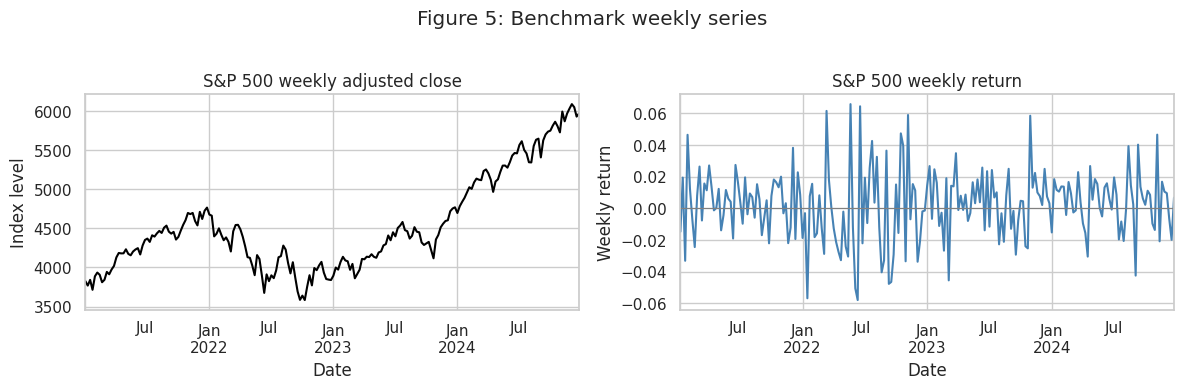

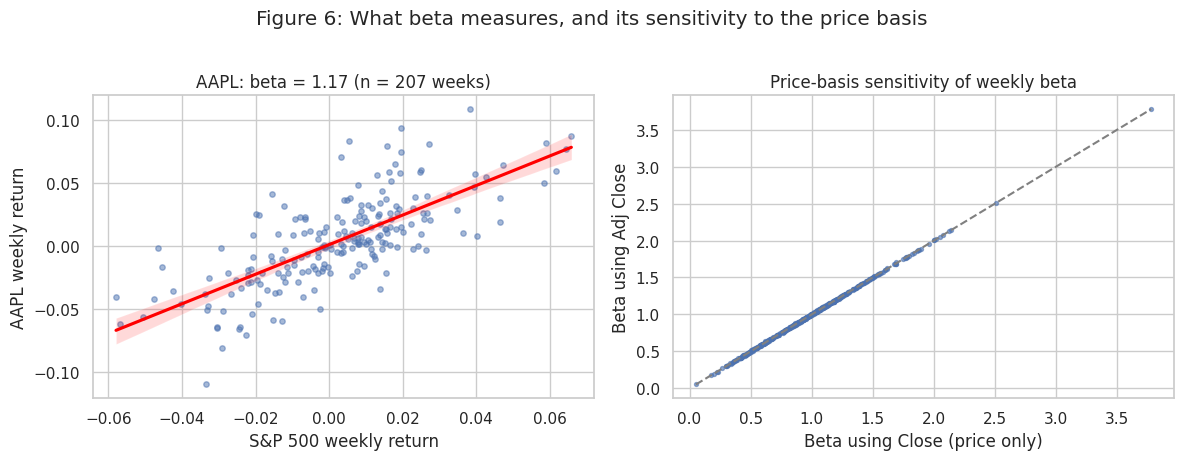

In [ ]:
# Figure 5: benchmark; Figure 6: beta example and price-basis check
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
wk_bench.plot(ax=axes[0], color="black"); axes[0].set_title("S&P 500 weekly adjusted close"); axes[0].set_ylabel("Index level")
bench_ret.plot(ax=axes[1], color="steelblue"); axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_title("S&P 500 weekly return"); axes[1].set_ylabel("Weekly return")
plt.suptitle("Figure 5: Benchmark weekly series", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/fig5_benchmark.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.regplot(x=bench_ret, y=wk_ret[t], ax=axes[0], scatter_kws={"alpha": 0.5, "s": 15}, line_kws={"color": "red"})
axes[0].set_xlabel("S&P 500 weekly return"); axes[0].set_ylabel(f"{t} weekly return")
axes[0].set_title(f"{t}: beta = {beta[t]:.2f} (n = {len(x)} weeks)")
axes[1].scatter(beta_close, beta, s=8, alpha=0.6)
lim = [min(beta.min(), beta_close.min()), max(beta.max(), beta_close.max())]
axes[1].plot(lim, lim, color="grey", ls="--")
axes[1].set_xlabel("Beta using Close (price only)"); axes[1].set_ylabel("Beta using Adj Close")
axes[1].set_title("Price-basis sensitivity of weekly beta")
plt.suptitle("Figure 6: What beta measures, and its sensitivity to the price basis", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/fig6_beta.png", dpi=150, bbox_inches="tight"); plt.show()

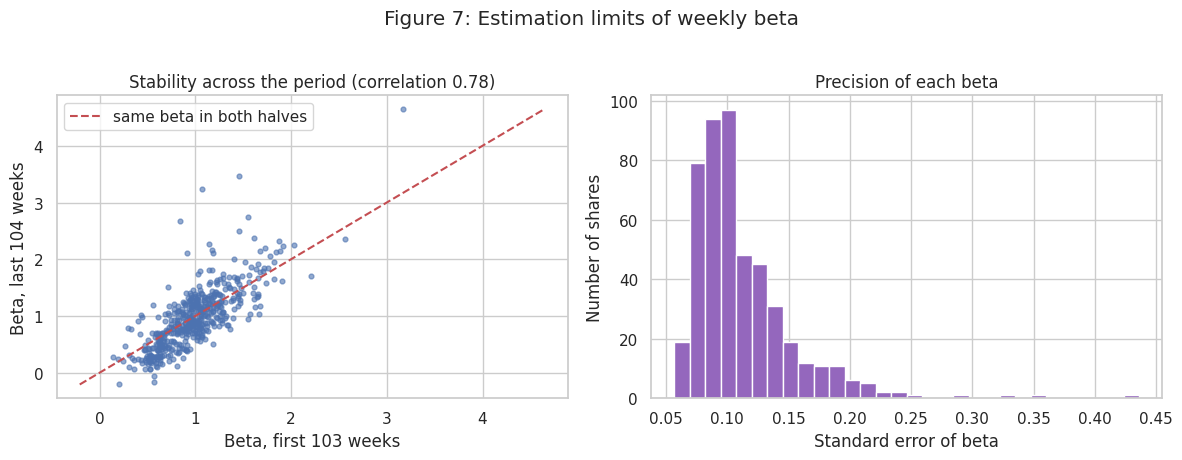

In [ ]:
# Figure 7: how reliable is a weekly beta?
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(b_first, b_last, s=12, alpha=0.6)
lim = [min(b_first.min(), b_last.min()), max(b_first.max(), b_last.max())]
axes[0].plot(lim, lim, "r--", label="same beta in both halves")
axes[0].set(xlabel=f"Beta, first {half} weeks", ylabel=f"Beta, last {n_weeks - half} weeks",
            title=f"Stability across the period (correlation {b_first.corr(b_last):.2f})")
axes[0].legend()
axes[1].hist(se, bins=30, color="tab:purple", edgecolor="white")
axes[1].set(xlabel="Standard error of beta", ylabel="Number of shares", title="Precision of each beta")
plt.suptitle("Figure 7: Estimation limits of weekly beta", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/fig7_beta_reliability.png", dpi=150, bbox_inches="tight"); plt.show()

##  Task 1.4 Adapted RFM (trading activity)



In [ ]:
def high_volume_flags(volume, window=BASE_WINDOW, mult=HIGH_VOL_MULT):
    """Baseline, threshold and event flags for one series or a table of shares."""
    baseline = volume.shift(1).rolling(window, min_periods=window).mean()   # preceding sessions only: shift(1) removes day t
    threshold = mult * baseline                                             # separate for every share and every day
    flags = (volume > threshold) & baseline.notna()                         # strictly greater; no full baseline = no event
    return baseline, threshold, flags

def recency_days(flag_table, obs_date):
    """Calendar days from each column's latest event (on or before obs_date) to obs_date; NaN when there is none."""
    f = flag_table.loc[:obs_date]
    last = pd.to_datetime(f.apply(lambda s: s[s].index.max() if s.any() else pd.NaT))
    return (obs_date - last).dt.days, last

# ---- Tests on small made-up data (the brief's own numbers) ----
def event_on_last_day(x):
    return bool(high_volume_flags(pd.Series([1_000_000.0] * 20 + [x]))[2].iloc[-1])

verify("event rule: 2.5 million against a 1 million baseline qualifies", event_on_last_day(2_500_000.0))
verify("event rule: 1.8 million does not qualify", not event_on_last_day(1_800_000.0))
verify("event rule: exactly twice the baseline does not qualify (strictly greater)", not event_on_last_day(2_000_000.0))
verify("event rule: just above twice the baseline qualifies", event_on_last_day(2_000_001.0))
verify("event rule: nothing can qualify before 20 sessions of history",
       not high_volume_flags(pd.Series([1e6] * 4 + [9e6] + [1e6] * 20))[2].iloc[:20].any())
verify("event rule: a day's own volume does not raise its own threshold",
       np.isclose(high_volume_flags(pd.Series([1e6] * 20 + [50e6]))[1].iloc[-1], 2e6))

days_ = pd.date_range("2024-09-02", "2024-09-20", freq="B")
toy = pd.DataFrame(False, index=days_, columns=["on_obs_date", "two_days_before", "prev_friday", "none"])
toy.loc["2024-09-20", "on_obs_date"] = True
toy.loc["2024-09-18", "two_days_before"] = True
toy.loc["2024-09-13", "prev_friday"] = True
r_toy, _ = recency_days(toy, pd.Timestamp("2024-09-20"))
verify("Recency: an event on the observation date gives 0", r_toy["on_obs_date"] == 0)
verify("Recency: an event two days earlier gives 2", r_toy["two_days_before"] == 2)
verify("Recency: Friday 13 Sep to Friday 20 Sep gives 7 calendar days", r_toy["prev_friday"] == 7)
verify("Recency: a Friday event seen from the next Monday gives 3 (the weekend counts)",
       recency_days(toy, pd.Timestamp("2024-09-16"))[0]["prev_friday"] == 3)
verify("Recency: no event gives a missing value, not 0", np.isnan(r_toy["none"]))

sess_ = pd.date_range("2024-01-01", periods=80, freq="B")
win_ = sess_[-60:]
tf = pd.DataFrame(False, index=sess_, columns=["seven", "first_window_day", "day_before_window"])
tf.loc[win_[[0, 5, 12, 20, 31, 44, 59]], "seven"] = True
tf.loc[win_[0], "first_window_day"] = True
tf.loc[sess_[-61], "day_before_window"] = True
cnt = tf.loc[win_].sum()
verify("Frequency: seven qualifying days give F = 7", cnt["seven"] == 7)
verify("Frequency: the first window day counts and the day before the window does not",
       cnt["first_window_day"] == 1 and cnt["day_before_window"] == 0)

px_ = pd.Series(100.0, index=sess_); vv_ = pd.Series(2_000_000.0, index=sess_)
verify("Monetary: $100 x 2 million shares x 60 sessions = $12 billion", np.isclose((px_ * vv_).iloc[-60:].sum(), 12e9))

PASSED: event rule: 2.5 million against a 1 million baseline qualifies
PASSED: event rule: 1.8 million does not qualify
PASSED: event rule: exactly twice the baseline does not qualify (strictly greater)
PASSED: event rule: just above twice the baseline qualifies
PASSED: event rule: nothing can qualify before 20 sessions of history
PASSED: event rule: a day's own volume does not raise its own threshold
PASSED: Recency: an event on the observation date gives 0
PASSED: Recency: an event two days earlier gives 2
PASSED: Recency: Friday 13 Sep to Friday 20 Sep gives 7 calendar days
PASSED: Recency: a Friday event seen from the next Monday gives 3 (the weekend counts)
PASSED: Recency: no event gives a missing value, not 0
PASSED: Frequency: seven qualifying days give F = 7
PASSED: Frequency: the first window day counts and the day before the window does not
PASSED: Monetary: $100 x 2 million shares x 60 sessions = $12 billion


True

In [ ]:
v, c = vol[keep], close[keep]
complete = v.notna().all(axis=1) & c.notna().all(axis=1) & bench["Close"].reindex(v.index).notna()
observation_date = complete[complete].index.max()
v, c = v.loc[:observation_date], c.loc[:observation_date]
print("Observation date:", observation_date.date())

baseline, threshold, high_volume = high_volume_flags(v)      # preceding 20 sessions, day t excluded

window = v.index[-ACTIVITY_WINDOW:]                       # latest 60 sessions ending on the observation date
assert window[-1] == observation_date and len(window) == ACTIVITY_WINDOW
print("Latest 60 sessions:", window[0].date(), "to", window[-1].date())
print("First date with a full 20-session baseline:", baseline.dropna(how="all").index.min().date())
print("High-volume share-days in the whole history:", int(high_volume.sum().sum()))

Observation date: 2024-12-31
Latest 60 sessions: 2024-10-07 to 2024-12-31
First date with a full 20-session baseline: 2021-02-02
High-volume share-days in the whole history: 18280


In [ ]:
R, last_event = recency_days(high_volume, observation_date)
R = R.rename("R")                 # no event stays missing, never 0
F = high_volume.loc[window].sum().rename("F")
M = (c.loc[window] * v.loc[window]).sum().rename("M")                   # USD

rfm = pd.DataFrame({"Last_HighVol_Date": last_event, "R": R, "F": F, "M": M})
rfm["Baseline_OK_in_Window"] = baseline.loc[window].notna().all()
rfm["Window_Sessions"] = v.loc[window].notna().sum()
display(rfm.head(8))

print("Shares with a full baseline on all 60 window days:", int(rfm["Baseline_OK_in_Window"].sum()), "of", len(rfm))
print("Shares with 60 valid window sessions            :", int((rfm["Window_Sessions"] == 60).sum()), "of", len(rfm))
print("Shares with NO high-volume event (R missing)    :", int(rfm["R"].isna().sum()))
print("Shares with an event on the observation date (R = 0):", int((rfm["R"] == 0).sum()))
print("Shares with F = 0 in the 60-session window      :", int((rfm["F"] == 0).sum()))
print("R range (days):", rfm["R"].min(), "to", rfm["R"].max())

,Last_HighVol_Date,R,F,M,Baseline_OK_in_Window,Window_Sessions
MMM,2024-12-20,11,4,2.599146e+10,True,60
AOS,2024-12-20,11,2,4.748980e+09,True,60
ABT,2024-12-20,11,1,3.523027e+10,True,60
ABBV,2024-12-20,11,3,6.837054e+10,True,60
ACN,2024-12-20,11,2,5.199430e+10,True,60
ADBE,2024-12-13,18,3,1.030403e+11,True,60
AMD,2024-12-13,18,4,3.131659e+11,True,60
AES,2024-11-07,54,3,1.119578e+10,True,60


Shares with a full baseline on all 60 window days: 486 of 486
Shares with 60 valid window sessions            : 486 of 486
Shares with NO high-volume event (R missing)    : 0
Shares with an event on the observation date (R = 0): 0
Shares with F = 0 in the 60-session window      : 10
R range (days): 4 to 222


In [ ]:
# Independent verification of the flags and of R, F and M (plain loops and numpy, separate from the pandas code above)
# 1. No look-ahead: making all later volumes ten times larger must not change any earlier flag
cut = len(v) // 2
later = v.copy(); later.iloc[cut:] = later.iloc[cut:] * 10
verify("no look-ahead: changing later volumes changes no earlier flag", high_volume.iloc[:cut].equals(high_volume_flags(later)[2].iloc[:cut]))

# 2. Recency by a plain loop, for every share
for s_ in v.columns:
    ev_days = high_volume.index[high_volume[s_].to_numpy()]
    expected = (observation_date - ev_days.max()).days if len(ev_days) else np.nan
    assert (np.isnan(expected) and np.isnan(R[s_])) or expected == R[s_], s_
print("PASSED: Recency matches a plain-loop recalculation for every share")

# 3. Frequency from raw volumes with an explicit 20-session mean, and Monetary with numpy
V = v.to_numpy()
manual_F = np.zeros(V.shape[1], dtype=int)
for d_ in window:
    i_ = v.index.get_loc(d_)
    manual_F += (V[i_] > HIGH_VOL_MULT * V[i_ - BASE_WINDOW:i_].mean(axis=0))
verify("Frequency matches an independent recalculation from raw volumes", (manual_F == F.to_numpy()).all())
verify("Monetary matches an independent positional recalculation", np.allclose(M.to_numpy(), (c.to_numpy()[-ACTIVITY_WINDOW:] * V[-ACTIVITY_WINDOW:]).sum(axis=0)))

# 4. Consistency between R and F, and the window boundary
span = (observation_date - window[0]).days
has_event = R.notna()
verify(f"Frequency is above 0 exactly when the latest event is inside the window (span {span} days)",
       ((F[has_event] > 0) == (R[has_event] <= span)).all())
F61 = high_volume.iloc[-(ACTIVITY_WINDOW + 1):].sum()
print("Shares whose Frequency would change with a 61-session window (boundary sensitivity):", int((F61 != F).sum()))

# 5. Why Close (not Adj Close) for Monetary
ratio = (adj[keep].loc[window] * v.loc[window]).sum() / M
print(f"If Adj Close were used for Monetary, traded value would be understated by a median of "
      f"{100 * (1 - ratio.median()):.1f}% (up to {100 * (1 - ratio.min()):.1f}%)")

high_volume.astype(int).to_csv(f"{DATA}/high_volume_flags.csv")       # reproducible event flags
print("Saved high_volume_flags.csv")

PASSED: no look-ahead: changing later volumes changes no earlier flag
PASSED: Recency matches a plain-loop recalculation for every share
PASSED: Frequency matches an independent recalculation from raw volumes
PASSED: Monetary matches an independent positional recalculation
PASSED: Frequency is above 0 exactly when the latest event is inside the window (span 85 days)
Shares whose Frequency would change with a 61-session window (boundary sensitivity): 2
If Adj Close were used for Monetary, traded value would be understated by a median of 2.9% (up to 13.1%)
Saved high_volume_flags.csv


In [ ]:
# How concentrated are the latest events? (interpretation evidence for Recency)
ev = last_event.value_counts().rename("Shares").to_frame()
ev["Weekday"] = ev.index.day_name()
ev["R_days"] = (observation_date - ev.index).days
ev["Share_of_shares_%"] = (100 * ev["Shares"] / len(rfm)).round(1)
print("Most common latest high-volume dates:")
print(ev.head(6).to_string())

daily_flagged = high_volume.loc[window].sum(axis=1)
print("\nSessions in the 60-session window with most shares flagged:")
print(daily_flagged.sort_values(ascending=False).head(5).to_string())

Most common latest high-volume dates:
            Shares    Weekday  R_days  Share_of_shares_%
2024-12-20     353     Friday      11               72.6
2024-11-25      17     Monday      36                3.5
2024-11-06      11  Wednesday      55                2.3
2024-11-01       6     Friday      60                1.2
2024-11-15       6     Friday      46                1.2
2024-12-04       5  Wednesday      27                1.0

Sessions in the 60-session window with most shares flagged:
Date
2024-12-20    354
2024-11-06    156
2024-10-31     83
2024-11-25     76
2024-10-30     46


In [ ]:
# Worked RFM example for one share
ex = t
example = pd.DataFrame({"Close": c.loc[window, ex], "Volume": v.loc[window, ex],
                        "Prev20_Mean_Volume": baseline.loc[window, ex], "Threshold_2x": threshold.loc[window, ex],
                        "High_Volume_Day": high_volume.loc[window, ex],
                        "Close_x_Volume_USD": c.loc[window, ex] * v.loc[window, ex]})
print(f"Worked example: {ex} ({sp500.set_index('Ticker').loc[ex, 'Security']}) | observation date {observation_date.date()}")
print(f"Window: {window[0].date()} to {window[-1].date()} (60 sessions)\n")
print("High-volume days in the window:")
print(example[example["High_Volume_Day"]].round(2).to_string() if example["High_Volume_Day"].any() else "  none")

e = rfm.loc[ex, "Last_HighVol_Date"]
if pd.notna(e):
    pos = v.index.get_loc(e)
    prev20 = v[ex].iloc[pos - BASE_WINDOW:pos]
    print(f"\nR: latest high-volume day {e.date()} -> {observation_date.date()} - {e.date()} = {int(rfm.loc[ex, 'R'])} calendar days")
    print(f"   check: volume {v.loc[e, ex]:,.0f} > 2 x {prev20.mean():,.0f} (mean of {prev20.index[0].date()} to {prev20.index[-1].date()}) = {2 * prev20.mean():,.0f}")
print(f"F: {int(example['High_Volume_Day'].sum())} qualifying days of 60 (code: {int(rfm.loc[ex, 'F'])})")
print(f"M: sum of 60 daily Close x Volume = ${example['Close_x_Volume_USD'].sum():,.0f} (code: ${rfm.loc[ex, 'M']:,.0f})")
example.to_csv(f"{DATA}/worked_rfm_example_{ex}.csv")

Worked example: AAPL (Apple Inc.) | observation date 2024-12-31
Window: 2024-10-07 to 2024-12-31 (60 sessions)

High-volume days in the window:
             Close     Volume  Prev20_Mean_Volume  Threshold_2x  High_Volume_Day  Close_x_Volume_USD
Date                                                                                                
2024-11-25  232.87   90152800          43820740.0    87641480.0             True        2.099388e+10
2024-12-20  254.49  147495300          45004605.0    90009210.0             True        3.753608e+10

R: latest high-volume day 2024-12-20 -> 2024-12-31 - 2024-12-20 = 11 calendar days
   check: volume 147,495,300 > 2 x 45,004,605 (mean of 2024-11-21 to 2024-12-19) = 90,009,210
F: 2 qualifying days of 60 (code: 2)
M: sum of 60 daily Close x Volume = $623,303,377,707 (code: $623,303,377,707)


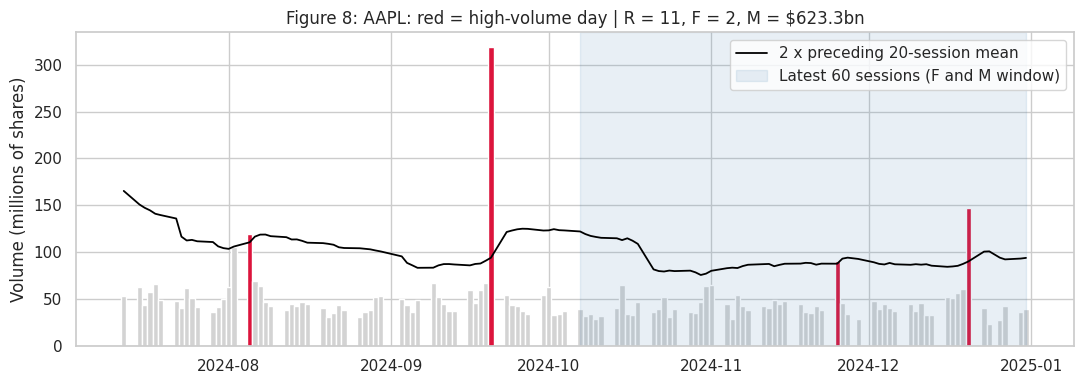

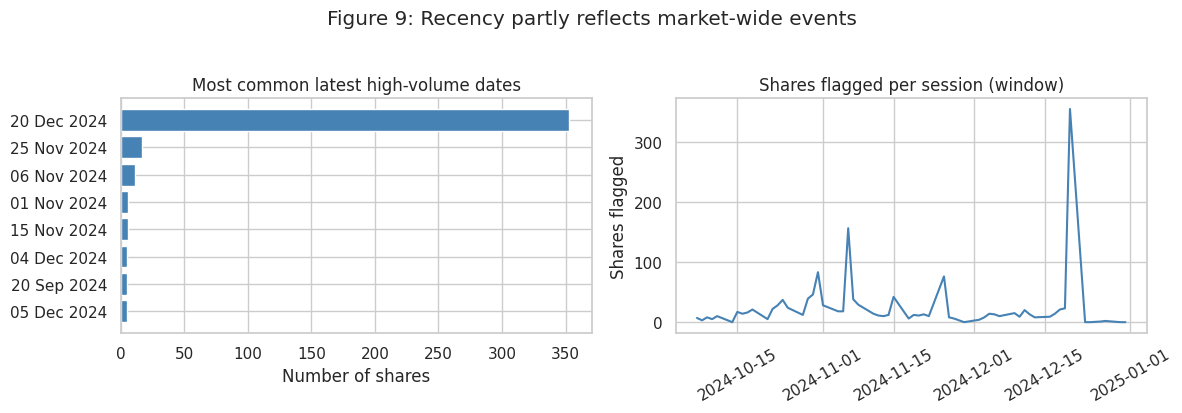

In [ ]:
# Figure 8: worked example. Figure 9: how concentrated the latest events are
w = pd.DataFrame({"Volume": v[ex], "Threshold": threshold[ex], "Flag": high_volume[ex]}).iloc[-120:]
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(w.index, w["Volume"] / 1e6, color=np.where(w["Flag"], "crimson", "lightgrey"), width=1.0)
ax.plot(w.index, w["Threshold"] / 1e6, color="black", lw=1.3, label="2 x preceding 20-session mean")
ax.axvspan(window[0], window[-1], color="steelblue", alpha=0.12, label="Latest 60 sessions (F and M window)")
ax.set_ylabel("Volume (millions of shares)")
ax.set_title(f"Figure 8: {ex}: red = high-volume day | R = {int(rfm.loc[ex, 'R'])}, F = {int(rfm.loc[ex, 'F'])}, M = ${rfm.loc[ex, 'M'] / 1e9:,.1f}bn")
ax.legend(loc="upper right"); plt.tight_layout()
plt.savefig(f"{FIG}/fig8_rfm_example.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top = ev.head(8).copy(); top.index = top.index.strftime("%d %b %Y")
axes[0].barh(top.index[::-1], top["Shares"][::-1], color="steelblue")
axes[0].set_xlabel("Number of shares"); axes[0].set_title("Most common latest high-volume dates")
axes[1].plot(daily_flagged.index, daily_flagged.values, color="steelblue")
axes[1].set_title("Shares flagged per session (window)"); axes[1].set_ylabel("Shares flagged")
axes[1].tick_params(axis="x", rotation=30)
plt.suptitle("Figure 9: Recency partly reflects market-wide events", y=1.03); plt.tight_layout()
plt.savefig(f"{FIG}/fig9_recency_events.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Task 1.5 Feature table, summaries and inclusion/exclusion log

One row per retained share. Shares with a missing R (no high volume event) stay in the table but are flagged.
The **common valid set** is used for both clustering matrices in Task 2, so every solution is compared on the same shares.

In [ ]:
features = (sp500.set_index("Ticker").loc[keep, ["Security", "Sector"]]
            .join(mean_ret).join(beta_df.rename(columns={"Beta": "Weekly_Beta", "Paired_weeks": "Paired_Weeks"}))
            .join(rfm[["Last_HighVol_Date", "R", "F", "M"]]))
features["log1p_M"] = np.log1p(features["M"])
features["RiskReturn_Valid"] = features[["Mean_Weekly_Return", "Weekly_Beta"]].notna().all(axis=1)
features["RFM_Valid"] = features[["R", "F", "M"]].notna().all(axis=1)
features["Common_Valid"] = features["RiskReturn_Valid"] & features["RFM_Valid"]
features["Observation_Date"] = observation_date.date()
features["Return_Window"] = f"{wk_ret.index.min().date()} to {wk_ret.index.max().date()} (week labels)"
features["RFM_Window"] = f"{window[0].date()} to {window[-1].date()} (60 sessions)"
features.to_csv(f"{DATA}/feature_table_task1.csv")

FEATS = ["Mean_Weekly_Return", "Weekly_Beta", "R", "F", "M"]
common = features[features["Common_Valid"]].copy()
common.to_csv(f"{DATA}/feature_table_common.csv")
pd.Series(common.index, name="Ticker").to_csv(f"{DATA}/common_valid_shares.csv", index=False)

summary = common[FEATS + ["log1p_M"]].astype(float).describe(percentiles=[.05, .25, .5, .75, .95]).T
summary["skew"] = common[FEATS + ["log1p_M"]].astype(float).skew()
summary.to_csv(f"{DATA}/feature_summary_task1.csv")
print("Feature table rows:", len(features), "| common valid share set:", len(common))
display(summary.round(4))
display(features.head(8))

Feature table rows: 486 | common valid share set: 486


,count,mean,std,min,5%,25%,50%,75%,95%,max,skew
Mean_Weekly_Return,486.0,2.900000e-03,2.700000e-03,-4.500000e-03,-1.100000e-03,1.200000e-03,2.600000e-03,4.200000e-03,7.600000e-03,1.780000e-02,0.8675
Weekly_Beta,486.0,9.737000e-01,4.073000e-01,5.550000e-02,4.107000e-01,6.666000e-01,9.506000e-01,1.179500e+00,1.687100e+00,3.778600e+00,1.1036
R,486.0,2.040740e+01,2.134240e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.100000e+01,1.475000e+01,6.000000e+01,2.220000e+02,3.6458
F,486.0,2.989700e+00,1.330800e+00,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00,8.000000e+00,0.4247
M,486.0,3.940419e+10,1.291388e+11,1.297483e+09,5.683635e+09,1.019517e+10,1.668382e+10,3.227689e+10,9.654508e+10,1.847697e+12,11.6838
log1p_M,486.0,2.368210e+01,9.422000e-01,2.098370e+01,2.246090e+01,2.304520e+01,2.353770e+01,2.419760e+01,2.529310e+01,2.824500e+01,1.0791


,Security,Sector,Mean_Weekly_Return,Weekly_Beta,Paired_Weeks,Last_HighVol_Date,R,F,M,log1p_M,RiskReturn_Valid,RFM_Valid,Common_Valid,Observation_Date,Return_Window,RFM_Window
Ticker,,,,,,,,,,,,,,,,
MMM,3M,Industrials,0.001142,0.869079,207,2024-12-20,11,4,2.599146e+10,23.981034,True,True,True,2024-12-31,2021-01-15 to 2024-12-27 (week labels),2024-10-07 to 2024-12-31 (60 sessions)
AOS,A. O. Smith,Industrials,0.001991,1.042805,207,2024-12-20,11,2,4.748980e+09,22.281196,True,True,True,2024-12-31,2021-01-15 to 2024-12-27 (week labels),2024-10-07 to 2024-12-31 (60 sessions)
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,207,2024-12-20,11,1,3.523027e+10,24.285172,True,True,True,2024-12-31,2021-01-15 to 2024-12-27 (week labels),2024-10-07 to 2024-12-31 (60 sessions)
ABBV,AbbVie,Health Care,0.003749,0.425366,207,2024-12-20,11,3,6.837054e+10,24.948208,True,True,True,2024-12-31,2021-01-15 to 2024-12-27 (week labels),2024-10-07 to 2024-12-31 (60 sessions)
ACN,Accenture,Information Technology,0.002376,1.143300,207,2024-12-20,11,2,5.199430e+10,24.674400,True,True,True,2024-12-31,2021-01-15 to 2024-12-27 (week labels),2024-10-07 to 2024-12-31 (60 sessions)
ADBE,Adobe Inc.,Information Technology,0.000990,1.553525,207,2024-12-13,18,3,1.030403e+11,25.358386,True,True,True,2024-12-31,2021-01-15 to 2024-12-27 (week labels),2024-10-07 to 2024-12-31 (60 sessions)
AMD,Advanced Micro Devices,Information Technology,0.003624,1.877622,207,2024-12-13,18,4,3.131659e+11,26.469999,True,True,True,2024-12-31,2021-01-15 to 2024-12-27 (week labels),2024-10-07 to 2024-12-31 (60 sessions)
AES,AES Corporation,Utilities,-0.001420,1.143912,207,2024-11-07,54,3,1.119578e+10,23.138803,True,True,True,2024-12-31,2021-01-15 to 2024-12-27 (week labels),2024-10-07 to 2024-12-31 (60 sessions)


In [ ]:
# Inclusion and exclusion log: every ticker on the Wikipedia list
inc = log[["Security", "Sector", "First_Date", "Last_Date", "Missing_Internal", "Split_Events",
           "Dividend_Events", "Included", "Exclusion_Reason"]].copy()
inc = inc.join(features[["RFM_Valid", "Common_Valid"]])
inc["RFM_Valid"] = inc["RFM_Valid"].eq(True)
inc["Common_Valid"] = inc["Common_Valid"].eq(True)
no_event = inc["Included"] & ~inc["RFM_Valid"]
inc.loc[no_event, "Exclusion_Reason"] = "RFM: no high-volume day in study history (R missing): excluded from clustering"
inc.to_csv(f"{DATA}/inclusion_exclusion_log.csv")

stages = pd.Series({
    "1. Tickers on the Wikipedia list": len(tickers),
    "2. Data returned by Yahoo (V1)": int((~inc["Exclusion_Reason"].str.startswith("V1")).sum()),
    "3. Passed validation rules V1 to V6": len(keep),
    "4. Valid mean return and beta": int(features["RiskReturn_Valid"].sum()),
    "5. Valid R, F and M, the common valid set": len(common)})
print(stages.to_string())
print("\nShares not in the clustering set, by sector:")
print(inc.loc[~inc["Common_Valid"], "Sector"].value_counts().to_string())

1. Tickers on the Wikipedia list             503
2. Data returned by Yahoo (V1)               498
3. Passed validation rules V1 to V6          486
4. Valid mean return and beta                486
5. Valid R, F and M, the common valid set    486

Shares not in the clustering set, by sector:
Sector
Industrials               5
Communication Services    2
Financials                2
Information Technology    2
Health Care               2
Energy                    1
Utilities                 1
Materials                 1
Consumer Staples          1


In [ ]:
# One summary table of every check, for the report
rc = lambda k: int(rule_counts.get(k, 0))
validation_summary = pd.DataFrame([
    ("Constituent list retrieved", sp500["Retrieved"].iloc[0]),
    ("Prices downloaded", meta["downloaded_utc"]),
    ("Tickers on the Wikipedia list", len(tickers)),
    ("Excluded V1: no data returned", rc("V1")),
    ("Excluded V2: incomplete history", rc("V2")),
    ("Excluded V3: missing sessions inside history", rc("V3")),
    ("Excluded V4: nonpositive price", rc("V4")),
    ("Excluded V5: zero or negative volume", rc("V5")),
    ("Excluded V6: Close jumps on a split date", rc("V6")),
    ("Shares passing validation", len(keep)),
    ("Duplicate dates on the benchmark calendar", int(bench.index.duplicated().sum())),
    ("Retained shares: missing sessions", int(ret["Missing_Sessions"].sum())),
    ("Retained shares: nonpositive prices", int(ret["Nonpositive_Price_Days"].sum())),
    ("Retained shares: zero or negative volume days", int(ret["Nonpositive_Volume_Days"].sum())),
    ("Split events among retained shares", int(ret["Split_Events"].sum())),
    ("Ordinary splits with Volume that looks unadjusted", int(tested["Looks_unadjusted"].sum())),
    ("Adj/Close factor changes not on a dividend or split date", int(ret["Factor_Changes_Unexplained"].sum())),
    ("Aligned weekly return observations per share", len(wk_ret)),
    ("Observation date", str(observation_date.date())),
    ("60-session window", f"{window[0].date()} to {window[-1].date()}"),
    ("High-volume share-days flagged (whole history)", int(high_volume.sum().sum())),
    ("Shares with no high-volume event (R missing)", int(R.isna().sum())),
    ("Shares with Frequency = 0", int((F == 0).sum())),
    ("Shares in the common valid set", len(common)),
], columns=["Check", "Result"])
validation_summary.to_csv(f"{DATA}/validation_summary.csv", index=False)
display(validation_summary)

,Check,Result
0,Constituent list retrieved,2026-11-20 08:32 UTC
1,Prices downloaded,2026-11-20 08:34 UTC
2,Tickers on the Wikipedia list,503
3,Excluded V1: no data returned,5
4,Excluded V2: incomplete history,10
5,Excluded V3: missing sessions inside history,0
6,Excluded V4: nonpositive price,0
7,Excluded V5: zero or negative volume,2
8,Excluded V6: Close jumps on a split date,0
9,Shares passing validation,486


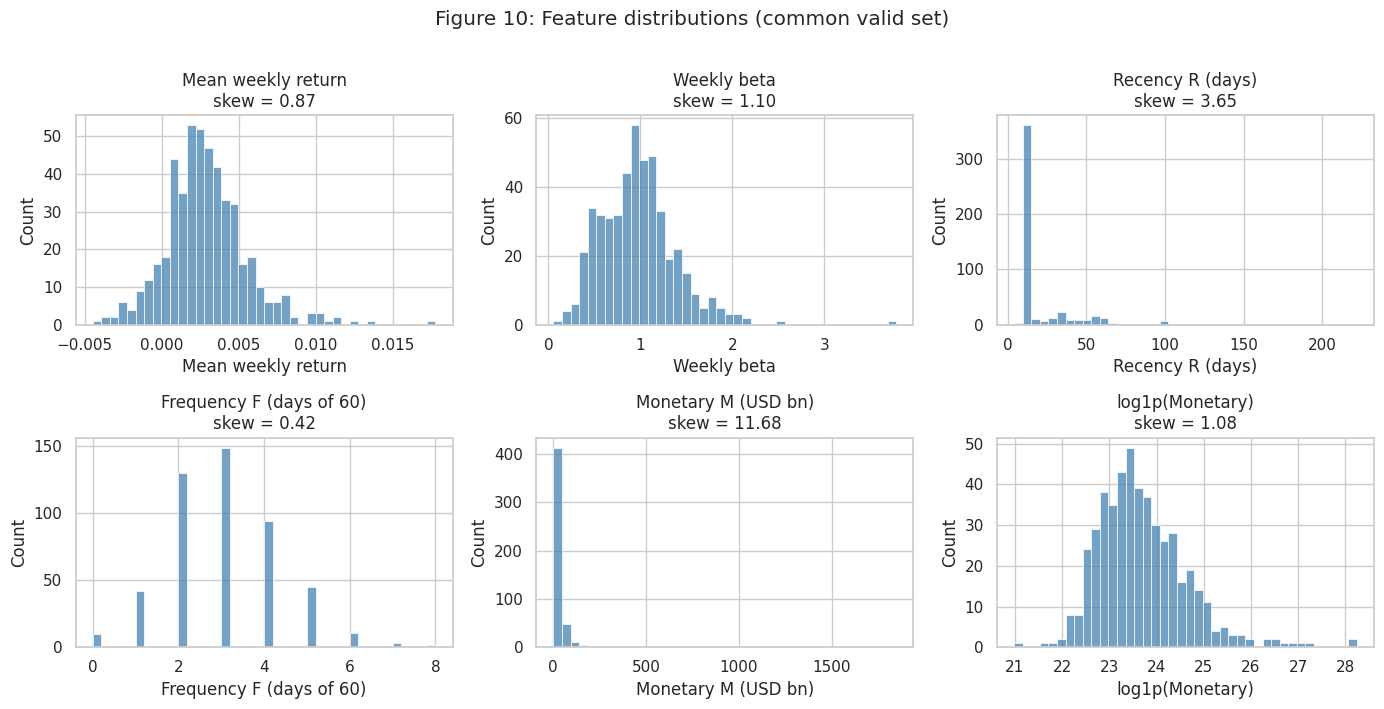

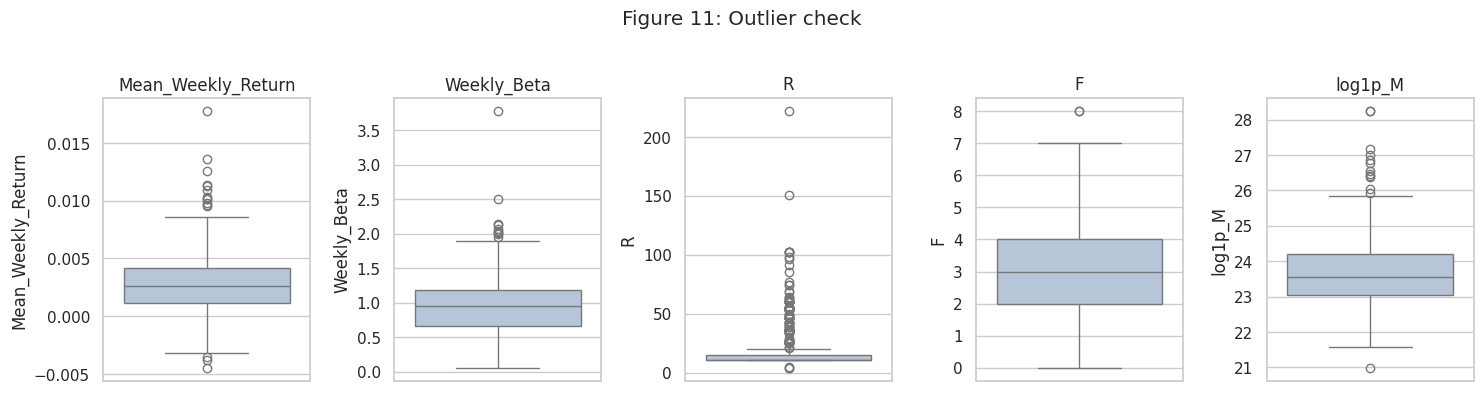

In [ ]:
# Figure 10: distributions. Figure 11: outliers. (Evidence for the log1p transform in Task 2.1)
plots = [("Mean_Weekly_Return", "Mean weekly return"), ("Weekly_Beta", "Weekly beta"), ("R", "Recency R (days)"),
         ("F", "Frequency F (days of 60)"), ("M", "Monetary M (USD bn)"), ("log1p_M", "log1p(Monetary)")]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, label) in zip(axes.ravel(), plots):
    vals = common[col].astype(float) / (1e9 if col == "M" else 1)
    sns.histplot(vals, bins=40, ax=ax, color="steelblue")
    ax.set_title(f"{label}\nskew = {common[col].astype(float).skew():.2f}"); ax.set_xlabel(label)
plt.suptitle("Figure 10: Feature distributions (common valid set)", y=1.01); plt.tight_layout()
plt.savefig(f"{FIG}/fig10_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(15, 3.8))
for ax, col in zip(axes, ["Mean_Weekly_Return", "Weekly_Beta", "R", "F", "log1p_M"]):
    sns.boxplot(y=common[col].astype(float), ax=ax, color="lightsteelblue"); ax.set_title(col)
plt.suptitle("Figure 11: Outlier check", y=1.03); plt.tight_layout()
plt.savefig(f"{FIG}/fig11_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

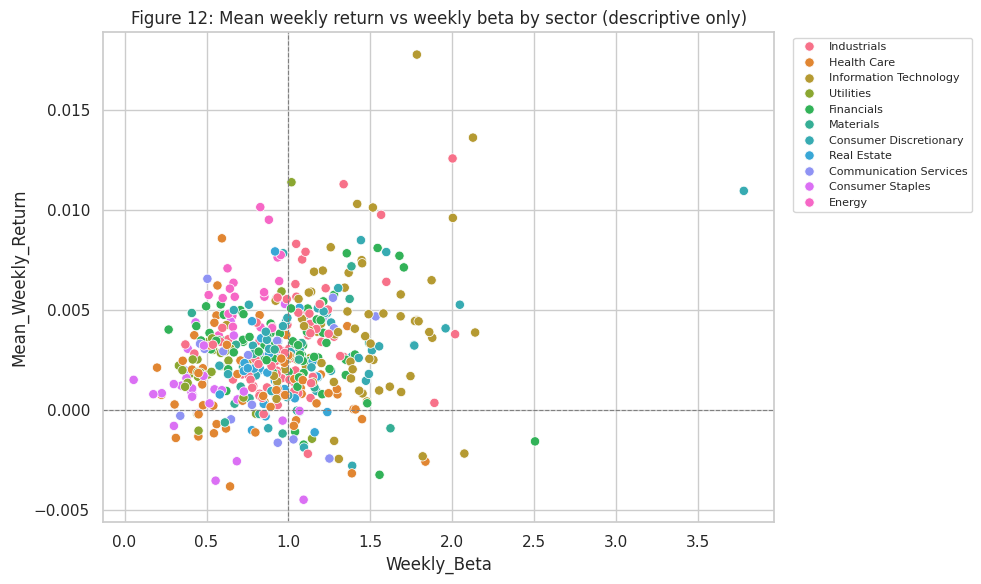

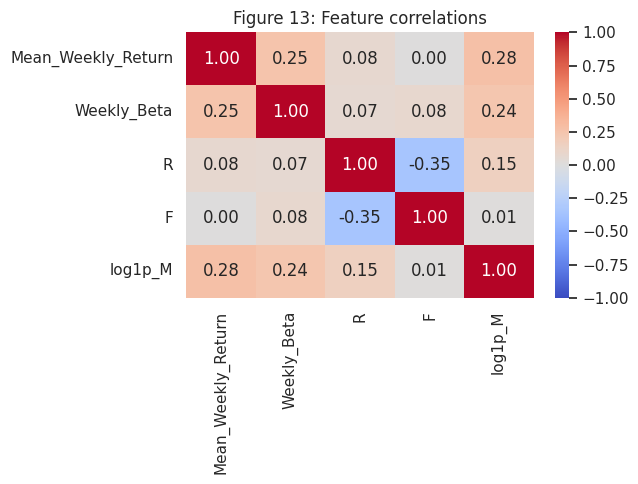

R, F, log1p(M) correlation block (reused in Task 2.5.1):


,R,F,log1p_M
R,1.000,-0.346,0.152
F,-0.346,1.000,0.013
log1p_M,0.152,0.013,1.000


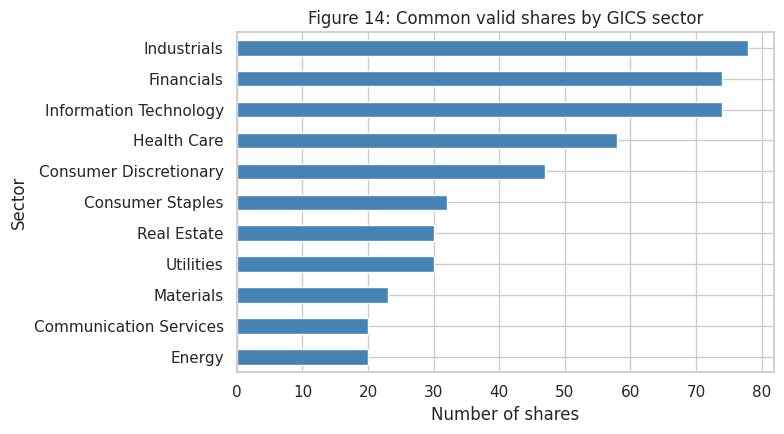

In [ ]:
# Figure 12: beta vs mean return by sector. Figure 13: correlations. Figure 14: shares by sector
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=common, x="Weekly_Beta", y="Mean_Weekly_Return", hue="Sector", s=45, ax=ax)
ax.axvline(1, color="grey", ls="--", lw=0.8); ax.axhline(0, color="grey", ls="--", lw=0.8)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
ax.set_title("Figure 12: Mean weekly return vs weekly beta by sector (descriptive only)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig12_beta_vs_return.png", dpi=150); plt.show()

corr = common[["Mean_Weekly_Return", "Weekly_Beta", "R", "F", "log1p_M"]].astype(float).corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Figure 13: Feature correlations"); plt.tight_layout()
plt.savefig(f"{FIG}/fig13_correlations.png", dpi=150); plt.show()
print("R, F, log1p(M) correlation block (reused in Task 2.5.1):")
display(corr.loc[["R", "F", "log1p_M"], ["R", "F", "log1p_M"]].round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
common["Sector"].value_counts().sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("Number of shares"); ax.set_title("Figure 14: Common valid shares by GICS sector")
plt.tight_layout(); plt.savefig(f"{FIG}/fig14_sectors.png", dpi=150); plt.show()

### Metric interpretation and limits as investment signals

In [ ]:
# Provenance README, then zip everything for the public GitHub repository
with open(f"{DATA}/README_task1.txt", "w") as f:
    f.write(f"Ticker list: {WIKI_URL} (retrieved {sp500['Retrieved'].iloc[0]})\n")
    f.write(f"Prices: {meta['source']}, downloaded {meta['downloaded_utc']}, auto_adjust=False, actions=True\n")
    f.write(f"Period: {START} to {END} (end exclusive); benchmark {BENCH}\n")
    f.write(f"Weekly returns: W-FRI, last available Adj Close, {len(wk_ret)} returns, {wk_ret.index.min().date()} to {wk_ret.index.max().date()}\n")
    f.write(f"Observation date: {observation_date.date()} | RFM window: {window[0].date()} to {window[-1].date()}\n")
    f.write(f"High-volume rule: volume > {HIGH_VOL_MULT} x mean of preceding {BASE_WINDOW} sessions (current day excluded)\n")
    f.write(f"Shares: {len(tickers)} listed, {len(keep)} validated, {len(common)} in the common valid set\n")
    f.write(f"Versions: {json.dumps(VERSIONS)}\n")
    f.write("File hashes: see price_metadata.json\n")
print("Task 1 README saved. The zip and download happen in the last cell of the notebook, after Task 2.")

Task 1 README saved. The zip and download happen in the last cell of the notebook, after Task 2.


# Task 2: Stock Segmentation and Sensitivity Analysis

In [ ]:
!pip install -q scikit-learn scipy

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from scipy.optimize import linear_sum_assignment
from scipy.stats import kruskal
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
import sklearn

SEED = 42                  # one random seed for everything in Task 2
K_RANGE = range(2, 9)      # feasible cluster counts from the brief
N_INIT = 50                # K-means: number of random initialisations
MIN_CLUSTER_FRAC = 0.05    # my rule: a cluster smaller than 5% of the shares is too small to profile
INPUT = f"{DATA}/feature_table_common.csv"
assert os.path.exists(INPUT), f"{INPUT} not found: run section 5 (the Task 1 feature table) first"

VERSIONS = {**VERSIONS, "scikit-learn": sklearn.__version__}
json.dump(VERSIONS, open(f"{DATA}/package_versions_task2.json", "w"), indent=2)
print(VERSIONS)

common = pd.read_csv(INPUT, index_col=0)           # the common valid share set from Task 1
common["log1p_M"] = np.log1p(common["M"])           # the transform the brief requires for Monetary
RR  = ["Mean_Weekly_Return", "Weekly_Beta"]          # risk and return matrix
ACT = ["R", "F", "log1p_M"]                          # trading activity matrix
FIVE = ["Mean_Weekly_Return", "Weekly_Beta", "R", "F", "M"]
print("Shares in the common valid set:", len(common))
display(common[FIVE + ["log1p_M", "Sector"]].head())

{'python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'yfinance': '0.2.66', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'scipy': '1.16.3', 'requests': '2.32.4', 'scikit-learn': '1.6.1'}
Shares in the common valid set: 486


,Mean_Weekly_Return,Weekly_Beta,R,F,M,log1p_M,Sector
Ticker,,,,,,,
MMM,0.001142,0.869079,11,4,2.599146e+10,23.981034,Industrials
AOS,0.001991,1.042805,11,2,4.748980e+09,22.281196,Industrials
ABT,0.000971,0.583543,11,1,3.523027e+10,24.285172,Health Care
ABBV,0.003749,0.425366,11,3,6.837054e+10,24.948208,Health Care
ACN,0.002376,1.143300,11,2,5.199430e+10,24.674400,Information Technology


##  Task 2.1 Feature preparation

* **Two separate matrices** on the same shares: risk and return (mean weekly return, weekly beta) and trading activity (R, F, log1p(M)).
* **log1p(M)** because traded value is extremely right-skewed.
* **Standardise each matrix separately** (z-scores), so no feature dominates only because of its units.
* **Other variables:** R and F are checked below. The evidence is shown, and **you decide and justify** whether to transform them. The brief only requires log1p for M.
* Standard scaling is sensitive to outliers, so the outlier counts below matter. A sensitivity check follows once the clusters are fitted.

In [ ]:
verify("no missing values in the five features", common[FIVE].notna().all().all())
verify("no infinite values", np.isfinite(common[FIVE + ["log1p_M"]].to_numpy()).all())
verify("R, F and M are non-negative", (common[["R", "F", "M"]] >= 0).all().all())

def diagnose(s):
    z = (s - s.mean()) / s.std(ddof=0)
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return {"skew": s.skew(), "excess_kurtosis": s.kurt(), "max_abs_z": z.abs().max(),
            "n_abs_z_gt_3": int((z.abs() > 3).sum()),
            "n_outside_1.5IQR": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())}

candidates = {"Mean_Weekly_Return": common["Mean_Weekly_Return"], "Weekly_Beta": common["Weekly_Beta"],
              "R": common["R"], "log1p(R)": np.log1p(common["R"]),
              "F": common["F"], "log1p(F)": np.log1p(common["F"]),
              "M": common["M"], "log1p_M": common["log1p_M"]}
skew_table = pd.DataFrame({k: diagnose(v) for k, v in candidates.items()}).T
skew_table.to_csv(f"{DATA}/t2_skew_outlier_diagnostics.csv")
display(skew_table.round(3))

print("Most extreme shares (largest |z|) for each clustering feature:")
for col in RR + ACT:
    z = ((common[col] - common[col].mean()) / common[col].std(ddof=0)).abs().sort_values(ascending=False)
    print(f"  {col:20s}", ", ".join(f"{t} ({z[t]:.1f})" for t in z.index[:4]))

PASSED: no missing values in the five features
PASSED: no infinite values
PASSED: R, F and M are non-negative


,skew,excess_kurtosis,max_abs_z,n_abs_z_gt_3,n_outside_1.5IQR
Mean_Weekly_Return,0.868,3.019,5.631,6.0,15.0
Weekly_Beta,1.104,4.471,6.893,2.0,10.0
R,3.646,21.004,9.455,11.0,115.0
log1p(R),1.583,1.429,4.216,2.0,113.0
F,0.425,0.545,3.769,5.0,2.0
log1p(F),-0.928,1.889,3.576,10.0,10.0
M,11.684,155.513,14.017,5.0,45.0
log1p_M,1.079,2.691,4.848,7.0,13.0


Most extreme shares (largest |z|) for each clustering feature:
  Mean_Weekly_Return   SMCI (5.6), NVDA (4.1), VRT (3.7), VST (3.2)
  Weekly_Beta          CVNA (6.9), XYZ (3.8), COHR (2.9), NVDA (2.8)
  R                    NVDA (9.5), WEC (6.1), DUK (3.8), CB (3.8)
  F                    CI (3.8), HSY (3.8), UNH (3.0), XEL (3.0)
  log1p_M              TSLA (4.8), NVDA (4.8), AAPL (3.7), MSFT (3.5)


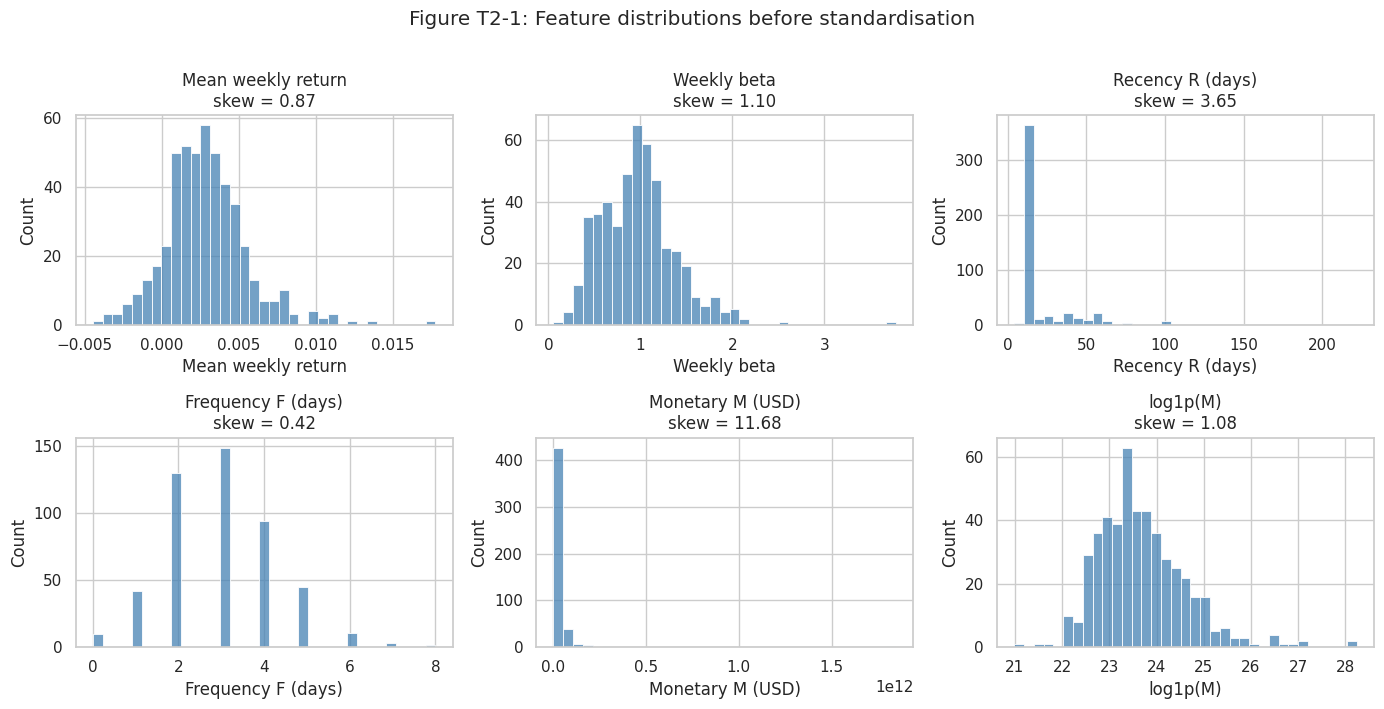

In [ ]:
# Figure T2-1: distributions. The first three show why M is log-transformed.
plots = [("Mean_Weekly_Return", "Mean weekly return"), ("Weekly_Beta", "Weekly beta"), ("R", "Recency R (days)"),
         ("F", "Frequency F (days)"), ("M", "Monetary M (USD)"), ("log1p_M", "log1p(M)")]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, label) in zip(axes.ravel(), plots):
    sns.histplot(common[col], bins=35, ax=ax, color="steelblue")
    ax.set_title(f"{label}\nskew = {common[col].skew():.2f}"); ax.set_xlabel(label)
plt.suptitle("Figure T2-1: Feature distributions before standardisation", y=1.01); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig1_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

PASSED: both matrices contain exactly the same shares in the same order
PASSED: standardised features have mean 0 and standard deviation 1
Matrix shapes: (486, 2) (486, 3)


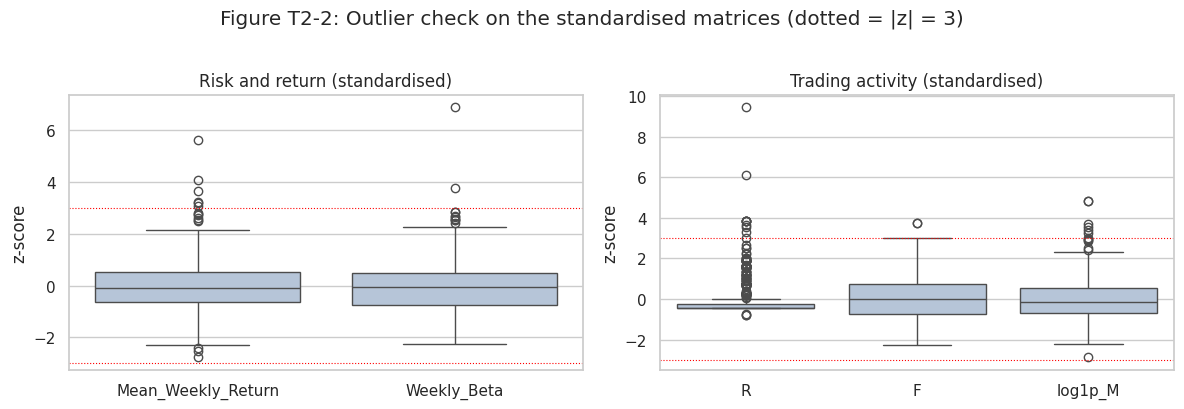

In [ ]:
# Standardise each matrix separately
def standardise(df):
    sc = StandardScaler()
    return pd.DataFrame(sc.fit_transform(df), index=df.index, columns=df.columns), sc

Z_rr, sc_rr = standardise(common[RR])
Z_act, sc_act = standardise(common[ACT])
verify("both matrices contain exactly the same shares in the same order", Z_rr.index.equals(Z_act.index))
verify("standardised features have mean 0 and standard deviation 1",
       np.allclose(pd.concat([Z_rr, Z_act], axis=1).mean(), 0, atol=1e-9) and np.allclose(pd.concat([Z_rr, Z_act], axis=1).std(ddof=0), 1))
Z_rr.to_csv(f"{DATA}/t2_matrix_risk_return_standardised.csv"); Z_act.to_csv(f"{DATA}/t2_matrix_activity_standardised.csv")
common[RR].to_csv(f"{DATA}/t2_matrix_risk_return_raw.csv"); common[ACT].to_csv(f"{DATA}/t2_matrix_activity_raw.csv")
print("Matrix shapes:", Z_rr.shape, Z_act.shape)

# Figure T2-2: how far do standardised values reach? (outliers pull standard scaling)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=Z_rr, ax=axes[0], color="lightsteelblue"); axes[0].set_title("Risk and return (standardised)")
sns.boxplot(data=Z_act, ax=axes[1], color="lightsteelblue"); axes[1].set_title("Trading activity (standardised)")
for ax in axes:
    ax.axhline(3, color="red", ls=":", lw=0.8); ax.axhline(-3, color="red", ls=":", lw=0.8); ax.set_ylabel("z-score")
plt.suptitle("Figure T2-2: Outlier check on the standardised matrices (dotted = |z| = 3)", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig2_standardised_boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

PASSED: the baseline version reproduces the standardised activity matrix
PASSED: every standardised feature has the same total variance (equal total weight)
How each feature is spread after standardising (top-5 share = how much of the feature's squared z-scores come from only 5 shares):


,version,feature,skew,IQR_in_z_units,max_abs_z,top5_share_of_squared_z_%
0,"baseline: R, F, log1p(M)",R,3.65,0.18,9.46,35.16
1,"baseline: R, F, log1p(M)",F,0.42,1.50,3.77,11.46
2,"baseline: R, F, log1p(M)",M,1.08,1.22,4.85,17.38
3,raw M instead of log1p(M),R,3.65,0.18,9.46,35.16
4,raw M instead of log1p(M),F,0.42,1.50,3.77,11.46
5,raw M instead of log1p(M),M,11.68,0.17,14.02,89.39
6,log1p also on R,R,1.58,0.44,4.22,11.73
7,log1p also on R,F,0.42,1.50,3.77,11.46
8,log1p also on R,M,1.08,1.22,4.85,17.38



How the distances and the Ward clusters change (silhouettes are not compared: each version is measured in its own space):


,version,k,distance_rank_corr_vs_baseline,ARI_vs_baseline,smallest_cluster_%
0,"baseline: R, F, log1p(M)",2,1.000,1.000,16.872
1,"baseline: R, F, log1p(M)",3,1.000,1.000,16.872
2,"baseline: R, F, log1p(M)",4,1.000,1.000,8.848
3,raw M instead of log1p(M),2,0.881,0.013,0.412
4,raw M instead of log1p(M),3,0.881,0.382,0.412
5,raw M instead of log1p(M),4,0.881,0.221,0.412
6,log1p also on R,2,0.975,0.782,21.811
7,log1p also on R,3,0.975,0.882,21.811
8,log1p also on R,4,0.975,0.757,14.403


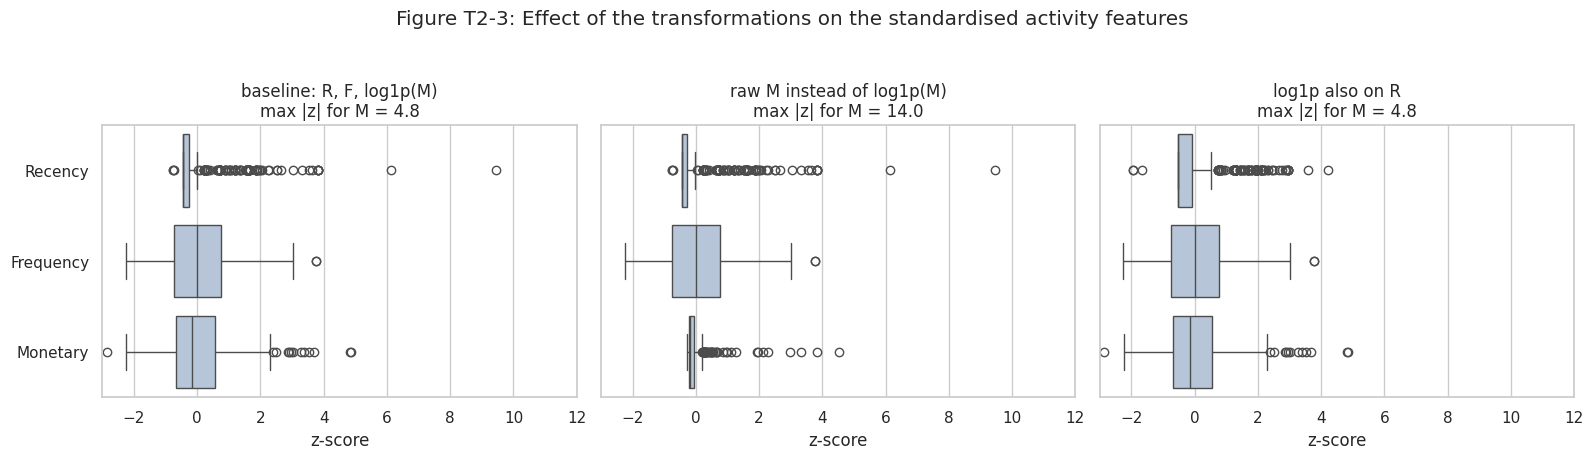

In [ ]:
from scipy.stats import spearmanr
base_name = "baseline: R, F, log1p(M)"
variants = {base_name: pd.DataFrame({"R": common["R"], "F": common["F"], "M": common["log1p_M"]}),
            "raw M instead of log1p(M)": pd.DataFrame({"R": common["R"], "F": common["F"], "M": common["M"]}),
            "log1p also on R": pd.DataFrame({"R": np.log1p(common["R"]), "F": common["F"], "M": common["log1p_M"]})}
var_Z, rows = {}, []
for name, V in variants.items():
    var_Z[name] = standardise(V)[0]
    for c_ in V.columns:
        zc = var_Z[name][c_]; sq = np.sort((zc ** 2).to_numpy())[::-1]
        rows.append({"version": name, "feature": c_, "skew": V[c_].skew(), "IQR_in_z_units": zc.quantile(0.75) - zc.quantile(0.25),
                     "max_abs_z": zc.abs().max(), "top5_share_of_squared_z_%": 100 * sq[:5].sum() / sq.sum()})
verify("the baseline version reproduces the standardised activity matrix", np.allclose(var_Z[base_name].to_numpy(), Z_act.to_numpy()))
verify("every standardised feature has the same total variance (equal total weight)", all(np.allclose(z_.var(ddof=0), 1) for z_ in var_Z.values()))
effect = pd.DataFrame(rows)
effect.to_csv(f"{DATA}/t2_transformation_effect.csv", index=False)
print("How each feature is spread after standardising (top-5 share = how much of the feature's squared z-scores come from only 5 shares):")
display(effect.round(2))

base_d = pdist(var_Z[base_name].to_numpy()); L_base = linkage(var_Z[base_name].to_numpy(), method="ward", metric="euclidean")
rows = []
for name, Zv in var_Z.items():
    Lv = linkage(Zv.to_numpy(), method="ward", metric="euclidean")
    rho = spearmanr(base_d, pdist(Zv.to_numpy()))[0]
    for k in (2, 3, 4):
        lab = fcluster(Lv, k, "maxclust")
        rows.append({"version": name, "k": k, "distance_rank_corr_vs_baseline": rho,
                     "ARI_vs_baseline": adjusted_rand_score(lab, fcluster(L_base, k, "maxclust")),
                     "smallest_cluster_%": 100 * np.bincount(lab)[1:].min() / len(lab)})
effect_cl = pd.DataFrame(rows)
effect_cl.to_csv(f"{DATA}/t2_transformation_effect_clusters.csv", index=False)
print("\nHow the distances and the Ward clusters change (silhouettes are not compared: each version is measured in its own space):")
display(effect_cl.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, (name, Zv) in zip(axes, var_Z.items()):
    sns.boxplot(data=Zv.rename(columns={"R": "Recency", "F": "Frequency", "M": "Monetary"}), orient="h", ax=ax, color="lightsteelblue")
    ax.set_title(f"{name}\nmax |z| for M = {Zv['M'].abs().max():.1f}"); ax.set_xlabel("z-score"); ax.set_xlim(-3, 12)
plt.suptitle("Figure T2-3: Effect of the transformations on the standardised activity features", y=1.04); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig3_transformation_effect.png", dpi=150, bbox_inches="tight"); plt.show()

##  Task 2.2 Agglomerative clustering

**Suitability.** Ward merges the pair of clusters that increases total within-cluster variance the least. It needs no starting centres, gives a full hierarchy (the dendrogram), and tends to produce compact, similar-sized clusters.
**Limitations.** It is deterministic but greedy: an early merge can never be undone. It assumes Euclidean geometry, so it is sensitive to scale and outliers. Its cost grows quickly with the number of shares, and it favours roughly spherical clusters.

For each k from 2 to 8 the table shows the silhouette score, the cluster sizes and the **merge height** (the distance at which k clusters merge into k-1; a big jump suggests the k clusters were genuinely separate).


Ward, RISK AND RETURN | cophenetic correlation = 0.479 (how faithfully the dendrogram preserves pairwise distances)


,silhouette,smallest,largest,smallest_%,merge_height_k_to_k-1,sizes
k,,,,,,
2,0.339,92,394,18.930,23.073,"[394, 92]"
3,0.274,92,230,18.930,18.803,"[230, 164, 92]"
4,0.282,48,182,9.877,14.210,"[182, 164, 92, 48]"
5,0.304,48,182,9.877,12.669,"[182, 98, 92, 66, 48]"
6,0.320,5,182,1.029,11.601,"[182, 98, 87, 66, 48, 5]"
7,0.324,5,160,1.029,8.342,"[160, 98, 87, 66, 48, 22, 5]"
8,0.321,5,160,1.029,8.308,"[160, 98, 66, 56, 48, 31, 22, 5]"



Ward, TRADING ACTIVITY (RFM) | cophenetic correlation = 0.508 (how faithfully the dendrogram preserves pairwise distances)


,silhouette,smallest,largest,smallest_%,merge_height_k_to_k-1,sizes
k,,,,,,
2,0.368,82,404,16.872,26.706,"[404, 82]"
3,0.304,82,250,16.872,22.985,"[250, 154, 82]"
4,0.289,43,207,8.848,15.843,"[207, 154, 82, 43]"
5,0.305,10,207,2.058,15.152,"[207, 154, 72, 43, 10]"
6,0.314,10,207,2.058,13.580,"[207, 136, 72, 43, 18, 10]"
7,0.292,10,141,2.058,11.293,"[141, 136, 72, 66, 43, 18, 10]"
8,0.302,10,141,2.058,10.537,"[141, 79, 72, 66, 57, 43, 18, 10]"


PASSED: every k from 2 to 8 produced exactly k Ward clusters

Ward candidate k (highest silhouette, best k >= 3 with no tiny cluster): {'rr_ward': (2, 5), 'act_ward': (2, 3)}
PASSED: silhouette matches an independent hand calculation (Ward, risk-return, k = 3)
PASSED: silhouette matches an independent hand calculation (Ward, activity, k = 3)


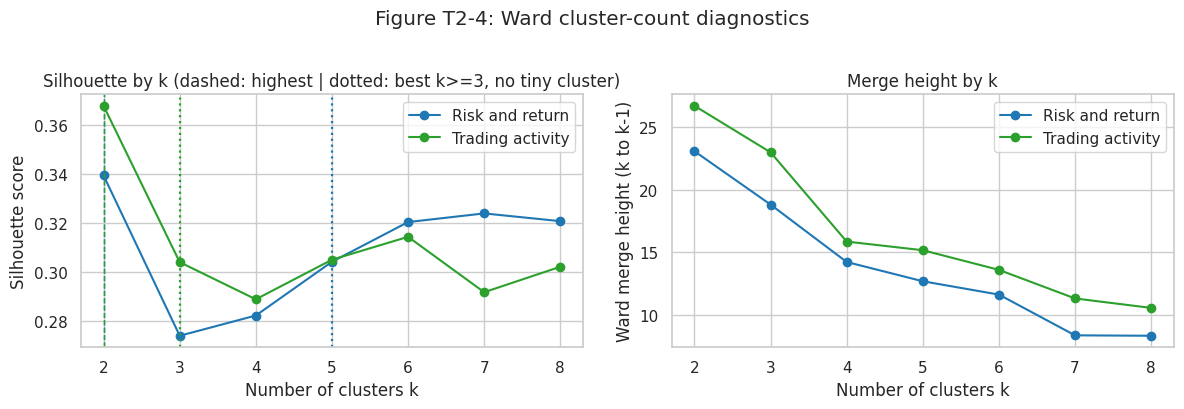

In [ ]:
def ward_table(Z):
    X = Z.to_numpy(); n = len(X)
    L = linkage(X, method="ward", metric="euclidean")
    coph = cophenet(L, pdist(X))[0]
    rows = []
    for k in K_RANGE:
        lab = fcluster(L, k, criterion="maxclust")
        sizes = np.bincount(lab)[1:]
        rows.append({"k": k, "silhouette": silhouette_score(X, lab), "smallest": int(sizes.min()),
                     "largest": int(sizes.max()), "smallest_%": 100 * sizes.min() / n,
                     "merge_height_k_to_k-1": L[n - k, 2], "sizes": sorted(sizes.tolist(), reverse=True)})
    return L, pd.DataFrame(rows).set_index("k"), coph

from scipy.spatial.distance import squareform

def candidate_ks(tab):
    """Two candidate cluster counts: the highest silhouette, and the best k from 3 upward with no tiny cluster."""
    k_top = int(tab["silhouette"].idxmax())
    ok = tab[(tab.index >= 3) & (tab["smallest_%"] >= 100 * MIN_CLUSTER_FRAC)]
    return k_top, (int(ok["silhouette"].idxmax()) if len(ok) else k_top)

def silhouette_by_hand(X, labels):
    """Mean of (b - a) / max(a, b): a = mean distance to the share's own cluster, b = smallest mean distance to another cluster."""
    D = squareform(pdist(X)); lab = np.asarray(labels); ids = np.unique(lab); own = np.searchsorted(ids, lab)
    S = np.stack([D[:, lab == c_].sum(axis=1) for c_ in ids], axis=1)            # total distance from each share to each cluster
    n_c = np.array([(lab == c_).sum() for c_ in ids]); rows_ = np.arange(len(lab))
    a = S[rows_, own] / np.maximum(n_c[own] - 1, 1)
    other = S / n_c; other[rows_, own] = np.inf
    b = other.min(axis=1)
    s = np.where(n_c[own] == 1, 0.0, (b - a) / np.maximum(a, b))
    return s.mean()

L_rr, ward_rr, coph_rr = ward_table(Z_rr)
L_act, ward_act, coph_act = ward_table(Z_act)
for name, tab, coph in [("RISK AND RETURN", ward_rr, coph_rr), ("TRADING ACTIVITY (RFM)", ward_act, coph_act)]:
    print(f"\nWard, {name} | cophenetic correlation = {coph:.3f} (how faithfully the dendrogram preserves pairwise distances)")
    display(tab.round(3))
ward_rr.to_csv(f"{DATA}/t2_ward_selection_risk_return.csv"); ward_act.to_csv(f"{DATA}/t2_ward_selection_activity.csv")
verify("every k from 2 to 8 produced exactly k Ward clusters",
       all(len(np.unique(fcluster(L, k, "maxclust"))) == k for L in (L_rr, L_act) for k in K_RANGE), hard=False)

cand_ward = {"rr_ward": candidate_ks(ward_rr), "act_ward": candidate_ks(ward_act)}
print("\nWard candidate k (highest silhouette, best k >= 3 with no tiny cluster):", cand_ward)
for nm_, Zm_, L_ in [("risk-return", Z_rr, L_rr), ("activity", Z_act, L_act)]:
    lab3 = fcluster(L_, 3, "maxclust")
    verify(f"silhouette matches an independent hand calculation (Ward, {nm_}, k = 3)",
           np.isclose(silhouette_by_hand(Zm_.to_numpy(), lab3), silhouette_score(Zm_.to_numpy(), lab3)))

# Figure T2-4: Ward diagnostics
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for tab, lab_, key_, col_ in [(ward_rr, "Risk and return", "rr_ward", "tab:blue"), (ward_act, "Trading activity", "act_ward", "tab:green")]:
    axes[0].plot(tab.index, tab["silhouette"], marker="o", label=lab_, color=col_)
    axes[1].plot(tab.index, tab["merge_height_k_to_k-1"], marker="o", label=lab_, color=col_)
    axes[0].axvline(cand_ward[key_][0], color=col_, ls="--", lw=1); axes[0].axvline(cand_ward[key_][1], color=col_, ls=":", lw=1.6)
axes[0].set(xlabel="Number of clusters k", ylabel="Silhouette score", title="Silhouette by k (dashed: highest | dotted: best k>=3, no tiny cluster)"); axes[0].legend()
axes[1].set(xlabel="Number of clusters k", ylabel="Ward merge height (k to k-1)", title="Merge height by k"); axes[1].legend()
plt.suptitle("Figure T2-4: Ward cluster-count diagnostics", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig4_ward_diagnostics.png", dpi=150, bbox_inches="tight"); plt.show()

##  Task 2.3 K-means clustering

**Suitability.** K-means is fast and easy to explain: each share joins the nearest of k centres, and the centres are updated until nothing changes. It scales well and suits compact groups.
**Limitations.** It assumes roughly spherical clusters of similar size and variance, is sensitive to scale and outliers, needs k in advance, and can stop at a poor local optimum depending on its random start.

**Reproducibility.** A fixed seed  is set and  random starts are used. The table also shows how much a **single** random start would have varied, which is the evidence that multiple initialisations matter.

PASSED: K-means inertia equals the sum of squared distances to the cluster means, for every k
K-means candidate k (highest silhouette, best k >= 3 with no tiny cluster): {'rr_kmeans': (2, 5), 'act_kmeans': (2, 4)}

K-means, RISK AND RETURN (seed 42, n_init 50)


,silhouette,inertia,single_start_inertia_min,single_start_inertia_max,%_single_starts_worse,ARI_vs_other_seed,smallest,largest,smallest_%,sizes
k,,,,,,,,,,
2,0.387,621.634,621.634,621.654,0.0,1.000,143,343,29.424,"[343, 143]"
3,0.329,461.179,461.179,461.397,10.0,1.000,119,202,24.486,"[202, 165, 119]"
4,0.327,371.577,371.577,421.028,70.0,1.000,40,160,8.230,"[160, 154, 132, 40]"
5,0.341,309.613,309.800,344.164,100.0,0.930,27,166,5.556,"[166, 131, 112, 50, 27]"
6,0.335,265.097,265.933,286.725,100.0,1.000,5,156,1.029,"[156, 127, 105, 50, 43, 5]"
7,0.328,227.183,227.533,251.914,100.0,0.490,5,128,1.029,"[128, 103, 85, 77, 47, 41, 5]"
8,0.354,194.362,194.861,228.996,100.0,0.962,5,136,1.029,"[136, 79, 78, 76, 43, 40, 29, 5]"



K-means, TRADING ACTIVITY (RFM) (seed 42, n_init 50)


,silhouette,inertia,single_start_inertia_min,single_start_inertia_max,%_single_starts_worse,ARI_vs_other_seed,smallest,largest,smallest_%,sizes
k,,,,,,,,,,
2,0.423,1066.832,1066.832,1169.902,50.0,1.000,68,418,13.992,"[418, 68]"
3,0.325,796.614,796.614,985.433,80.0,1.000,64,270,13.169,"[270, 152, 64]"
4,0.341,609.832,609.832,728.520,45.0,1.000,61,212,12.551,"[212, 122, 91, 61]"
5,0.358,514.714,514.714,653.996,80.0,1.000,11,198,2.263,"[198, 122, 87, 68, 11]"
6,0.347,437.393,437.422,499.713,85.0,0.991,11,143,2.263,"[143, 120, 105, 67, 40, 11]"
7,0.347,386.286,386.277,458.318,90.0,0.986,1,141,0.206,"[141, 120, 104, 68, 41, 11, 1]"
8,0.350,342.175,342.185,382.680,95.0,0.461,1,140,0.206,"[140, 106, 83, 66, 64, 15, 11, 1]"


PASSED: inertia never increases as k grows


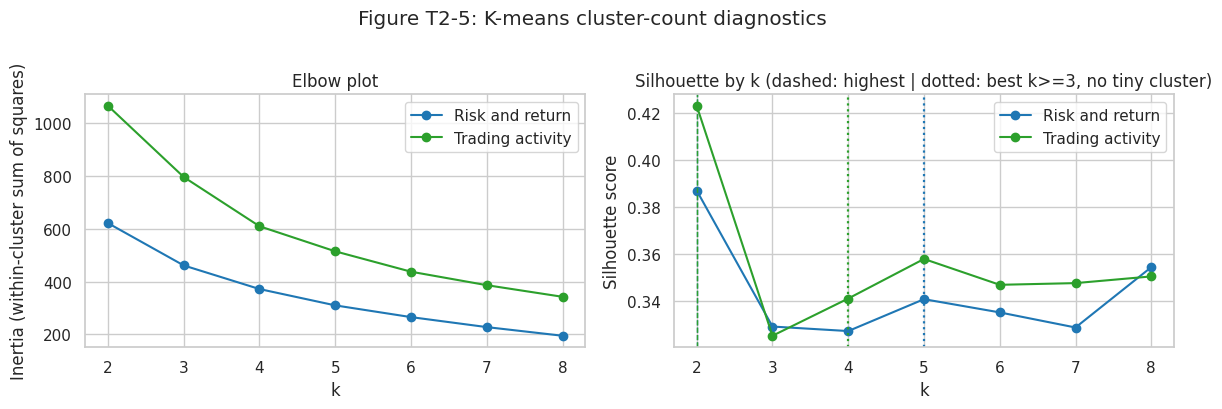

In [ ]:
inertia_checks = []

def kmeans_table(Z):
    X = Z.to_numpy(); n = len(X); rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X)
        sizes = np.bincount(km.labels_)
        centres = np.vstack([X[km.labels_ == c_].mean(axis=0) for c_ in range(k)])
        inertia_checks.append(np.isclose(km.inertia_, ((X - centres[km.labels_]) ** 2).sum(), rtol=1e-3))
        singles = np.array([KMeans(n_clusters=k, n_init=1, random_state=s).fit(X).inertia_ for s in range(20)])
        other = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED + 1).fit(X).labels_
        rows.append({"k": k, "silhouette": silhouette_score(X, km.labels_), "inertia": km.inertia_,
                     "single_start_inertia_min": singles.min(), "single_start_inertia_max": singles.max(),
                     "%_single_starts_worse": 100 * float((singles > km.inertia_ * 1.0001).mean()),
                     "ARI_vs_other_seed": adjusted_rand_score(km.labels_, other),
                     "smallest": int(sizes.min()), "largest": int(sizes.max()), "smallest_%": 100 * sizes.min() / n,
                     "sizes": sorted(sizes.tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index("k")

km_rr, km_act = kmeans_table(Z_rr), kmeans_table(Z_act)
verify("K-means inertia equals the sum of squared distances to the cluster means, for every k", all(inertia_checks), hard=False)
cand_km = {"rr_kmeans": candidate_ks(km_rr), "act_kmeans": candidate_ks(km_act)}
print("K-means candidate k (highest silhouette, best k >= 3 with no tiny cluster):", cand_km)
for name, tab in [("RISK AND RETURN", km_rr), ("TRADING ACTIVITY (RFM)", km_act)]:
    print(f"\nK-means, {name} (seed {SEED}, n_init {N_INIT})")
    display(tab.round(3))
km_rr.to_csv(f"{DATA}/t2_kmeans_selection_risk_return.csv"); km_act.to_csv(f"{DATA}/t2_kmeans_selection_activity.csv")
verify("inertia never increases as k grows", all((t["inertia"].diff().dropna() < 0).all() for t in (km_rr, km_act)))

# Figure T2-5: elbow and silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for tab, lab_, key_, col_ in [(km_rr, "Risk and return", "rr_kmeans", "tab:blue"), (km_act, "Trading activity", "act_kmeans", "tab:green")]:
    axes[0].plot(tab.index, tab["inertia"], marker="o", label=lab_, color=col_)
    axes[1].plot(tab.index, tab["silhouette"], marker="o", label=lab_, color=col_)
    axes[1].axvline(cand_km[key_][0], color=col_, ls="--", lw=1); axes[1].axvline(cand_km[key_][1], color=col_, ls=":", lw=1.6)
axes[0].set(xlabel="k", ylabel="Inertia (within-cluster sum of squares)", title="Elbow plot"); axes[0].legend()
axes[1].set(xlabel="k", ylabel="Silhouette score", title="Silhouette by k (dashed: highest | dotted: best k>=3, no tiny cluster)"); axes[1].legend()
plt.suptitle("Figure T2-5: K-means cluster-count diagnostics", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig5_kmeans_diagnostics.png", dpi=150, bbox_inches="tight"); plt.show()

##  Choose the cluster counts and fit the four baseline solutions

Silhouette alone often favours k = 2. The brief asks you to weigh **silhouette, cluster sizes, interpretable profiles** (and inertia, merge heights).

* The automatic suggestion below picks the k with the highest silhouette **among k where the smallest cluster is at least 5% of the shares**.
* Two **candidate** counts are also profiled in section 12 for each solution: the **highest-silhouette k**, and the **best k from 3 upward with no tiny cluster**. Compare them with your chosen k before you decide.
* **That is only a starting point.** Read the tables, figures and the profiles in section 6, then **type your own k** into `SELECTED_K` and rerun from here. Explain your choice in the report.

In [ ]:
SELECTED_K = {"rr_ward": None, "rr_kmeans": None, "act_ward": None, "act_kmeans": None}   # None = automatic suggestion; or type 3, 4, ...

def suggest_k(tab):
    ok = tab[tab["smallest_%"] >= 100 * MIN_CLUSTER_FRAC]
    pool = ok if len(ok) else tab
    return int(pool["silhouette"].idxmax())

tables = {"rr_ward": ward_rr, "rr_kmeans": km_rr, "act_ward": ward_act, "act_kmeans": km_act}
final_k = {key: (SELECTED_K[key] if SELECTED_K[key] is not None else suggest_k(tab)) for key, tab in tables.items()}
for key, tab in tables.items():
    src = "your choice" if SELECTED_K[key] is not None else "automatic suggestion"
    print(f"{key:11s} k = {final_k[key]} ({src}) | silhouette {tab.loc[final_k[key], 'silhouette']:.3f} | sizes {tab.loc[final_k[key], 'sizes']}")

def relabel_by_size(lab):
    """Cluster numbers are arbitrary; number them 1, 2, ... from the largest cluster down so tables are easy to read."""
    lab = np.asarray(lab); order = pd.Series(lab).value_counts().index
    mapping = {old: new for new, old in enumerate(order, start=1)}
    return np.array([mapping[x] for x in lab])

def fit_ward(Z, k):
    return relabel_by_size(AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z.to_numpy()))
def fit_kmeans(Z, k):
    return relabel_by_size(KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(Z.to_numpy()).labels_)

assign = pd.DataFrame(index=common.index)
assign["RR_Ward"]    = fit_ward(Z_rr, final_k["rr_ward"])
assign["RR_KMeans"]  = fit_kmeans(Z_rr, final_k["rr_kmeans"])
assign["RFM_Ward"]   = fit_ward(Z_act, final_k["act_ward"])
assign["RFM_KMeans"] = fit_kmeans(Z_act, final_k["act_kmeans"])

verify("sklearn Ward gives the same partition as the scipy linkage used for the dendrogram (risk and return)",
       adjusted_rand_score(assign["RR_Ward"], fcluster(L_rr, final_k["rr_ward"], "maxclust")) == 1.0)
verify("sklearn Ward gives the same partition as the scipy linkage used for the dendrogram (activity)",
       adjusted_rand_score(assign["RFM_Ward"], fcluster(L_act, final_k["act_ward"], "maxclust")) == 1.0)
SOLUTIONS = {"RR_Ward": ("Risk and return, Ward", Z_rr, RR), "RR_KMeans": ("Risk and return, K-means", Z_rr, RR),
             "RFM_Ward": ("Trading activity (RFM), Ward", Z_act, ACT), "RFM_KMeans": ("Trading activity (RFM), K-means", Z_act, ACT)}
for col, (name, Z, _) in SOLUTIONS.items():
    sizes = assign[col].value_counts().sort_index()
    print(f"{col:11s} k = {sizes.size} | sizes {sizes.tolist()} | silhouette {silhouette_score(Z.to_numpy(), assign[col]):.3f}")
for col, (name, Z, _) in SOLUTIONS.items():
    verify(f"{col}: silhouette matches an independent hand calculation",
           np.isclose(silhouette_by_hand(Z.to_numpy(), assign[col]), silhouette_score(Z.to_numpy(), assign[col])))

rr_ward     k = 2 (automatic suggestion) | silhouette 0.339 | sizes [394, 92]
rr_kmeans   k = 2 (automatic suggestion) | silhouette 0.387 | sizes [343, 143]
act_ward    k = 2 (automatic suggestion) | silhouette 0.368 | sizes [404, 82]
act_kmeans  k = 2 (automatic suggestion) | silhouette 0.423 | sizes [418, 68]
PASSED: sklearn Ward gives the same partition as the scipy linkage used for the dendrogram (risk and return)
PASSED: sklearn Ward gives the same partition as the scipy linkage used for the dendrogram (activity)
RR_Ward     k = 2 | sizes [394, 92] | silhouette 0.339
RR_KMeans   k = 2 | sizes [343, 143] | silhouette 0.387
RFM_Ward    k = 2 | sizes [404, 82] | silhouette 0.368
RFM_KMeans  k = 2 | sizes [418, 68] | silhouette 0.423
PASSED: RR_Ward: silhouette matches an independent hand calculation
PASSED: RR_KMeans: silhouette matches an independent hand calculation
PASSED: RFM_Ward: silhouette matches an independent hand calculation
PASSED: RFM_KMeans: silhouette matches an indepe

##  Dendrograms (one per feature matrix)

The dashed line marks where the tree is cut for the **chosen** k. The colour threshold only draws that cut; the choice of k comes from the diagnostics above.

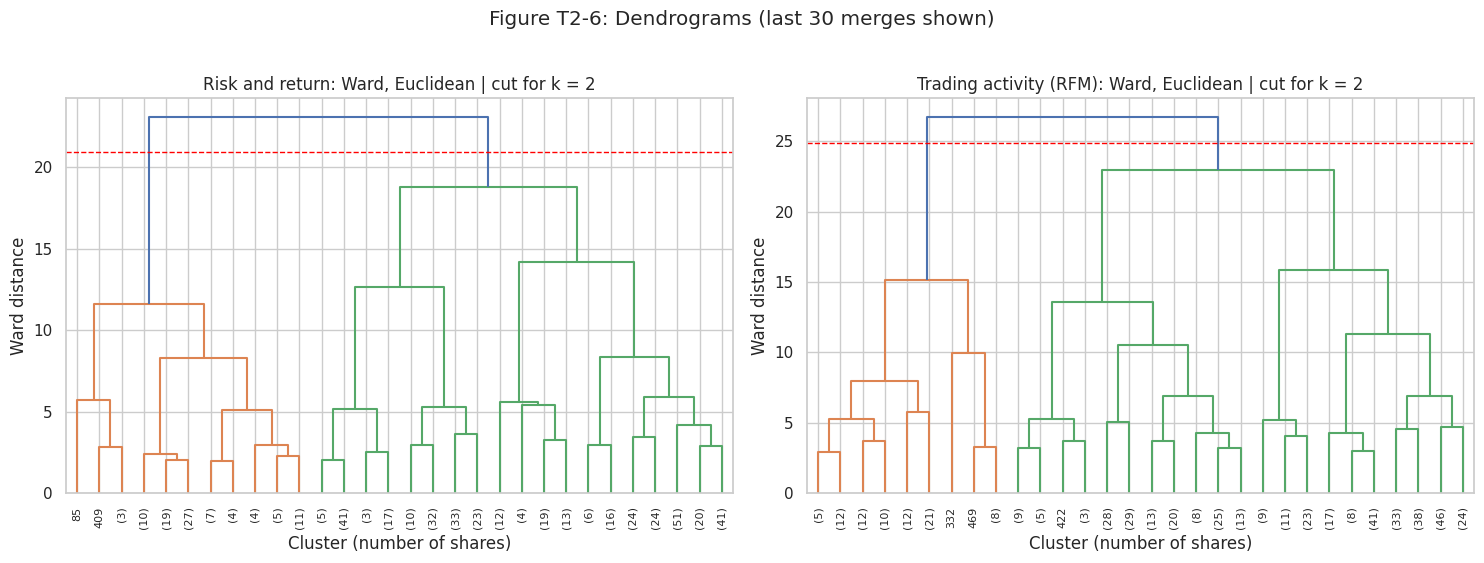

In [ ]:
def cut_height(L, k):
    n = L.shape[0] + 1
    upper = L[n - k, 2]                                     # height at which k clusters merge into k-1
    lower = L[n - k - 1, 2] if n - k - 1 >= 0 else 0.0
    return (lower + upper) / 2

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, L, k, title in [(axes[0], L_rr, final_k["rr_ward"], "Risk and return"), (axes[1], L_act, final_k["act_ward"], "Trading activity (RFM)")]:
    h = cut_height(L, k)
    dendrogram(L, truncate_mode="lastp", p=30, show_leaf_counts=True, color_threshold=h, ax=ax, leaf_rotation=90, leaf_font_size=8)
    ax.axhline(h, color="red", ls="--", lw=1)
    ax.set_title(f"{title}: Ward, Euclidean | cut for k = {k}"); ax.set_xlabel("Cluster (number of shares)"); ax.set_ylabel("Ward distance")
plt.suptitle("Figure T2-6: Dendrograms (last 30 merges shown)", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig6_dendrograms.png", dpi=150, bbox_inches="tight"); plt.show()

##  Task 2.4 Cluster profiles and algorithm comparison



In [ ]:
disp = pd.DataFrame({"Return_%_per_week": 100 * common["Mean_Weekly_Return"], "Beta": common["Weekly_Beta"],
                     "R_days": common["R"], "F_days": common["F"], "M_USD_bn": common["M"] / 1e9})

def profile_tables(labels):
    g = disp.groupby(np.asarray(labels))
    n = pd.Series(np.asarray(labels)).value_counts().sort_index()
    med = g.median().round(3); mean = g.mean().round(3)
    med.insert(0, "Share_%", (100 * n / n.sum()).round(1)); med.insert(0, "n", n)
    return med, mean

profiles = {}
for col, (name, Z, feats) in SOLUTIONS.items():
    med, mean = profile_tables(assign[col])
    profiles[col] = (med, mean)
    print(f"\n=== {name}: medians (original units) ===")
    display(med)
    print("means:")
    display(mean)
    med.to_csv(f"{DATA}/t2_profile_median_{col}.csv"); mean.to_csv(f"{DATA}/t2_profile_mean_{col}.csv")


=== Risk and return, Ward: medians (original units) ===


,n,Share_%,Return_%_per_week,Beta,R_days,F_days,M_USD_bn
1,394,81.1,0.209,0.882,11.0,3.0,15.325
2,92,18.9,0.550,1.218,11.0,3.0,24.184


means:


,Return_%_per_week,Beta,R_days,F_days,M_USD_bn
1,0.205,0.898,19.645,2.942,30.210
2,0.632,1.298,23.674,3.196,78.781



=== Risk and return, K-means: medians (original units) ===


,n,Share_%,Return_%_per_week,Beta,R_days,F_days,M_USD_bn
1,343,70.6,0.192,0.834,11.0,3.0,14.206
2,143,29.4,0.486,1.278,11.0,3.0,25.524


... (6 outputs left out)


=== Trading activity (RFM), K-means: medians (original units) ===


,n,Share_%,Return_%_per_week,Beta,R_days,F_days,M_USD_bn
1,418,86.0,0.267,0.939,11.0,3.0,15.57
2,68,14.0,0.254,1.009,55.0,2.0,22.25


means:


,Return_%_per_week,Beta,R_days,F_days,M_USD_bn
1,0.283,0.972,13.423,3.187,32.691
2,0.302,0.982,63.338,1.779,80.671


In [ ]:
# The two candidate cluster counts and the chosen k, side by side, plus representative shares
cand_k = {**cand_ward, **cand_km}
key_to_col = {"rr_ward": "RR_Ward", "rr_kmeans": "RR_KMeans", "act_ward": "RFM_Ward", "act_kmeans": "RFM_KMeans"}
tab_of = {"rr_ward": ward_rr, "rr_kmeans": km_rr, "act_ward": ward_act, "act_kmeans": km_act}
rows = []
for key, col in key_to_col.items():
    for role, k in [("highest silhouette", cand_k[key][0]), ("best k >= 3, no tiny cluster", cand_k[key][1]), ("chosen (final_k)", final_k[key])]:
        r_ = tab_of[key].loc[k]
        rows.append({"Solution": SOLUTIONS[col][0], "Role": role, "k": k, "Silhouette": r_["silhouette"],
                     "Smallest_cluster_%": r_["smallest_%"], "Sizes": r_["sizes"]})
cand_table = pd.DataFrame(rows)
cand_table.to_csv(f"{DATA}/t2_candidate_k_comparison.csv", index=False)
display(cand_table.round(3))

for key, col in key_to_col.items():                         # original-unit profiles for any candidate k that is not the chosen one
    name, Z, _ = SOLUTIONS[col]
    for k in sorted({*cand_k[key], final_k[key]} - {final_k[key]}):
        lab = (fit_ward if key.endswith("ward") else fit_kmeans)(Z, k)
        med, _mean = profile_tables(lab)
        print(f"\n=== {name}, candidate k = {k} (medians in original units) ===")
        display(med)
        med.to_csv(f"{DATA}/t2_profile_median_{col}_k{k}.csv")

def representatives(labels, Z, n_show=4):
    g = pd.Series(np.asarray(labels), index=Z.index)
    dist = np.sqrt(((Z - Z.groupby(g).transform("mean")) ** 2).sum(axis=1))
    out = pd.DataFrame({"n": g.value_counts().sort_index()})
    out["Closest_to_centre"] = [", ".join(dist[g == c_].nsmallest(n_show).index) for c_ in out.index]
    tops = [common.loc[g[g == c_].index, "Sector"].value_counts() for c_ in out.index]
    out["Top_sector"] = [f"{t_.index[0]} ({t_.iloc[0]})" for t_ in tops]
    return out
for col, (name, Z, _) in SOLUTIONS.items():
    rep = representatives(assign[col], Z)
    rep.to_csv(f"{DATA}/t2_representatives_{col}.csv")
    print(f"\n{name}: shares closest to each cluster centre, and the most common sector")
    display(rep)

,Solution,Role,k,Silhouette,Smallest_cluster_%,Sizes
0,"Risk and return, Ward",highest silhouette,2,0.339,18.930,"[394, 92]"
1,"Risk and return, Ward","best k >= 3, no tiny cluster",5,0.304,9.877,"[182, 98, 92, 66, 48]"
2,"Risk and return, Ward",chosen (final_k),2,0.339,18.930,"[394, 92]"
3,"Risk and return, K-means",highest silhouette,2,0.387,29.424,"[343, 143]"
4,"Risk and return, K-means","best k >= 3, no tiny cluster",5,0.341,5.556,"[166, 131, 112, 50, 27]"
5,"Risk and return, K-means",chosen (final_k),2,0.387,29.424,"[343, 143]"
6,"Trading activity (RFM), Ward",highest silhouette,2,0.368,16.872,"[404, 82]"
7,"Trading activity (RFM), Ward","best k >= 3, no tiny cluster",3,0.304,16.872,"[250, 154, 82]"
8,"Trading activity (RFM), Ward",chosen (final_k),2,0.368,16.872,"[404, 82]"
9,"Trading activity (RFM), K-means",highest silhouette,2,0.423,13.992,"[418, 68]"



=== Risk and return, Ward, candidate k = 5 (medians in original units) ===


,n,Share_%,Return_%_per_week,Beta,R_days,F_days,M_USD_bn
1,182,37.4,0.166,0.964,11.0,3.0,12.985
2,98,20.2,0.392,0.666,11.0,3.0,17.649
3,92,18.9,0.550,1.218,11.0,3.0,24.184
4,66,13.6,0.113,0.449,11.0,3.0,17.701
5,48,9.9,0.252,1.514,11.0,3.0,28.698



=== Risk and return, K-means, candidate k = 5 (medians in original units) ===


,n,Share_%,Return_%_per_week,Beta,R_days,F_days,M_USD_bn
1,166,34.2,0.415,0.996,11.0,3.0,17.720
2,131,27.0,0.203,0.530,11.0,3.0,15.044
3,112,23.0,0.075,1.032,11.0,3.0,13.503
4,50,10.3,0.267,1.543,11.0,3.0,32.148
5,27,5.6,0.831,1.450,11.0,3.0,28.211



=== Trading activity (RFM), Ward, candidate k = 3 (medians in original units) ===


... (7 outputs left out)


Trading activity (RFM), Ward: shares closest to each cluster centre, and the most common sector


,n,Closest_to_centre,Top_sector
1,404,"CARR, NUE, STZ, AIG",Industrials (72)
2,82,"TFC, CSX, JCI, MSCI",Information Technology (18)



Trading activity (RFM), K-means: shares closest to each cluster centre, and the most common sector


,n,Closest_to_centre,Top_sector
1,418,"NUE, AIG, DXCM, ODFL",Industrials (73)
2,68,"CDNS, F, CSX, TFC",Information Technology (14)


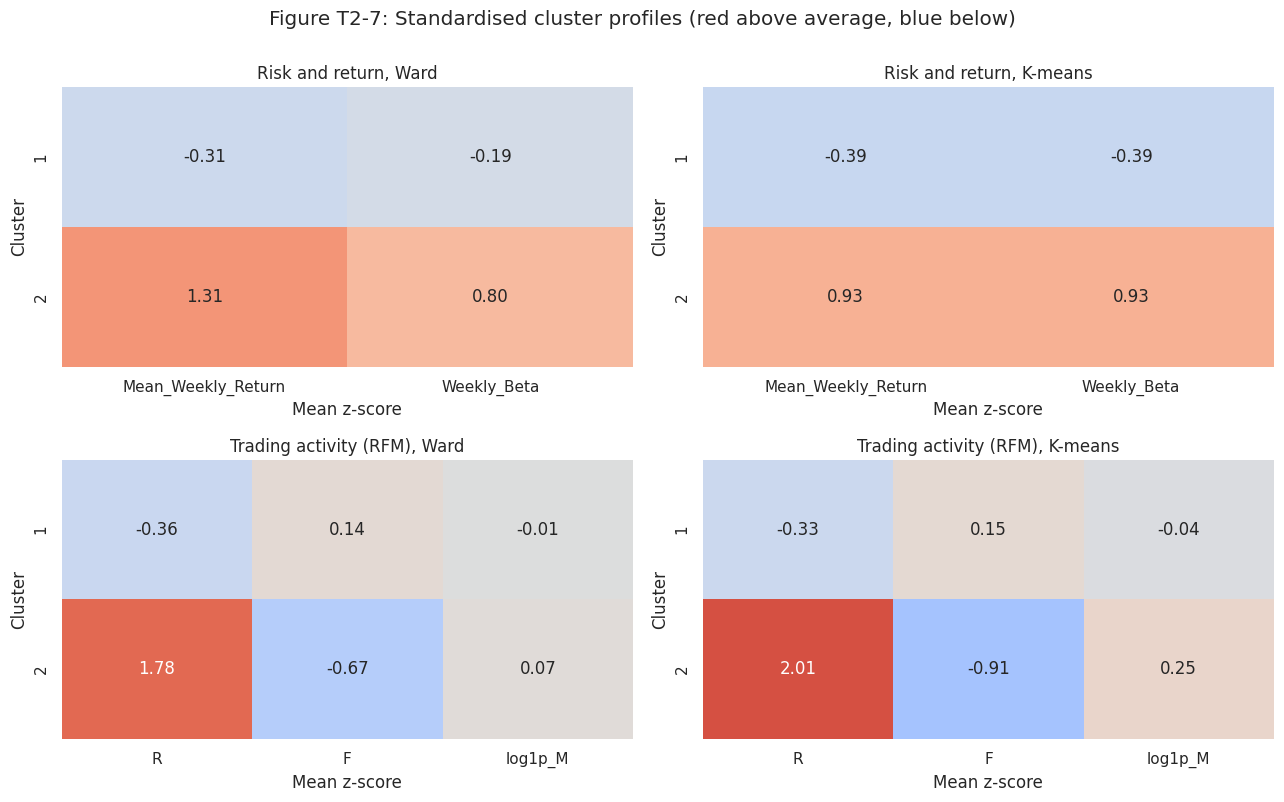

In [ ]:
# Figure T2-7: standardised profiles, to see what separates each cluster
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, (name, Z, feats)) in zip(axes.ravel(), SOLUTIONS.items()):
    zp = Z.groupby(assign[col].to_numpy()).mean()
    sns.heatmap(zp, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-2.5, vmax=2.5, ax=ax, cbar=False)
    ax.set_title(name); ax.set_ylabel("Cluster"); ax.set_xlabel("Mean z-score")
plt.suptitle("Figure T2-7: Standardised cluster profiles (red above average, blue below)", y=1.0); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig7_zprofiles.png", dpi=150, bbox_inches="tight"); plt.show()

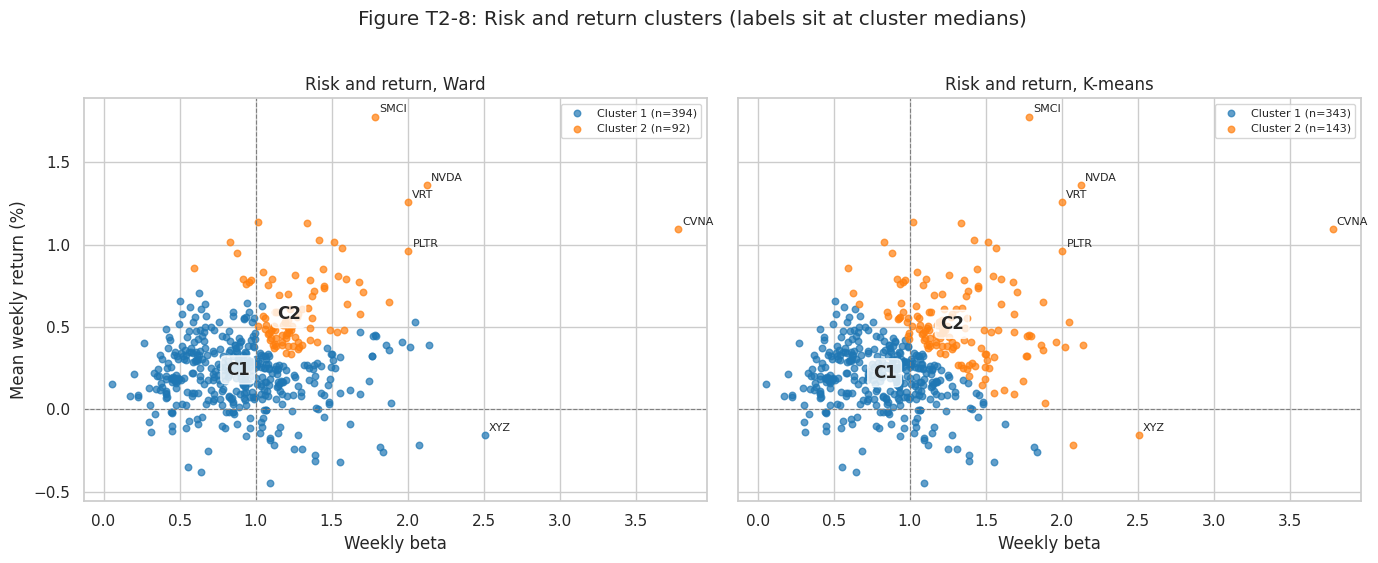

PCA is a rotation of the 3 standardised RFM features onto the 2 directions of greatest spread.
Variance explained: PC1 45.8%, PC2 33.6%, together 79.4%
Loadings (how each feature contributes to each axis):


,PC1,PC2
R,0.711,0.023
F,-0.650,0.402
log1p_M,0.268,0.915


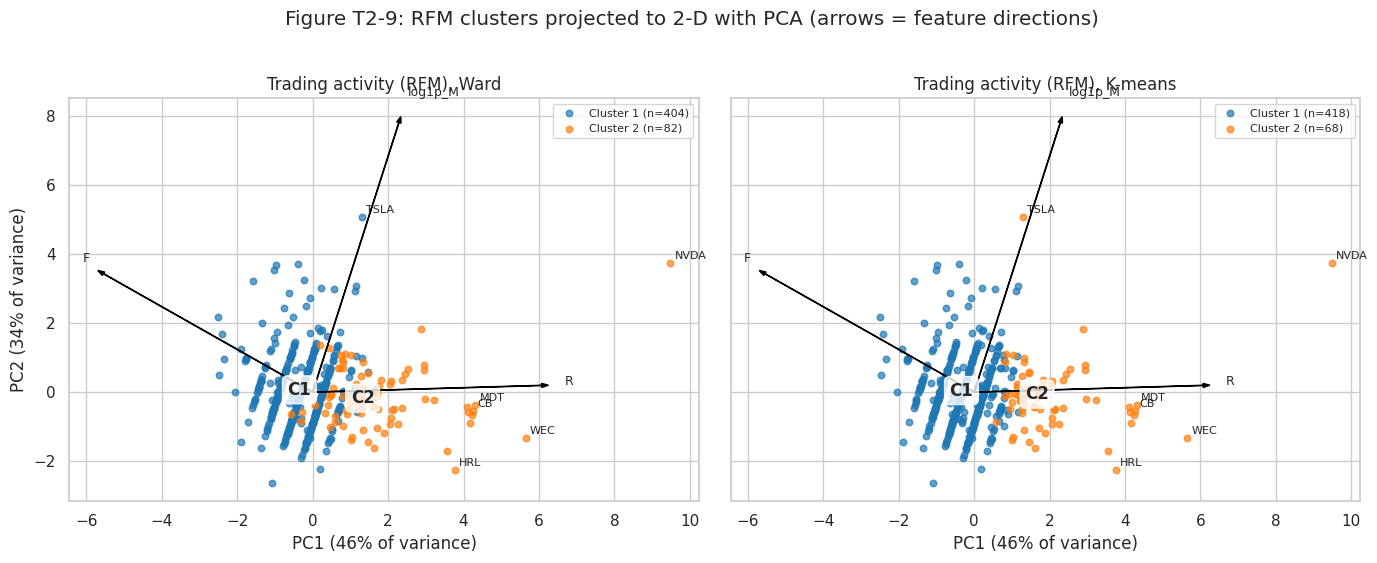

In [ ]:
# Figure T2-8: risk and return is two-dimensional, so it is plotted directly in original units (no reduction needed)
palette = sns.color_palette("tab10", 10)
far_rr = (Z_rr ** 2).sum(axis=1).nlargest(6).index        # the 6 shares farthest from the average, named on the plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, col in zip(axes, ["RR_Ward", "RR_KMeans"]):
    for c_, grp in disp.groupby(assign[col].to_numpy()):
        ax.scatter(grp["Beta"], grp["Return_%_per_week"], s=22, alpha=0.7, color=palette[(c_ - 1) % 10], label=f"Cluster {c_} (n={len(grp)})")
        ax.annotate(f"C{c_}", (grp["Beta"].median(), grp["Return_%_per_week"].median()), fontsize=12, fontweight="bold",
                    ha="center", bbox=dict(boxstyle="round", fc="white", alpha=0.8))
    for t_ in far_rr:
        ax.annotate(t_, (disp.at[t_, "Beta"], disp.at[t_, "Return_%_per_week"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.axvline(1, color="grey", ls="--", lw=0.8); ax.axhline(0, color="grey", ls="--", lw=0.8)
    ax.set_xlabel("Weekly beta"); ax.set_title(SOLUTIONS[col][0]); ax.legend(fontsize=8)
axes[0].set_ylabel("Mean weekly return (%)")
plt.suptitle("Figure T2-8: Risk and return clusters (labels sit at cluster medians)", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig8_riskreturn_scatter.png", dpi=150, bbox_inches="tight"); plt.show()

# Figure T2-9: RFM has three dimensions. PCA is used ONLY to draw the picture; clustering used all three standardised features.
pca = PCA(n_components=2, random_state=SEED).fit(Z_act.to_numpy())
P = pca.transform(Z_act.to_numpy())
far_act = pd.Series((P ** 2).sum(axis=1), index=Z_act.index).nlargest(6).index
pc_load = pd.DataFrame(pca.components_.T, index=ACT, columns=["PC1", "PC2"])
print("PCA is a rotation of the 3 standardised RFM features onto the 2 directions of greatest spread.")
print("Variance explained: PC1 %.1f%%, PC2 %.1f%%, together %.1f%%" % (100 * pca.explained_variance_ratio_[0], 100 * pca.explained_variance_ratio_[1], 100 * pca.explained_variance_ratio_.sum()))
print("Loadings (how each feature contributes to each axis):"); display(pc_load.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, col in zip(axes, ["RFM_Ward", "RFM_KMeans"]):
    lab = assign[col].to_numpy()
    for c_ in np.unique(lab):
        m_ = lab == c_
        ax.scatter(P[m_, 0], P[m_, 1], s=22, alpha=0.7, color=palette[(c_ - 1) % 10], label=f"Cluster {c_} (n={m_.sum()})")
        ax.annotate(f"C{c_}", (np.median(P[m_, 0]), np.median(P[m_, 1])), fontsize=12, fontweight="bold", ha="center", bbox=dict(boxstyle="round", fc="white", alpha=0.8))
    for t_ in far_act:
        i_ = Z_act.index.get_loc(t_)
        ax.annotate(t_, (P[i_, 0], P[i_, 1]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    scale = 0.9 * np.abs(P).max()
    for f_ in ACT:
        ax.arrow(0, 0, pc_load.loc[f_, "PC1"] * scale, pc_load.loc[f_, "PC2"] * scale, color="black", width=0.01, head_width=0.12)
        ax.text(pc_load.loc[f_, "PC1"] * scale * 1.1, pc_load.loc[f_, "PC2"] * scale * 1.1, f_, fontsize=9)
    ax.set_xlabel(f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f}% of variance)"); ax.set_title(SOLUTIONS[col][0]); ax.legend(fontsize=8)
axes[0].set_ylabel(f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f}% of variance)")
plt.suptitle("Figure T2-9: RFM clusters projected to 2-D with PCA (arrows = feature directions)", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig9_rfm_pca.png", dpi=150, bbox_inches="tight"); plt.show()

,k_Ward,k_KMeans,ARI (own k),NMI (own k),Matched agreement,ARI (same k as Ward),Silhouette Ward,Silhouette K-means
Matrix,,,,,,,,
Risk and return,2,2,0.598,0.538,0.895,0.598,0.339,0.387
Trading activity (RFM),2,2,0.700,0.526,0.938,0.700,0.368,0.423


PASSED: ARI is unchanged when cluster numbers are shuffled (labels are arbitrary)


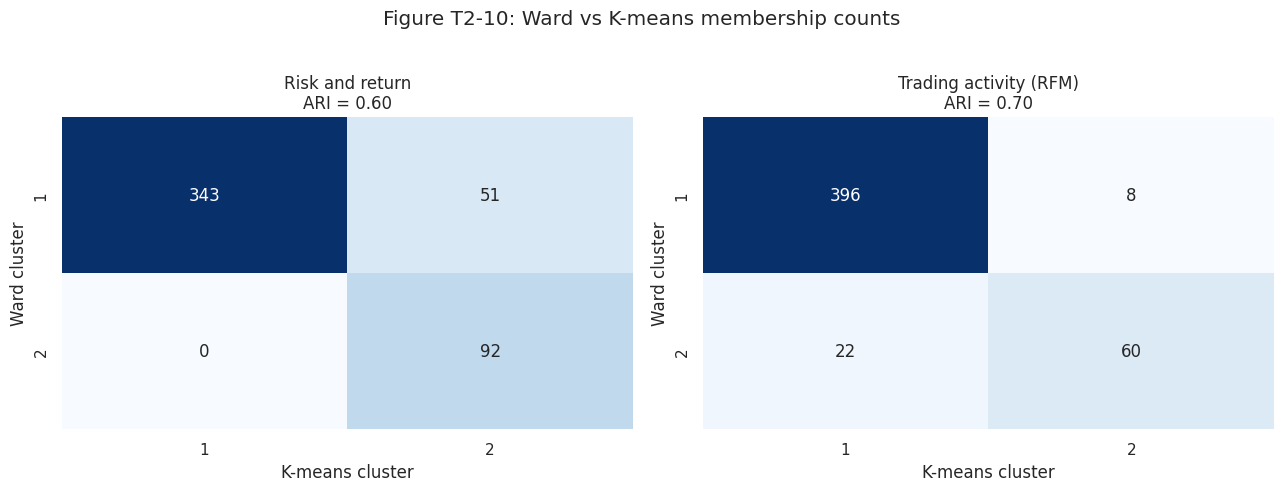

In [ ]:
# Algorithm comparison on the SAME shares
def compare(a, b):
    ct = pd.crosstab(a, b)
    r_, c_ = linear_sum_assignment(-ct.to_numpy())                    # best one-to-one matching of cluster numbers
    matched = ct.to_numpy()[r_, c_].sum() / ct.to_numpy().sum()
    order_rows = list(ct.index[r_]) + [i for i in ct.index if i not in ct.index[r_]]
    order_cols = list(ct.columns[c_]) + [j for j in ct.columns if j not in ct.columns[c_]]
    return {"ARI": adjusted_rand_score(a, b), "NMI": normalized_mutual_info_score(a, b), "matched_agreement": matched}, ct.loc[order_rows, order_cols]

rows, cts = [], {}
for tag, (ca, cb, Z) in {"Risk and return": ("RR_Ward", "RR_KMeans", Z_rr), "Trading activity (RFM)": ("RFM_Ward", "RFM_KMeans", Z_act)}.items():
    m, ct = compare(assign[ca], assign[cb]); cts[tag] = ct
    k_w = assign[ca].nunique()
    same_k = KMeans(n_clusters=k_w, n_init=N_INIT, random_state=SEED).fit(Z.to_numpy()).labels_            # K-means forced to Ward's k
    rows.append({"Matrix": tag, "k_Ward": k_w, "k_KMeans": assign[cb].nunique(),
                 "ARI (own k)": m["ARI"], "NMI (own k)": m["NMI"], "Matched agreement": m["matched_agreement"],
                 "ARI (same k as Ward)": adjusted_rand_score(assign[ca], same_k),
                 "Silhouette Ward": silhouette_score(Z.to_numpy(), assign[ca]), "Silhouette K-means": silhouette_score(Z.to_numpy(), assign[cb])})
agree = pd.DataFrame(rows).set_index("Matrix")
agree.to_csv(f"{DATA}/t2_algorithm_comparison.csv")
display(agree.round(3))

perm = np.random.default_rng(SEED).permutation(np.arange(1, assign["RFM_Ward"].nunique() + 1))
relabelled = np.array([perm[x - 1] for x in assign["RFM_Ward"]])
verify("ARI is unchanged when cluster numbers are shuffled (labels are arbitrary)",
       np.isclose(adjusted_rand_score(assign["RFM_Ward"], assign["RFM_KMeans"]), adjusted_rand_score(relabelled, assign["RFM_KMeans"])))

# Figure T2-10: where the two algorithms agree (columns reordered to match the rows as closely as possible)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (tag, ct), (ca, cb) in zip(axes, cts.items(), [("RR_Ward", "RR_KMeans"), ("RFM_Ward", "RFM_KMeans")]):
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False)
    ax.set_xlabel("K-means cluster"); ax.set_ylabel("Ward cluster"); ax.set_title(f"{tag}\nARI = {agree.loc[tag, 'ARI (own k)']:.2f}")
plt.suptitle("Figure T2-10: Ward vs K-means membership counts", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig10_algorithm_agreement.png", dpi=150, bbox_inches="tight"); plt.show()

PASSED: ARI matches an independent contingency-table calculation (Ward vs K-means, RFM)
PASSED: ARI of a clustering with itself is 1


,Matrix,k,ARI,NMI,Same_cluster_%,Silhouette_Ward,Silhouette_KMeans
0,Risk and return,2,0.598,0.538,89.506,0.339,0.387
1,Risk and return,3,0.516,0.534,81.893,0.274,0.329
2,Risk and return,4,0.267,0.397,56.790,0.282,0.327
3,Risk and return,5,0.318,0.503,60.494,0.304,0.341
4,Risk and return,6,0.332,0.531,64.815,0.320,0.335
5,Risk and return,7,0.402,0.595,61.934,0.324,0.328
6,Risk and return,8,0.666,0.738,83.745,0.321,0.354
7,Trading activity (RFM),2,0.700,0.526,93.827,0.368,0.423
8,Trading activity (RFM),3,0.834,0.750,93.210,0.304,0.325
9,Trading activity (RFM),4,0.343,0.436,67.901,0.289,0.341


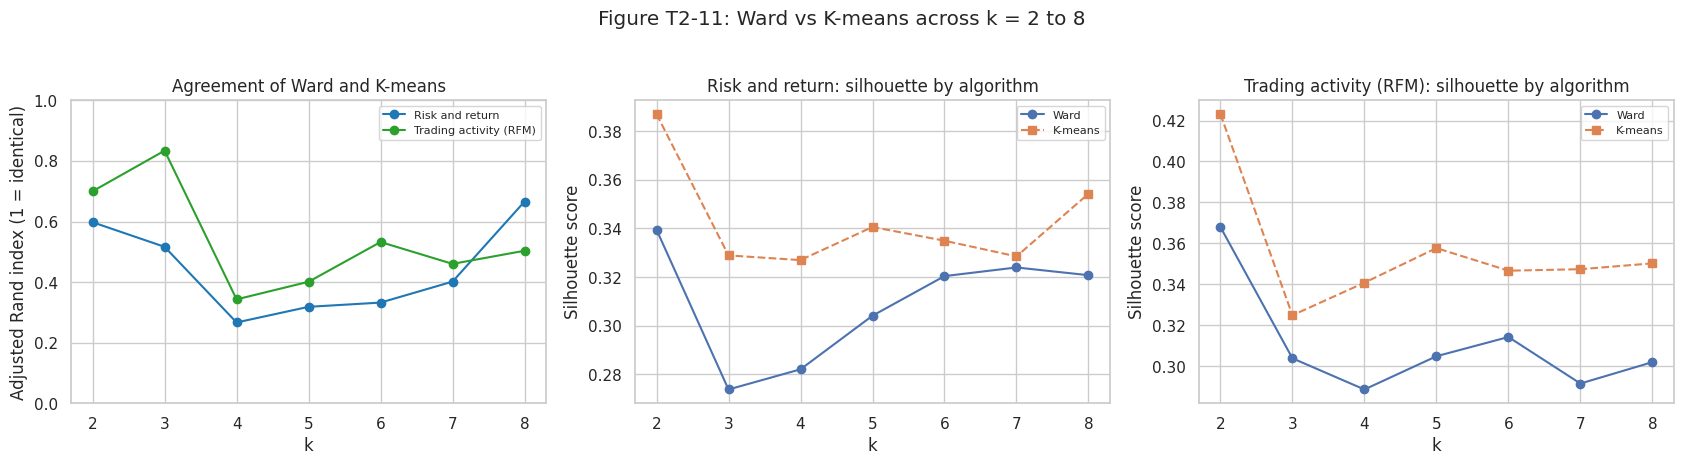

In [ ]:
# Ward vs K-means at EVERY k from 2 to 8, on the same shares
from scipy.special import comb

def ari_by_hand(a, b):
    """Adjusted Rand index from the contingency table: 1 = identical groupings, about 0 = no better than chance."""
    t_ = pd.crosstab(np.asarray(a), np.asarray(b)).to_numpy()
    sum_ij, sum_a, sum_b, tot = comb(t_, 2).sum(), comb(t_.sum(axis=1), 2).sum(), comb(t_.sum(axis=0), 2).sum(), comb(t_.sum(), 2)
    expected = sum_a * sum_b / tot
    return (sum_ij - expected) / (0.5 * (sum_a + sum_b) - expected)

verify("ARI matches an independent contingency-table calculation (Ward vs K-means, RFM)",
       np.isclose(ari_by_hand(assign["RFM_Ward"], assign["RFM_KMeans"]), adjusted_rand_score(assign["RFM_Ward"], assign["RFM_KMeans"])))
verify("ARI of a clustering with itself is 1", adjusted_rand_score(assign["RR_Ward"], assign["RR_Ward"]) == 1.0)

rows = []
for tag, Z in [("Risk and return", Z_rr), ("Trading activity (RFM)", Z_act)]:
    Xz = Z.to_numpy(); Lz = linkage(Xz, method="ward", metric="euclidean")
    for k in K_RANGE:
        w, km_ = relabel_by_size(fcluster(Lz, k, "maxclust")), fit_kmeans(Z, k)
        ct_ = pd.crosstab(w, km_).to_numpy(); r_, c_ = linear_sum_assignment(-ct_)
        rows.append({"Matrix": tag, "k": k, "ARI": adjusted_rand_score(w, km_), "NMI": normalized_mutual_info_score(w, km_),
                     "Same_cluster_%": 100 * ct_[r_, c_].sum() / ct_.sum(),
                     "Silhouette_Ward": silhouette_score(Xz, w), "Silhouette_KMeans": silhouette_score(Xz, km_)})
agree_k = pd.DataFrame(rows)
agree_k.to_csv(f"{DATA}/t2_algorithm_comparison_all_k.csv", index=False)
display(agree_k.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for tag, colr in [("Risk and return", "tab:blue"), ("Trading activity (RFM)", "tab:green")]:
    d_ = agree_k[agree_k["Matrix"] == tag]
    axes[0].plot(d_["k"], d_["ARI"], "o-", color=colr, label=tag)
for ax, tag in [(axes[1], "Risk and return"), (axes[2], "Trading activity (RFM)")]:
    d_ = agree_k[agree_k["Matrix"] == tag]
    ax.plot(d_["k"], d_["Silhouette_Ward"], "o-", label="Ward"); ax.plot(d_["k"], d_["Silhouette_KMeans"], "s--", label="K-means")
    ax.set(title=f"{tag}: silhouette by algorithm", xlabel="k", ylabel="Silhouette score"); ax.legend(fontsize=8)
axes[0].set(title="Agreement of Ward and K-means", xlabel="k", ylabel="Adjusted Rand index (1 = identical)", ylim=(0, 1)); axes[0].legend(fontsize=8)
plt.suptitle("Figure T2-11: Ward vs K-means across k = 2 to 8", y=1.03); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig11_algorithm_comparison_all_k.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# Sensitivity of the preparation choices (supports the discussion of skew and outliers in 2.1)
def sens(Z_alt, base_col, k):
    return adjusted_rand_score(assign[base_col], fit_ward(Z_alt, k))
rows = []
Z_alt1 = standardise(pd.DataFrame({"R": np.log1p(common["R"]), "F": np.log1p(common["F"]), "log1p_M": common["log1p_M"]}))[0]
Z_alt2 = pd.DataFrame(RobustScaler().fit_transform(common[ACT]), index=common.index, columns=ACT)
Z_alt3 = pd.DataFrame(RobustScaler().fit_transform(common[RR]), index=common.index, columns=RR)
rows.append(("RFM Ward vs same k with log1p also on R and F", sens(Z_alt1, "RFM_Ward", final_k["act_ward"])))
rows.append(("RFM Ward vs same k with robust scaling (median and IQR)", sens(Z_alt2, "RFM_Ward", final_k["act_ward"])))
rows.append(("Risk-return Ward vs same k with robust scaling", sens(Z_alt3, "RR_Ward", final_k["rr_ward"])))
skew_sens = pd.DataFrame(rows, columns=["Alternative treatment", "ARI vs baseline Ward"]).set_index("Alternative treatment")
skew_sens.to_csv(f"{DATA}/t2_preparation_sensitivity.csv")
display(skew_sens.round(3))
print("ARI near 1 means the choice barely matters; a low ARI means the clusters depend on how skew and outliers are handled.")

,ARI vs baseline Ward
Alternative treatment,
RFM Ward vs same k with log1p also on R and F,0.773
RFM Ward vs same k with robust scaling (median and IQR),0.742
Risk-return Ward vs same k with robust scaling,0.554


ARI near 1 means the choice barely matters; a low ARI means the clusters depend on how skew and outliers are handled.


##  Task 2.5.1 Correlation analysis (R, F and log1p(M))

Standardising gives every feature the **same variance**, but not independent information. If two standardised features move together, they point in nearly the same direction, so the distance between two shares reflects that shared signal **twice**. Trading activity can therefore carry more weight than the three-feature count suggests.


Pearson correlations:


,R,F,log1p_M
R,1.000,-0.346,0.152
F,-0.346,1.000,0.013
log1p_M,0.152,0.013,1.000


Spearman (rank) correlations:


,R,F,log1p_M
R,1.000,-0.196,0.137
F,-0.196,1.000,-0.048
log1p_M,0.137,-0.048,1.000


For comparison, raw M instead of log1p(M): corr(R, M) = 0.300, corr(F, M) = 0.014

Variance along the principal axes of the standardised RFM matrix: [1.374 1.009 0.617] (sums to 3)
First axis carries 45.8% of all variance (33.3% would mean fully independent features)
Effective number of independent dimensions: 2.74 of 3

Variance inflation factors (1 = no overlap; above 5 = strong overlap):


,R,F,log1p_M
VIF,1.17,1.14,1.03



Share of each feature's variance that lies BETWEEN clusters (eta squared, 0 to 1):


,RFM_Ward,RFM_KMeans
R,0.641,0.660
F,0.091,0.135
log1p_M,0.001,0.010


A larger value means that feature separates the clusters more. It describes these clusters; it does not prove dominance.


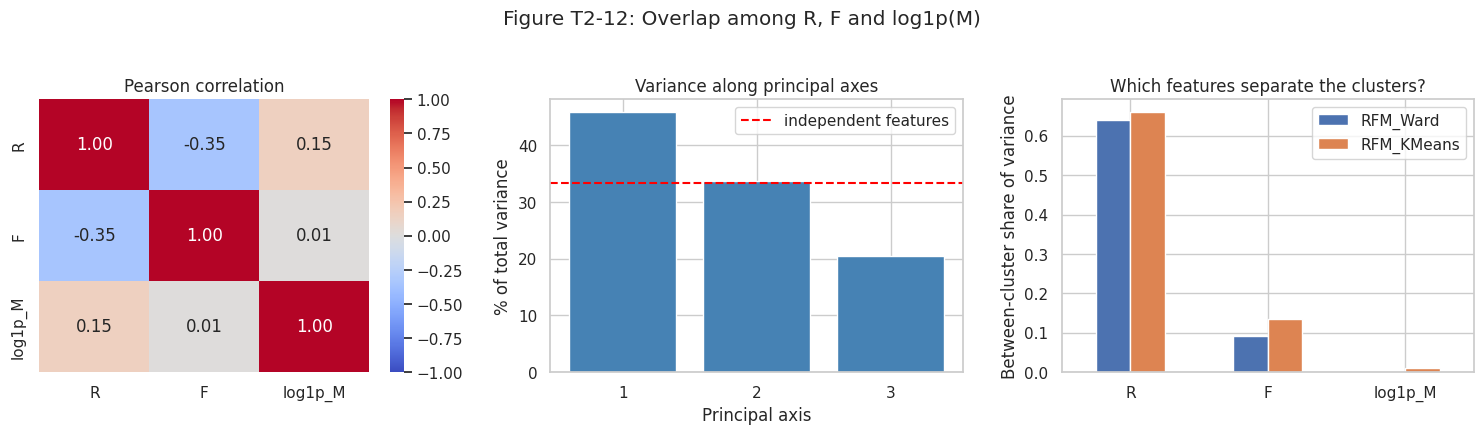

In [ ]:
pear = common[ACT].corr(method="pearson"); spear = common[ACT].corr(method="spearman")
print("Pearson correlations:"); display(pear.round(3))
print("Spearman (rank) correlations:"); display(spear.round(3))
pear.to_csv(f"{DATA}/t2_rfm_correlations_pearson.csv"); spear.to_csv(f"{DATA}/t2_rfm_correlations_spearman.csv")
print("For comparison, raw M instead of log1p(M): corr(R, M) = %.3f, corr(F, M) = %.3f" % (common["R"].corr(common["M"]), common["F"].corr(common["M"])))

# How much independent information is there? Eigenvalues of the correlation matrix (equal to variance along principal axes)
eig = np.sort(np.linalg.eigvalsh(pear.to_numpy()))[::-1]
print("\nVariance along the principal axes of the standardised RFM matrix:", np.round(eig, 3), "(sums to 3)")
print("First axis carries %.1f%% of all variance (33.3%% would mean fully independent features)" % (100 * eig[0] / 3))
print("Effective number of independent dimensions: %.2f of 3" % (eig.sum() ** 2 / (eig ** 2).sum()))
vif = pd.Series(np.diag(np.linalg.inv(pear.to_numpy())), index=ACT, name="VIF")
print("\nVariance inflation factors (1 = no overlap; above 5 = strong overlap):"); display(vif.round(2).to_frame().T)

def eta_squared(x, lab):
    x = pd.Series(np.asarray(x, dtype=float)); lab = np.asarray(lab)
    ssb = sum((lab == c_).sum() * (x[lab == c_].mean() - x.mean()) ** 2 for c_ in np.unique(lab))
    return ssb / ((x - x.mean()) ** 2).sum()
eta = pd.DataFrame({sol: {f_: eta_squared(Z_act[f_], assign[sol]) for f_ in ACT} for sol in ["RFM_Ward", "RFM_KMeans"]})
print("\nShare of each feature's variance that lies BETWEEN clusters (eta squared, 0 to 1):"); display(eta.round(3))
print("A larger value means that feature separates the clusters more. It describes these clusters; it does not prove dominance.")
eta.to_csv(f"{DATA}/t2_rfm_eta_squared.csv")

# Figure T2-12
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.heatmap(pear, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0]); axes[0].set_title("Pearson correlation")
axes[1].bar(range(1, 4), 100 * eig / 3, color="steelblue"); axes[1].set_xticks([1, 2, 3])
axes[1].axhline(100 / 3, color="red", ls="--", label="independent features"); axes[1].legend()
axes[1].set(xlabel="Principal axis", ylabel="% of total variance", title="Variance along principal axes")
eta.plot.bar(ax=axes[2], rot=0); axes[2].set(ylabel="Between-cluster share of variance", title="Which features separate the clusters?")
plt.suptitle("Figure T2-12: Overlap among R, F and log1p(M)", y=1.03); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig12_rfm_correlation.png", dpi=150, bbox_inches="tight"); plt.show()

## Task 2.5.2 Removal of Monetary



PASSED: reduced matrix has the same shares as the full RFM matrix
PASSED: same number of clusters as the full RFM Ward solution
Adjusted Rand index, Ward RFM (k=2) vs Ward R and F only: 0.873
Membership counts (rows: full RFM, columns: R and F only):


RF_only_Ward,1,2
RFM_Ward,,
1,394,10
2,3,79



Traded value (M, USD bn) by cluster, full RFM:


,n,median_M_USD_bn,Q1,Q3
1,404,16.047,9.767,31.944
2,82,17.849,13.021,32.502


Traded value (M, USD bn) by cluster, R and F only:


,n,median_M_USD_bn,Q1,Q3
1,397,15.464,9.609,31.720
2,89,20.848,13.738,33.246



Share of log1p(M) variance lying between clusters (eta squared): {'RFM_Ward (with M)': 0.001, 'RF_only_Ward (M removed)': 0.004}
Kruskal-Wallis test that log1p(M) differs across the R and F only clusters: H = 4.57, p = 0.0326
Correlation of log1p(M) with F: 0.013 | with R: 0.152


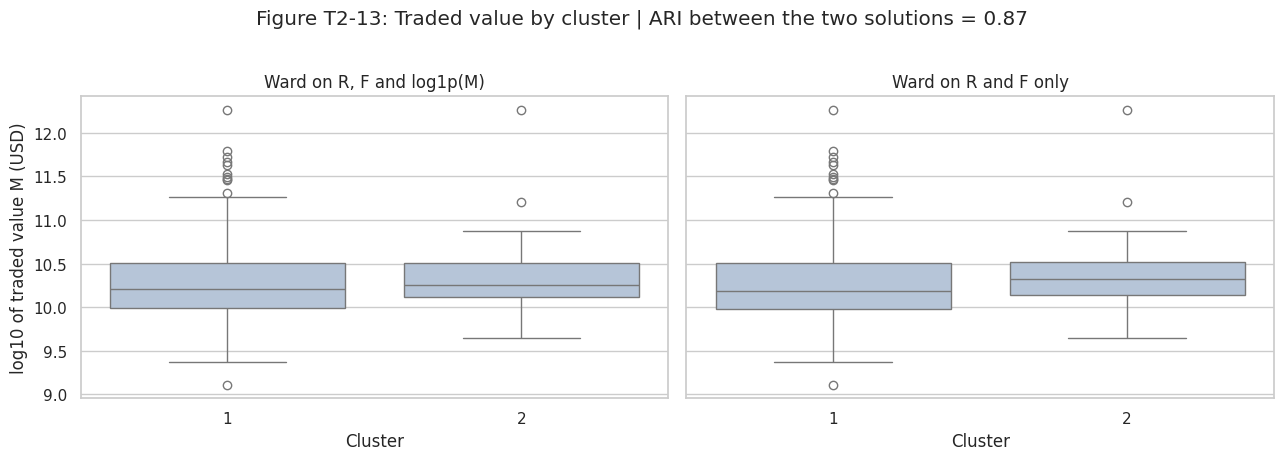

In [ ]:
k_rfm = final_k["act_ward"]
Z_rf, _ = standardise(common[["R", "F"]])                                   # standardised afresh: mean 0, sd 1 on the reduced matrix
verify("reduced matrix has the same shares as the full RFM matrix", Z_rf.index.equals(Z_act.index))
assign["RF_only_Ward"] = fit_ward(Z_rf, k_rfm)
verify("same number of clusters as the full RFM Ward solution", assign["RF_only_Ward"].nunique() == k_rfm)

ari_rf = adjusted_rand_score(assign["RFM_Ward"], assign["RF_only_Ward"])
print(f"Adjusted Rand index, Ward RFM (k={k_rfm}) vs Ward R and F only: {ari_rf:.3f}")
print("Membership counts (rows: full RFM, columns: R and F only):")
display(pd.crosstab(assign["RFM_Ward"], assign["RF_only_Ward"]))

def m_profile(labels):
    g = disp.groupby(np.asarray(labels))["M_USD_bn"]
    out = pd.DataFrame({"n": g.size(), "median_M_USD_bn": g.median(), "Q1": g.quantile(0.25), "Q3": g.quantile(0.75)})
    return out.round(3)
print("\nTraded value (M, USD bn) by cluster, full RFM:"); display(m_profile(assign["RFM_Ward"]))
print("Traded value (M, USD bn) by cluster, R and F only:"); display(m_profile(assign["RF_only_Ward"]))

eta_m = {"RFM_Ward (with M)": eta_squared(common["log1p_M"], assign["RFM_Ward"]),
         "RF_only_Ward (M removed)": eta_squared(common["log1p_M"], assign["RF_only_Ward"])}
print("\nShare of log1p(M) variance lying between clusters (eta squared):", {k: round(float(v), 3) for k, v in eta_m.items()})
groups = [common.loc[assign["RF_only_Ward"] == c_, "log1p_M"] for c_ in np.unique(assign["RF_only_Ward"])]
print("Kruskal-Wallis test that log1p(M) differs across the R and F only clusters: H = %.2f, p = %.3g" % kruskal(*groups))
print("Correlation of log1p(M) with F: %.3f | with R: %.3f" % (common["log1p_M"].corr(common["F"]), common["log1p_M"].corr(common["R"])))
pd.DataFrame({"ARI": [ari_rf], "k": [k_rfm], **{f"eta2_logM_{k}": [v] for k, v in eta_m.items()}}).to_csv(f"{DATA}/t2_monetary_removal.csv", index=False)

# Figure T2-13: traded value across clusters, with and without M in the distance
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, col, title in [(axes[0], "RFM_Ward", "Ward on R, F and log1p(M)"), (axes[1], "RF_only_Ward", "Ward on R and F only")]:
    sns.boxplot(x=assign[col].to_numpy(), y=np.log10(common["M"].to_numpy()), ax=ax, color="lightsteelblue")
    ax.set_xlabel("Cluster"); ax.set_title(title)
axes[0].set_ylabel("log10 of traded value M (USD)")
plt.suptitle(f"Figure T2-13: Traded value by cluster | ARI between the two solutions = {ari_rf:.2f}", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig13_monetary_removal.png", dpi=150, bbox_inches="tight"); plt.show()

PASSED: fresh standardisation leaves the R and F z-scores unchanged (each column is standardised on its own)
So removing M changes the clusters only through the distance: M's contribution is dropped, not rescaled.
PASSED: eta squared matches an independent within-cluster calculation (reduced Ward, k = 3)


,k,ARI_full_vs_reduced,Silhouette_full,Silhouette_reduced,eta2_logM_full,eta2_logM_reduced
0,2,0.873,0.368,0.524,0.001,0.004
1,3,0.291,0.304,0.488,0.516,0.004
2,4,0.203,0.289,0.516,0.524,0.005
3,5,0.335,0.305,0.593,0.526,0.022
4,6,0.273,0.314,0.686,0.646,0.022
5,7,0.374,0.292,0.686,0.646,0.023
6,8,0.432,0.302,0.689,0.648,0.069


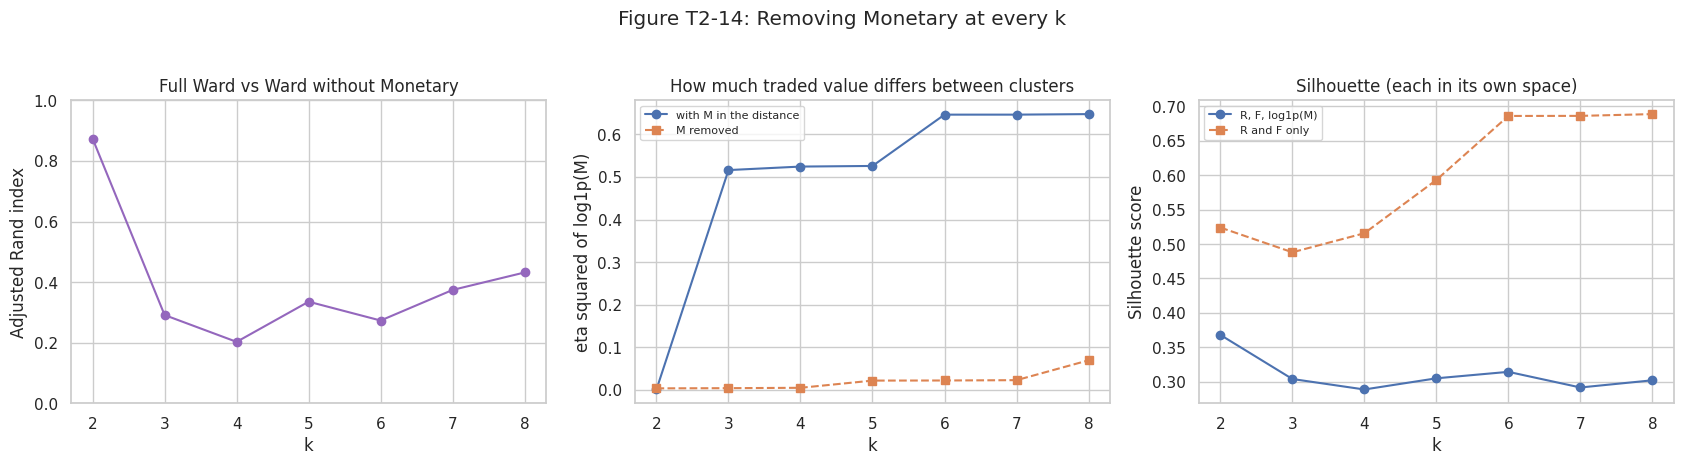

In [ ]:
# Monetary removal at EVERY k from 2 to 8 (the chosen k above is the one to report; this shows how general the finding is)
verify("fresh standardisation leaves the R and F z-scores unchanged (each column is standardised on its own)", np.allclose(Z_rf, Z_act[["R", "F"]]))
print("So removing M changes the clusters only through the distance: M's contribution is dropped, not rescaled.")
L_rf = linkage(Z_rf.to_numpy(), method="ward", metric="euclidean")
tv = common["log1p_M"]
rows = []
for k in K_RANGE:
    full, red = fcluster(L_act, k, "maxclust"), fcluster(L_rf, k, "maxclust")
    rows.append({"k": k, "ARI_full_vs_reduced": adjusted_rand_score(full, red),
                 "Silhouette_full": silhouette_score(Z_act, full), "Silhouette_reduced": silhouette_score(Z_rf, red),
                 "eta2_logM_full": eta_squared(tv, full), "eta2_logM_reduced": eta_squared(tv, red)})
removal_k = pd.DataFrame(rows)
sst = ((tv - tv.mean()) ** 2).sum(); red3 = fcluster(L_rf, 3, "maxclust")
verify("eta squared matches an independent within-cluster calculation (reduced Ward, k = 3)",
       np.isclose(removal_k.set_index("k").at[3, "eta2_logM_reduced"], 1 - sum(((tv[red3 == c_] - tv[red3 == c_].mean()) ** 2).sum() for c_ in np.unique(red3)) / sst))
removal_k.to_csv(f"{DATA}/t2_monetary_removal_all_k.csv", index=False)
display(removal_k.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(removal_k["k"], removal_k["ARI_full_vs_reduced"], "o-", color="tab:purple")
axes[0].set(title="Full Ward vs Ward without Monetary", xlabel="k", ylabel="Adjusted Rand index", ylim=(0, 1))
axes[1].plot(removal_k["k"], removal_k["eta2_logM_full"], "o-", label="with M in the distance"); axes[1].plot(removal_k["k"], removal_k["eta2_logM_reduced"], "s--", label="M removed")
axes[1].set(title="How much traded value differs between clusters", xlabel="k", ylabel="eta squared of log1p(M)"); axes[1].legend(fontsize=8)
axes[2].plot(removal_k["k"], removal_k["Silhouette_full"], "o-", label="R, F, log1p(M)"); axes[2].plot(removal_k["k"], removal_k["Silhouette_reduced"], "s--", label="R and F only")
axes[2].set(title="Silhouette (each in its own space)", xlabel="k", ylabel="Silhouette score"); axes[2].legend(fontsize=8)
plt.suptitle("Figure T2-14: Removing Monetary at every k", y=1.03); plt.tight_layout()
plt.savefig(f"{FIG}/t2_fig14_monetary_removal_all_k.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# Compare the two families of clusters on the same shares (used in Task 3.2.1) and prepare sector composition
rows = []
for a in ["RR_Ward", "RR_KMeans"]:
    for b in ["RFM_Ward", "RFM_KMeans"]:
        rows.append((a, b, adjusted_rand_score(assign[a], assign[b]), normalized_mutual_info_score(assign[a], assign[b])))
bridge = pd.DataFrame(rows, columns=["Risk-return solution", "RFM solution", "ARI", "NMI"])
bridge.to_csv(f"{DATA}/t2_riskreturn_vs_rfm_agreement.csv", index=False)
display(bridge.round(3))
print("Low values mean that risk-return groups and trading-activity groups are largely different segmentations of the same shares.")

for col in SOLUTIONS:
    comp = pd.crosstab(assign[col], common["Sector"], normalize="index").round(3)
    comp.to_csv(f"{DATA}/t2_sector_composition_{col}.csv")
print("Saved row-normalised sector composition tables for the four baseline solutions (for Task 3.2.1).")

# Final assignment table: one row per share
out = common[["Security", "Sector"] + FIVE + ["log1p_M"]].join(assign)
out.to_csv(f"{DATA}/t2_cluster_assignments.csv")
verify("assignment table has one row per share and no missing cluster labels", len(out) == len(common) and out[list(assign.columns)].notna().all().all())

with open(f"{DATA}/README_task2.txt", "w") as f:
    f.write(f"Input: {INPUT} ({len(common)} shares)\nSeed: {SEED} | K-means n_init: {N_INIT} | k range: {K_RANGE.start} to {K_RANGE.stop - 1}\n")
    f.write(f"Features: risk and return = {RR}; activity = {ACT}; each matrix standardised separately (StandardScaler)\n")
    f.write(f"Chosen k: {json.dumps(final_k)}\nWard: linkage='ward', Euclidean | Versions: {json.dumps(VERSIONS)}\n")
display(out.head())

,Risk-return solution,RFM solution,ARI,NMI
0,RR_Ward,RFM_Ward,0.029,0.002
1,RR_Ward,RFM_KMeans,0.019,0.001
2,RR_KMeans,RFM_Ward,0.014,0.001
3,RR_KMeans,RFM_KMeans,0.004,0.000


Low values mean that risk-return groups and trading-activity groups are largely different segmentations of the same shares.
Saved row-normalised sector composition tables for the four baseline solutions (for Task 3.2.1).
PASSED: assignment table has one row per share and no missing cluster labels


,Security,Sector,Mean_Weekly_Return,Weekly_Beta,R,F,M,log1p_M,RR_Ward,RR_KMeans,RFM_Ward,RFM_KMeans,RF_only_Ward
Ticker,,,,,,,,,,,,,
MMM,3M,Industrials,0.001142,0.869079,11,4,2.599146e+10,23.981034,1,1,1,1,1
AOS,A. O. Smith,Industrials,0.001991,1.042805,11,2,4.748980e+09,22.281196,1,1,1,1,1
ABT,Abbott Laboratories,Health Care,0.000971,0.583543,11,1,3.523027e+10,24.285172,1,1,1,1,1
ABBV,AbbVie,Health Care,0.003749,0.425366,11,3,6.837054e+10,24.948208,1,1,1,1,1
ACN,Accenture,Information Technology,0.002376,1.143300,11,2,5.199430e+10,24.674400,1,1,1,1,1


# Task 3 Business Intelligence and Critical Review

In [ ]:

import os, json, shutil, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
try:
    from IPython.display import display
except ImportError:
    display = print
sns.set_theme(style="whitegrid")

def verify(name, condition, hard=True):
    ok = bool(condition)
    print(("PASSED: " if ok else ("FAILED: " if hard else "REVIEW: ")) + name)
    if hard:
        assert ok, name
    return ok

NEEDED = [
 "assign",
 "common",
 "final_k",
 "SOLUTIONS",
 "disp",
 "pear",
 "eig",
 "vif",
 "eta",
 "eta_m",
 "ari_rf",
 "wk_ret",
 "bench_ret",
 "beta",
 "beta_close",
 "se",
 "b_first",
 "b_last",
 "sp500",
 "tickers",
 "keep",
 "inc",
 "features",
 "meta",
 "VERSIONS",
 "observation_date",
 "window",
 "dates",
 "adj",
 "close",
 "vol",
 "high_volume",
 "bench",
 "Z_rr",
 "Z_act",
 "Z_rf",
 "START",
 "END",
 "BENCH",
 "BASE_WINDOW",
 "ACTIVITY_WINDOW",
 "HIGH_VOL_MULT",
 "SEED",
 "N_INIT",
 "DATA",
 "FIG",
 "eta_squared"
]
missing = [n for n in NEEDED if n not in globals()]
assert not missing, "Run the Task 1 and Task 2 sections first, in this same session. Missing: " + ", ".join(missing)
palette = sns.color_palette("tab10", 10)
print("All Task 1 and Task 2 results found. Task 3 can run.")


All Task 1 and Task 2 results found. Task 3 can run.


In [ ]:
from scipy.stats import chi2_contingency

T3_RR, T3_RFM = "RR_Ward", "RFM_Ward"      # the two solutions to compare; switch to "RR_KMeans" / "RFM_KMeans" if you prefer
assert T3_RR in assign.columns and T3_RFM in assign.columns, "run Task 2 first"
overall_share = common["Sector"].value_counts(normalize=True)
print("Comparing:", SOLUTIONS[T3_RR][0], "with", SOLUTIONS[T3_RFM][0])
print("Clusters:", assign[T3_RR].nunique(), "risk-return |", assign[T3_RFM].nunique(), "RFM | shares:", len(common))

Comparing: Risk and return, Ward with Trading activity (RFM), Ward
Clusters: 2 risk-return | 2 RFM | shares: 486


##  Task 3.1 Data mart: evidence



In [ ]:
# 17.1 Build the data mart (SQLite star schema): 6 dimensions and 3 facts
MART = f"{DATA}/crm_data_mart.sqlite"
CALC_VERSION = "1.0"          # change this label when a rule or window changes and you re-run
if os.path.exists(MART): os.remove(MART)
con = sqlite3.connect(MART); con.execute("PRAGMA foreign_keys = ON")
DDL = '''
CREATE TABLE dim_sector (sector_key INTEGER PRIMARY KEY, sector TEXT UNIQUE);
CREATE TABLE dim_share (share_key INTEGER PRIMARY KEY, ticker TEXT UNIQUE, security TEXT, sector_key INTEGER REFERENCES dim_sector,
    in_clustering_set INTEGER, exclusion_reason TEXT);
CREATE TABLE dim_benchmark (benchmark_key INTEGER PRIMARY KEY, symbol TEXT, price_basis TEXT);
CREATE TABLE dim_date (date_key INTEGER PRIMARY KEY, trading_date TEXT UNIQUE, year INTEGER, month INTEGER, week_ending_friday TEXT);
CREATE TABLE dim_run (run_key INTEGER PRIMARY KEY, calc_version TEXT, constituents_retrieved TEXT, prices_downloaded TEXT, source TEXT,
    observation_date TEXT, rfm_start TEXT, rfm_end TEXT, base_window INTEGER, activity_window INTEGER, volume_multiple REAL,
    seed INTEGER, kmeans_n_init INTEGER, chosen_k TEXT, package_versions TEXT, file_md5 TEXT);
CREATE TABLE dim_solution (solution_key INTEGER PRIMARY KEY, solution_code TEXT UNIQUE, matrix_code TEXT, algorithm TEXT,
    features TEXT, k INTEGER, silhouette REAL);
CREATE TABLE fact_share_daily (date_key INTEGER REFERENCES dim_date, share_key INTEGER REFERENCES dim_share,
    benchmark_key INTEGER REFERENCES dim_benchmark, close REAL, adj_close REAL, volume REAL, traded_value_usd REAL,
    high_volume_flag INTEGER, benchmark_close REAL, PRIMARY KEY (date_key, share_key));
CREATE TABLE fact_share_features (run_key INTEGER REFERENCES dim_run, share_key INTEGER REFERENCES dim_share, mean_weekly_return REAL,
    weekly_beta REAL, recency_days REAL, frequency_days INTEGER, monetary_usd REAL, PRIMARY KEY (run_key, share_key));
CREATE TABLE fact_cluster_assignment (run_key INTEGER REFERENCES dim_run, share_key INTEGER REFERENCES dim_share,
    solution_key INTEGER REFERENCES dim_solution, cluster_no INTEGER NOT NULL, PRIMARY KEY (run_key, share_key, solution_key));
'''
con.executescript(DDL); open(f"{DATA}/data_mart_schema.sql", "w").write(DDL.strip() + "\n")
put = lambda df, t: df.to_sql(t, con, if_exists="append", index=False, chunksize=50000)

sec = {s_: i_ + 1 for i_, s_ in enumerate(sorted(sp500["Sector"].unique()))}
put(pd.DataFrame({"sector_key": list(sec.values()), "sector": list(sec.keys())}), "dim_sector")
sk, sp = {t_: i_ + 1 for i_, t_ in enumerate(tickers)}, sp500.set_index("Ticker")
put(pd.DataFrame({"share_key": list(sk.values()), "ticker": tickers, "security": sp.loc[tickers, "Security"].to_numpy(),
                  "sector_key": sp.loc[tickers, "Sector"].map(sec).to_numpy(), "in_clustering_set": inc.loc[tickers, "Common_Valid"].astype(int).to_numpy(),
                  "exclusion_reason": [x_ or None for x_ in inc.loc[tickers, "Exclusion_Reason"]]}), "dim_share")
put(pd.DataFrame([{"benchmark_key": 1, "symbol": BENCH, "price_basis": "price index: Adj Close equals Close"}]), "dim_benchmark")
fri = dates + pd.to_timedelta((4 - dates.dayofweek) % 7, unit="D")
put(pd.DataFrame({"date_key": dates.strftime("%Y%m%d").astype(int), "trading_date": dates.strftime("%Y-%m-%d"), "year": dates.year,
                  "month": dates.month, "week_ending_friday": fri.strftime("%Y-%m-%d")}), "dim_date")
put(pd.DataFrame([{"run_key": 1, "calc_version": CALC_VERSION, "constituents_retrieved": str(sp500["Retrieved"].iloc[0]), "prices_downloaded": meta["downloaded_utc"],
                   "source": meta["source"], "observation_date": str(observation_date.date()), "rfm_start": str(window[0].date()), "rfm_end": str(window[-1].date()),
                   "base_window": BASE_WINDOW, "activity_window": ACTIVITY_WINDOW, "volume_multiple": HIGH_VOL_MULT, "seed": SEED, "kmeans_n_init": N_INIT,
                   "chosen_k": json.dumps(final_k), "package_versions": json.dumps(VERSIONS), "file_md5": json.dumps(meta["md5"])}]), "dim_run")

SOL = {"RR_Ward": ("RR", "Ward", "Mean_Weekly_Return, Weekly_Beta", Z_rr), "RR_KMeans": ("RR", "K-means", "Mean_Weekly_Return, Weekly_Beta", Z_rr),
       "RFM_Ward": ("RFM", "Ward", "R, F, log1p(M)", Z_act), "RFM_KMeans": ("RFM", "K-means", "R, F, log1p(M)", Z_act),
       "RF_only_Ward": ("RF", "Ward", "R, F", Z_rf)}
assert set(SOL) <= set(assign.columns), "run the Task 2 sections first (they create all five cluster solutions)"
put(pd.DataFrame([{"solution_key": i_ + 1, "solution_code": c_, "matrix_code": m_, "algorithm": a_, "features": f_, "k": int(assign[c_].nunique()),
                   "silhouette": float(silhouette_score(Z_.to_numpy(), assign[c_]))} for i_, (c_, (m_, a_, f_, Z_)) in enumerate(SOL.items())]), "dim_solution")
solkey = dict(zip(SOL, range(1, len(SOL) + 1)))

def long(df, name):
    d = df.reindex(index=dates, columns=keep); d.index.name = "d"
    return d.reset_index().melt(id_vars="d", var_name="ticker", value_name=name)
f = long(close, "close")
for n_, df_ in [("adj_close", adj), ("volume", vol), ("high_volume_flag", high_volume.astype(float))]:
    f[n_] = long(df_, n_)[n_].to_numpy()
f["date_key"], f["share_key"], f["benchmark_key"] = f["d"].dt.strftime("%Y%m%d").astype(int), f["ticker"].map(sk), 1
f["traded_value_usd"], f["benchmark_close"] = f["close"] * f["volume"], f["d"].map(bench["Close"])
put(f[["date_key", "share_key", "benchmark_key", "close", "adj_close", "volume", "traded_value_usd", "high_volume_flag", "benchmark_close"]], "fact_share_daily")

ft = features.loc[common.index]
put(pd.DataFrame({"run_key": 1, "share_key": [sk[t_] for t_ in ft.index], "mean_weekly_return": ft["Mean_Weekly_Return"].to_numpy(),
                  "weekly_beta": ft["Weekly_Beta"].to_numpy(), "recency_days": ft["R"].to_numpy(), "frequency_days": ft["F"].to_numpy(),
                  "monetary_usd": ft["M"].to_numpy()}), "fact_share_features")
ca = assign[list(SOL)].melt(ignore_index=False, var_name="solution_code", value_name="cluster_no").rename_axis("ticker").reset_index()
ca["run_key"], ca["share_key"], ca["solution_key"] = 1, ca["ticker"].map(sk), ca["solution_code"].map(solkey)
put(ca[["run_key", "share_key", "solution_key", "cluster_no"]], "fact_cluster_assignment")
con.commit()

GRAIN = {"dim_sector": "one row per GICS sector", "dim_share": "one row per ticker on the list (with its validation status)", "dim_benchmark": "one row per benchmark",
         "dim_date": "one row per trading session", "dim_run": "one row per calculation run", "dim_solution": "one row per clustering solution",
         "fact_share_daily": "share x trading day", "fact_share_features": "share x run", "fact_cluster_assignment": "share x run x solution"}
inventory = pd.DataFrame([{"table": t_, "grain": g_, "rows": con.execute(f"SELECT COUNT(*) FROM {t_}").fetchone()[0]} for t_, g_ in GRAIN.items()])
inventory.to_csv(f"{DATA}/data_mart_inventory.csv", index=False)
display(inventory); print(f"Saved {MART} ({os.path.getsize(MART) / 1e6:.1f} MB)")

,table,grain,rows
0,dim_sector,one row per GICS sector,11
1,dim_share,one row per ticker on the list (with its valid...,503
2,dim_benchmark,one row per benchmark,1
3,dim_date,one row per trading session,1005
4,dim_run,one row per calculation run,1
5,dim_solution,one row per clustering solution,5
6,fact_share_daily,share x trading day,488430
7,fact_share_features,share x run,486
8,fact_cluster_assignment,share x run x solution,2430


Saved data/crm_data_mart.sqlite (36.6 MB)


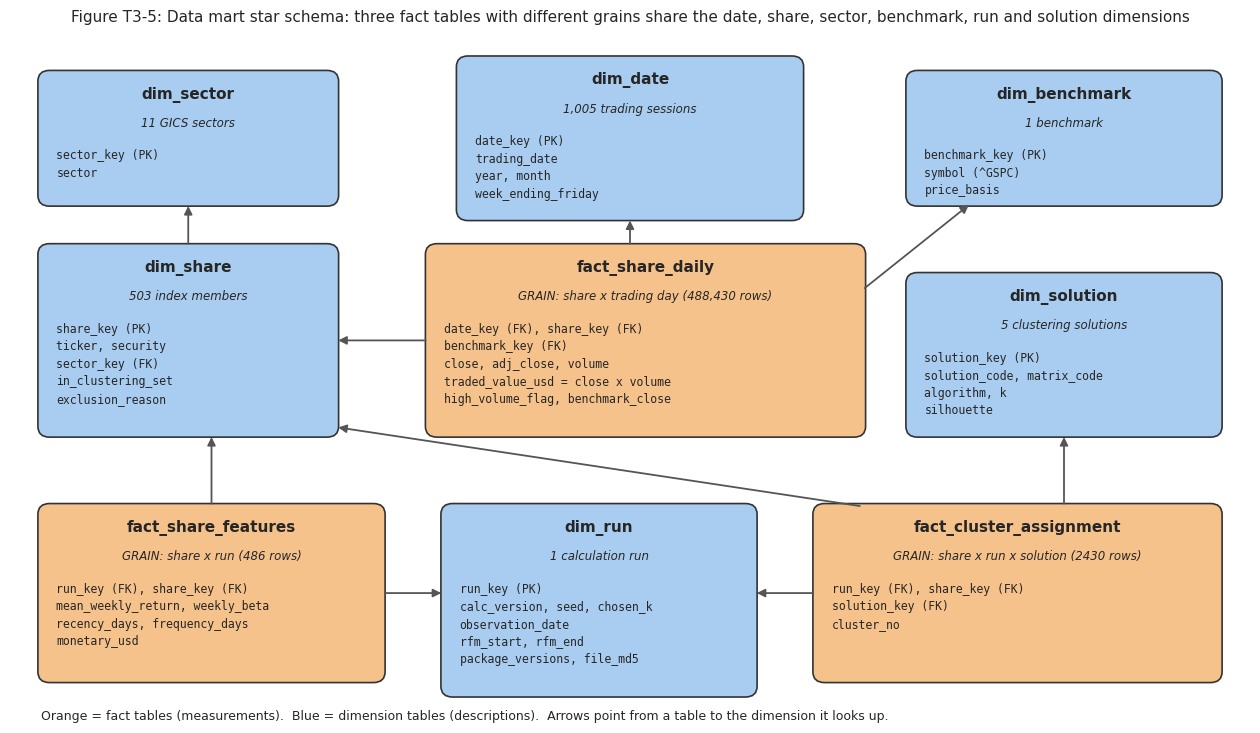

PASSED: the arrows drawn are exactly the foreign keys in the database
PASSED: every table in the database is drawn


491

In [ ]:
# 17.2 Star-schema diagram, drawn from the real database (so the figure cannot disagree with the data)
from matplotlib.patches import FancyBboxPatch
n = lambda t_: con.execute(f"SELECT COUNT(*) FROM {t_}").fetchone()[0]
FACT, DIM = "#f6c28b", "#a9cdf0"
T = {  # table: (x, y, width, height, grain line, fields, colour) on a 160 x 96 canvas
 "dim_sector":   (4, 72, 38, 18, f"{n('dim_sector')} GICS sectors", ["sector_key (PK)", "sector"], DIM),
 "dim_date":     (58, 70, 44, 22, f"{n('dim_date'):,} trading sessions", ["date_key (PK)", "trading_date", "year, month", "week_ending_friday"], DIM),
 "dim_benchmark": (116, 72, 40, 18, f"{n('dim_benchmark')} benchmark", ["benchmark_key (PK)", "symbol (^GSPC)", "price_basis"], DIM),
 "dim_share":    (4, 40, 38, 26, f"{n('dim_share')} index members", ["share_key (PK)", "ticker, security", "sector_key (FK)", "in_clustering_set", "exclusion_reason"], DIM),
 "fact_share_daily": (54, 40, 56, 26, f"GRAIN: share x trading day ({n('fact_share_daily'):,} rows)",
                  ["date_key (FK), share_key (FK)", "benchmark_key (FK)", "close, adj_close, volume", "traded_value_usd = close x volume", "high_volume_flag, benchmark_close"], FACT),
 "dim_solution": (116, 40, 40, 22, f"{n('dim_solution')} clustering solutions", ["solution_key (PK)", "solution_code, matrix_code", "algorithm, k", "silhouette"], DIM),
 "fact_share_features": (4, 6, 44, 24, f"GRAIN: share x run ({n('fact_share_features')} rows)", ["run_key (FK), share_key (FK)", "mean_weekly_return, weekly_beta", "recency_days, frequency_days", "monetary_usd"], FACT),
 "dim_run":      (56, 4, 40, 26, f"{n('dim_run')} calculation run", ["run_key (PK)", "calc_version, seed, chosen_k", "observation_date", "rfm_start, rfm_end", "package_versions, file_md5"], DIM),
 "fact_cluster_assignment": (104, 6, 52, 24, f"GRAIN: share x run x solution ({n('fact_cluster_assignment')} rows)", ["run_key (FK), share_key (FK)", "solution_key (FK)", "cluster_no"], FACT),
}
LINKS = [("fact_share_daily", "dim_date", (80, 66), (80, 70)), ("fact_share_daily", "dim_share", (54, 53), (42, 53)), ("fact_share_daily", "dim_benchmark", (110, 60), (124, 72)),
         ("dim_share", "dim_sector", (23, 66), (23, 72)), ("fact_share_features", "dim_share", (26, 30), (26, 40)), ("fact_share_features", "dim_run", (48, 18), (56, 18)),
         ("fact_cluster_assignment", "dim_run", (104, 18), (96, 18)), ("fact_cluster_assignment", "dim_solution", (136, 30), (136, 40)),
         ("fact_cluster_assignment", "dim_share", (110, 30), (42, 41))]
fig, ax = plt.subplots(figsize=(16, 9)); ax.set_xlim(0, 160); ax.set_ylim(0, 96); ax.axis("off")
for name_, (x, y, w, h, grain, fields, colour) in T.items():
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.4,rounding_size=1.5", fc=colour, ec="#333333", lw=1.2))
    ax.text(x + w / 2, y + h - 1.8, name_, ha="center", va="top", fontsize=11, fontweight="bold")
    ax.text(x + w / 2, y + h - 6, grain, ha="center", va="top", fontsize=8.5, style="italic")
    ax.text(x + 2, y + h - 10.5, "\n".join(fields), ha="left", va="top", fontsize=8.3, linespacing=1.45, family="monospace")
for _, _, p_, q_ in LINKS:
    ax.annotate("", xy=q_, xytext=p_, arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1.3))
ax.text(4, 0.5, "Orange = fact tables (measurements).  Blue = dimension tables (descriptions).  Arrows point from a table to the dimension it looks up.", fontsize=9)
ax.set_title("Figure T3-5: Data mart star schema: three fact tables with different grains share the date, share, sector, benchmark, run and solution dimensions", fontsize=11)
plt.savefig(f"{FIG}/t3_fig5_star_schema.png", dpi=150, bbox_inches="tight"); plt.show()
db_links = {(t_, fk[2]) for t_ in T for fk in con.execute(f"PRAGMA foreign_key_list({t_})")}
verify("the arrows drawn are exactly the foreign keys in the database", {(a_, b_) for a_, b_, _, _ in LINKS} == db_links)
verify("every table in the database is drawn", {r_[0] for r_ in con.execute("SELECT name FROM sqlite_master WHERE type = 'table'")} == set(T))
open(f"{DATA}/data_mart_erd.md", "w").write('''```mermaid
erDiagram
    dim_sector ||--o{ dim_share : classifies
    dim_share ||--o{ fact_share_daily : observed
    dim_date ||--o{ fact_share_daily : on
    dim_benchmark ||--o{ fact_share_daily : compared_with
    dim_run ||--o{ fact_share_features : produced_in
    dim_share ||--o{ fact_share_features : describes
    dim_run ||--o{ fact_cluster_assignment : produced_in
    dim_share ||--o{ fact_cluster_assignment : assigned
    dim_solution ||--o{ fact_cluster_assignment : by
```
''')

In [ ]:
# 17.3 Evidence of consistency: recompute F, M, R and a cluster profile FROM THE DATABASE with SQL and compare with the notebook
q = lambda s_: pd.read_sql_query(s_, con)
verify("every foreign key resolves", con.execute("PRAGMA foreign_key_check").fetchall() == [])
verify("grain: one row per retained share and trading day", n("fact_share_daily") == len(keep) * len(dates))
verify("grain: one assignment per clustered share in every solution", n("fact_cluster_assignment") == len(common) * len(SOL))

stored = q("SELECT s.ticker, f.recency_days R, f.frequency_days F, f.monetary_usd M FROM fact_share_features f JOIN dim_share s USING (share_key)").set_index("ticker")
sql = q('''SELECT s.ticker,
    SUM(CASE WHEN t.trading_date BETWEEN r.rfm_start AND r.rfm_end THEN d.high_volume_flag END) AS F,
    SUM(CASE WHEN t.trading_date BETWEEN r.rfm_start AND r.rfm_end THEN d.traded_value_usd END) AS M,
    CAST(julianday(r.observation_date) - julianday(MAX(CASE WHEN d.high_volume_flag = 1 THEN t.trading_date END)) AS INTEGER) AS R
    FROM fact_share_daily d JOIN dim_date t USING (date_key) JOIN dim_share s USING (share_key) JOIN dim_run r ON r.run_key = 1
    GROUP BY s.ticker''').set_index("ticker").reindex(stored.index)
verify("F, M and R recomputed in SQL from the daily facts equal the notebook",
       (sql["F"] == stored["F"]).all() and np.allclose(sql["M"], stored["M"], rtol=1e-9) and (sql["R"].fillna(-1) == stored["R"].fillna(-1)).all())

prof = q('''SELECT a.cluster_no AS cluster, COUNT(*) AS n, AVG(f.recency_days) AS R, AVG(f.frequency_days) AS F, AVG(f.monetary_usd) AS M
            FROM fact_cluster_assignment a JOIN dim_solution s USING (solution_key) JOIN fact_share_features f ON f.share_key = a.share_key AND f.run_key = a.run_key
            WHERE s.solution_code = 'RFM_Ward' GROUP BY a.cluster_no ORDER BY a.cluster_no''')
verify("an RFM Ward cluster profile built in SQL equals the notebook",
       np.allclose(prof[["R", "F", "M"]], common.groupby(assign["RFM_Ward"])[["R", "F", "M"]].mean(), rtol=1e-9))
display(prof.round(2))

PASSED: every foreign key resolves
PASSED: grain: one row per retained share and trading day
PASSED: grain: one assignment per clustered share in every solution
PASSED: F, M and R recomputed in SQL from the daily facts equal the notebook
PASSED: an RFM Ward cluster profile built in SQL equals the notebook


,cluster,n,R,F,M
0,1,404,12.72,3.17,3.783020e+10
1,2,82,58.30,2.10,4.715898e+10


### 3.1.2 Provenance and calculation history

Everything needed to reproduce a result is kept **with the run**: sources and dates, windows, the observation date, parameters, package versions, the file fingerprints (md5) and every cluster assignment.
The proof below **rebuilds all five clustering solutions from the stored mart alone** (the standardised matrices are recreated from `fact_share_features`) and compares them with the stored assignments using the adjusted Rand index (1 = identical partitions).

In [ ]:
import hashlib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans

print("The run record (dim_run):"); display(q("SELECT * FROM dim_run").T.rename(columns={0: "run 1"}))
run = q("SELECT * FROM dim_run WHERE run_key = 1").iloc[0]

# (a) source-file lineage: do the files still match the fingerprints recorded when the data were downloaded?
md5_of = lambda p_: hashlib.md5(open(p_, "rb").read()).hexdigest()
rec = json.loads(run["file_md5"])
lineage = pd.DataFrame([{"file": f_, "recorded_md5": h_[:8], "current_md5": md5_of(f"{DATA}/{f_}")[:8], "size_MB": round(os.path.getsize(f"{DATA}/{f_}") / 1e6, 2)} for f_, h_ in rec.items()])
lineage["unchanged"] = lineage["recorded_md5"] == lineage["current_md5"]
lineage.to_csv(f"{DATA}/data_mart_lineage.csv", index=False); display(lineage)
verify("every source file still matches the md5 recorded in dim_run", lineage["unchanged"].all())

# (b) reproducibility: rebuild every clustering from the stored mart only
feat = q("SELECT s.ticker, f.* FROM fact_share_features f JOIN dim_share s USING (share_key)").set_index("ticker")
feat["log1p_monetary"] = np.log1p(feat["monetary_usd"])
COLS = {"RR": ["mean_weekly_return", "weekly_beta"], "RFM": ["recency_days", "frequency_days", "log1p_monetary"], "RF": ["recency_days", "frequency_days"]}
sols = q("SELECT * FROM dim_solution ORDER BY solution_key")
stored_cl = q("SELECT s.ticker, a.solution_key, a.cluster_no FROM fact_cluster_assignment a JOIN dim_share s USING (share_key)").pivot(index="ticker", columns="solution_key", values="cluster_no")

def rebuild(r_, seed):
    X = StandardScaler().fit_transform(feat[COLS[r_.matrix_code]])
    if r_.algorithm == "Ward":
        return X, AgglomerativeClustering(n_clusters=int(r_.k), linkage="ward").fit_predict(X)
    return X, KMeans(n_clusters=int(r_.k), n_init=int(run["kmeans_n_init"]), random_state=seed).fit_predict(X)

rows = []
for r_ in sols.itertuples():
    old = stored_cl.loc[feat.index, r_.solution_key].to_numpy()
    X_, again = rebuild(r_, int(run["seed"]))
    other = adjusted_rand_score(old, rebuild(r_, 7)[1]) if r_.algorithm == "K-means" else np.nan      # Ward has no random element
    rows.append({"solution": r_.solution_code, "algorithm": r_.algorithm, "k": r_.k, "ARI_rebuilt_vs_stored": adjusted_rand_score(old, again),
                 "silhouette_stored": r_.silhouette, "silhouette_rebuilt": silhouette_score(X_, old), "ARI_other_seed_vs_stored": other})
repro = pd.DataFrame(rows); repro.to_csv(f"{DATA}/data_mart_reproducibility.csv", index=False)
display(repro.round(4))
verify("all five solutions are reproduced exactly from the stored mart (ARI = 1)", (repro["ARI_rebuilt_vs_stored"] > 0.999999).all())
verify("the stored silhouettes equal the silhouettes recomputed from the mart", np.allclose(repro["silhouette_stored"], repro["silhouette_rebuilt"]))
print("K-means rerun with a different seed (7): ARI against the stored solution shows how much the seed matters (Ward has no seed).")

The run record (dim_run):


,run 1
run_key,1
calc_version,1.0
constituents_retrieved,2026-11-20 08:32 UTC
prices_downloaded,2026-11-20 08:34 UTC
source,Yahoo Finance via yfinance 0.2.66
observation_date,2024-12-31
rfm_start,2024-10-07
rfm_end,2024-12-31
base_window,20
activity_window,60


,file,recorded_md5,current_md5,size_MB,unchanged
0,adj_close.csv,36600cc5,36600cc5,9.03,True
1,close.csv,62b03b7e,62b03b7e,8.84,True
2,volume.csv,320d3fdd,320d3fdd,3.94,True
3,dividends.csv,9f2f6867,9f2f6867,2.01,True
4,splits.csv,d67afe8f,d67afe8f,2.00,True
5,gspc.csv,1b172fd7,1b172fd7,0.05,True
6,sp500_constituents.csv,1f907b59,1f907b59,0.04,True


PASSED: every source file still matches the md5 recorded in dim_run


,solution,algorithm,k,ARI_rebuilt_vs_stored,silhouette_stored,silhouette_rebuilt,ARI_other_seed_vs_stored
0,RR_Ward,Ward,2,1.0,0.3395,0.3395,NaN
1,RR_KMeans,K-means,2,1.0,0.3869,0.3869,1.0
2,RFM_Ward,Ward,2,1.0,0.3680,0.3680,NaN
3,RFM_KMeans,K-means,2,1.0,0.4231,0.4231,1.0
4,RF_only_Ward,Ward,2,1.0,0.5239,0.5239,NaN


PASSED: all five solutions are reproduced exactly from the stored mart (ARI = 1)
PASSED: the stored silhouettes equal the silhouettes recomputed from the mart
K-means rerun with a different seed (7): ARI against the stored solution shows how much the seed matters (Ward has no seed).


### 3.1.3  Stakeholder support

PASSED: Q1: the activity monitor equals the share of flagged shares per day in the notebook
PASSED: Q2: sector event counts equal the notebook's Frequency summed by sector
PASSED: Q3: the segment make-up by sector equals the notebook's crosstab
PASSED: Q4: window returns from the mart equal Adj Close at the end / before the start - 1 in the notebook
PASSED: Q4: the index return equals the benchmark level at the end / before the start - 1
Q1 five days with the largest share of shares on high volume:


,share_flagged
date,
2024-12-20,72.8
2023-12-15,65.6
2024-09-20,63.8
2022-12-16,58.2
2021-09-17,57.0


Q2 high-volume days per share by sector (RFM window):


,events,shares,events_per_share
sector,,,
Communication Services,75,20,3.75
Health Care,194,58,3.34
Industrials,247,78,3.17
Real Estate,93,30,3.10
Information Technology,222,74,3.00
Consumer Staples,91,32,2.84
Consumer Discretionary,133,47,2.83
Financials,207,74,2.80
Utilities,83,30,2.77


Q3 RFM Ward segments by sector (number of shares):


cluster,1,2
sector,,
Communication Services,16,4
Consumer Discretionary,38,9
Consumer Staples,25,7
Energy,18,2
Financials,64,10
Health Care,49,9
Industrials,72,6
Information Technology,56,18
Materials,15,8


Q4 median share return minus the index, by sector (RFM window):


,median_share_return,index_return,median_minus_index
sector,,,
Communication Services,8.49,2.27,6.22
Consumer Discretionary,4.15,2.27,1.88
Consumer Staples,-5.72,2.27,-7.99
Energy,-11.53,2.27,-13.80
Financials,5.59,2.27,3.32
Health Care,-7.05,2.27,-9.32
Industrials,-2.31,2.27,-4.58
Information Technology,1.94,2.27,-0.33
Materials,-10.30,2.27,-12.57


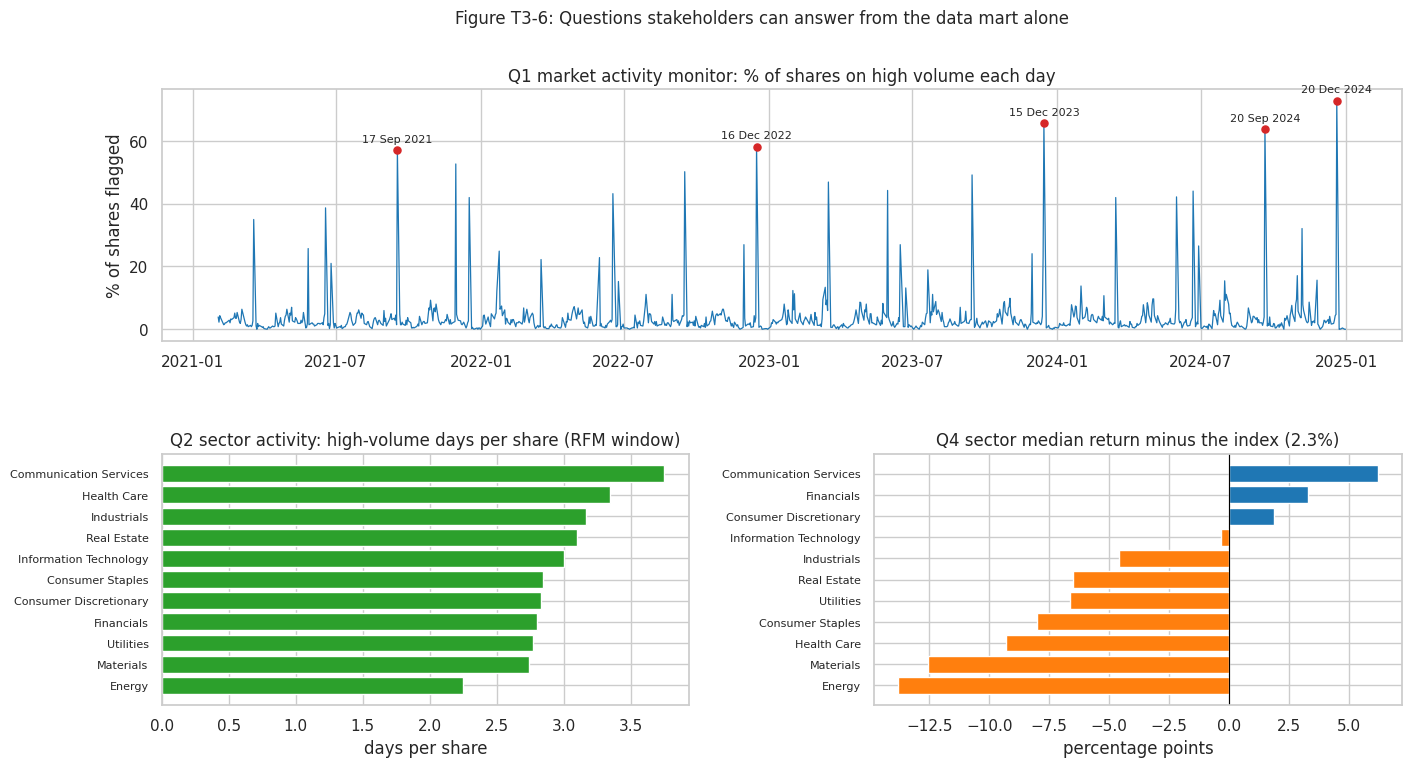

In [ ]:
# Q1 market monitor: on which days did unusually many shares trade on unusually high volume?
act = q('''SELECT t.trading_date AS date, AVG(d.high_volume_flag) AS share_flagged FROM fact_share_daily d JOIN dim_date t USING (date_key)
           GROUP BY t.trading_date ORDER BY t.trading_date''').iloc[BASE_WINDOW:]           # the first 20 sessions have no baseline yet
top_days = act.sort_values("share_flagged", ascending=False).head(5)
verify("Q1: the activity monitor equals the share of flagged shares per day in the notebook",
       np.allclose(act["share_flagged"].to_numpy(), high_volume.mean(axis=1).iloc[BASE_WINDOW:].to_numpy()))

# Q2 sector analyst: how often did shares in each sector have a high-volume day in the RFM window?
sec_act = q('''SELECT sc.sector, SUM(d.high_volume_flag) AS events, COUNT(DISTINCT d.share_key) AS shares FROM fact_share_daily d
               JOIN dim_date t USING (date_key) JOIN dim_share s USING (share_key) JOIN dim_sector sc USING (sector_key) JOIN dim_run r ON r.run_key = 1
               WHERE t.trading_date BETWEEN r.rfm_start AND r.rfm_end GROUP BY sc.sector''').set_index("sector")
sec_act["events_per_share"] = sec_act["events"] / sec_act["shares"]
verify("Q2: sector event counts equal the notebook's Frequency summed by sector",
       (sec_act["events"].sort_index().astype(int) == features.loc[keep].groupby("Sector")["F"].sum().sort_index().astype(int)).all())

# Q3 sector analyst: which sectors do the RFM Ward segments draw their shares from?
seg = q('''SELECT a.cluster_no AS cluster, sc.sector, COUNT(*) AS n FROM fact_cluster_assignment a JOIN dim_solution so USING (solution_key)
           JOIN dim_share s USING (share_key) JOIN dim_sector sc USING (sector_key) WHERE so.solution_code = 'RFM_Ward' GROUP BY a.cluster_no, sc.sector''')
seg_mix = seg.pivot(index="sector", columns="cluster", values="n").fillna(0).astype(int)
nb_mix = pd.crosstab(common["Sector"], assign["RFM_Ward"])
verify("Q3: the segment make-up by sector equals the notebook's crosstab", seg_mix.reindex(index=nb_mix.index, columns=nb_mix.columns).fillna(0).astype(int).equals(nb_mix))

# Q4 portfolio analyst: over the RFM window, did each sector's typical share beat the index? (descriptive; index is a price index)
perf = q('''WITH w AS (SELECT (SELECT MAX(trading_date) FROM dim_date WHERE trading_date < r.rfm_start) AS base_date, r.rfm_end AS end_date FROM dim_run r WHERE r.run_key = 1)
            SELECT s.ticker, sc.sector, e.adj_close / b.adj_close - 1 AS window_return, e.benchmark_close / b.benchmark_close - 1 AS index_return
            FROM w JOIN dim_date te ON te.trading_date = w.end_date JOIN dim_date tb ON tb.trading_date = w.base_date
            JOIN fact_share_daily e ON e.date_key = te.date_key JOIN fact_share_daily b ON b.date_key = tb.date_key AND b.share_key = e.share_key
            JOIN dim_share s ON s.share_key = e.share_key JOIN dim_sector sc ON sc.sector_key = s.sector_key''')
base_d = dates[dates < window[0]][-1]
verify("Q4: window returns from the mart equal Adj Close at the end / before the start - 1 in the notebook",
       np.allclose(perf.set_index("ticker")["window_return"].reindex(keep), (adj.loc[window[-1], keep] / adj.loc[base_d, keep] - 1).to_numpy()))
verify("Q4: the index return equals the benchmark level at the end / before the start - 1", np.isclose(perf["index_return"].iloc[0], bench.loc[window[-1], "Close"] / bench.loc[base_d, "Close"] - 1))
sec_perf = perf.groupby("sector")["window_return"].median().to_frame("median_share_return"); sec_perf["index_return"] = perf["index_return"].iloc[0]
sec_perf["median_minus_index"] = sec_perf["median_share_return"] - sec_perf["index_return"]

print("Q1 five days with the largest share of shares on high volume:"); display((top_days.set_index("date") * 100).round(1))
print("Q2 high-volume days per share by sector (RFM window):"); display(sec_act.sort_values("events_per_share", ascending=False).round(2))
print("Q3 RFM Ward segments by sector (number of shares):"); display(seg_mix)
print("Q4 median share return minus the index, by sector (RFM window):"); display((100 * sec_perf).round(2))
pd.concat({"Q1_top_days": top_days.set_index("date"), "Q2_sector_activity": sec_act, "Q4_sector_vs_index": sec_perf}).to_csv(f"{DATA}/data_mart_stakeholder_answers.csv")

fig = plt.figure(figsize=(16, 8)); gs = fig.add_gridspec(2, 2, hspace=0.45, wspace=0.35)
ax = fig.add_subplot(gs[0, :]); a_dates = pd.to_datetime(act["date"])
ax.plot(a_dates, 100 * act["share_flagged"], lw=0.9, color="tab:blue"); td = pd.to_datetime(top_days["date"])
ax.scatter(td, 100 * top_days["share_flagged"], color="tab:red", s=26, zorder=3)
for d_, v_ in zip(td, top_days["share_flagged"]):
    ax.annotate(f"{d_:%d %b %Y}", (d_, 100 * v_), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8)
ax.set(title="Q1 market activity monitor: % of shares on high volume each day", ylabel="% of shares flagged")
ax = fig.add_subplot(gs[1, 0]); s_ = sec_act["events_per_share"].sort_values(); ax.barh(s_.index, s_.values, color="tab:green")
ax.set(title="Q2 sector activity: high-volume days per share (RFM window)", xlabel="days per share"); ax.tick_params(axis="y", labelsize=8)
ax = fig.add_subplot(gs[1, 1]); p_ = (100 * sec_perf["median_minus_index"]).sort_values()
ax.barh(p_.index, p_.values, color=np.where(p_.values >= 0, "tab:blue", "tab:orange")); ax.axvline(0, color="black", lw=0.8)
ax.set(title=f"Q4 sector median return minus the index ({100 * sec_perf['index_return'].iloc[0]:.1f}%)", xlabel="percentage points"); ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Figure T3-6: Questions stakeholders can answer from the data mart alone", fontsize=12)
plt.savefig(f"{FIG}/t3_fig6_stakeholder_answers.png", dpi=150, bbox_inches="tight"); plt.show()
con.close()

##  Task 3.2.1 Cluster profiles and sector composition




Risk and return, Ward: Cramer's V (cluster vs sector) = 0.313, chi-square p = 7.34e-07  (descriptive: small expected counts)
   Cluster 2: Information Technology = 29 shares, 2.1x its share of the whole sample

Risk and return, K-means: Cramer's V (cluster vs sector) = 0.462, chi-square p = 9.96e-18  (descriptive: small expected counts)
   Cluster 2: Real Estate = 3 shares, 0.3x its share of the whole sample
   Cluster 2: Information Technology = 48 shares, 2.2x its share of the whole sample
   Cluster 1: Information Technology = 26 shares, 0.5x its share of the whole sample
   Cluster 2: Consumer Discretionary = 23 shares, 1.7x its share of the whole sample
   Cluster 2: Energy = 9 shares, 1.5x its share of the whole sample

Trading activity (RFM), Ward: Cramer's V (cluster vs sector) = 0.226, chi-square p = 0.00558  (descriptive: small expected counts)
   Cluster 2: Industrials = 6 shares, 0.5x its share of the whole sample
   Cluster 2: Materials = 8 shares, 2.1x its share of the w

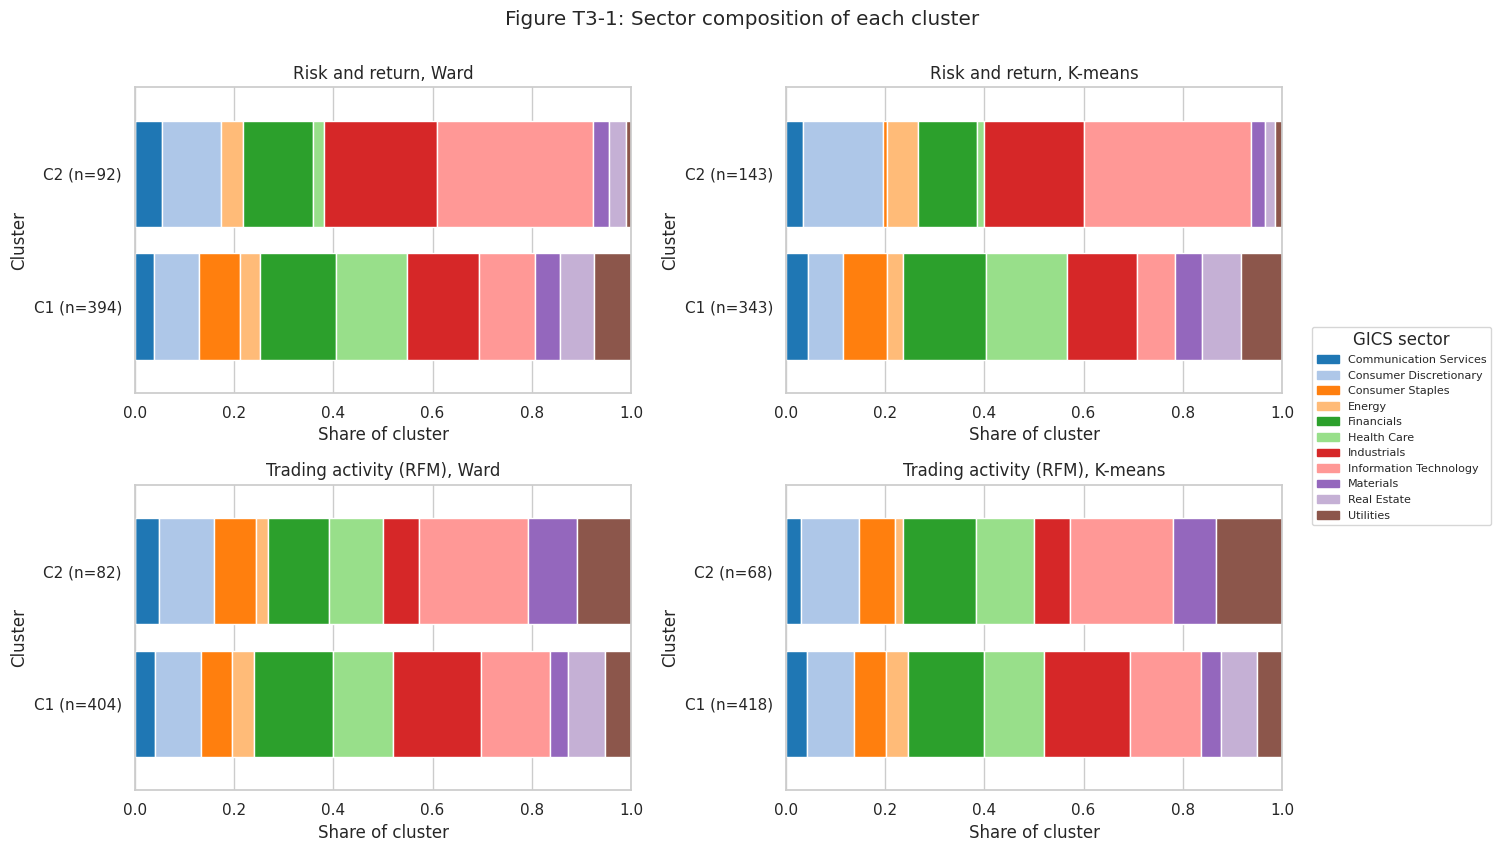

In [ ]:
def sector_tables(col):
    ct = pd.crosstab(assign[col], common["Sector"])
    share = ct.div(ct.sum(axis=1), axis=0)
    chi2, p, dof, _ = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
    lift = share.div(overall_share, axis=1)
    return ct, share, lift, p, cramers_v

sector_stats = []
for col, (name, _, _) in SOLUTIONS.items():
    ct, share, lift, p, v = sector_tables(col)
    sector_stats.append((name, ct.shape[0], v, p))
    print(f"\n{name}: Cramer's V (cluster vs sector) = {v:.3f}, chi-square p = {p:.3g}  (descriptive: small expected counts)")
    notable = [(c_, s_, int(ct.loc[c_, s_]), lift.loc[c_, s_]) for c_ in lift.index for s_ in lift.columns
               if ct.loc[c_, s_] >= 3 and (lift.loc[c_, s_] >= 1.5 or lift.loc[c_, s_] <= 0.5)]
    for c_, s_, n_, l_ in sorted(notable, key=lambda x: -abs(np.log(x[3])))[:6]:
        print(f"   Cluster {c_}: {s_} = {n_} shares, {l_:.1f}x its share of the whole sample")
    ct.to_csv(f"{DATA}/t3_sector_counts_{col}.csv"); lift.round(3).to_csv(f"{DATA}/t3_sector_lift_{col}.csv")
pd.DataFrame(sector_stats, columns=["Solution", "k", "Cramers_V", "chi2_p"]).to_csv(f"{DATA}/t3_sector_association.csv", index=False)

# Figure T3-1: sector composition of every cluster, four solutions
sec_colors = dict(zip(sorted(common["Sector"].unique()), sns.color_palette("tab20", common["Sector"].nunique())))
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
for ax, (col, (name, _, _)) in zip(axes.ravel(), SOLUTIONS.items()):
    ct, share, _, _, _ = sector_tables(col)
    share = share[sorted(share.columns)]
    share.plot.barh(stacked=True, ax=ax, color=[sec_colors[s_] for s_ in share.columns], legend=False, width=0.8)
    ax.set_xlim(0, 1); ax.set_xlabel("Share of cluster"); ax.set_ylabel("Cluster")
    ax.set_yticklabels([f"C{c_} (n={ct.loc[c_].sum()})" for c_ in share.index]); ax.set_title(name)
handles = [plt.Rectangle((0, 0), 1, 1, color=sec_colors[s_]) for s_ in sorted(sec_colors)]
fig.legend(handles, sorted(sec_colors), loc="center right", fontsize=8, title="GICS sector")
plt.suptitle("Figure T3-1: Sector composition of each cluster", y=1.0); plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.savefig(f"{FIG}/t3_fig1_sector_composition.png", dpi=150, bbox_inches="tight"); plt.show()

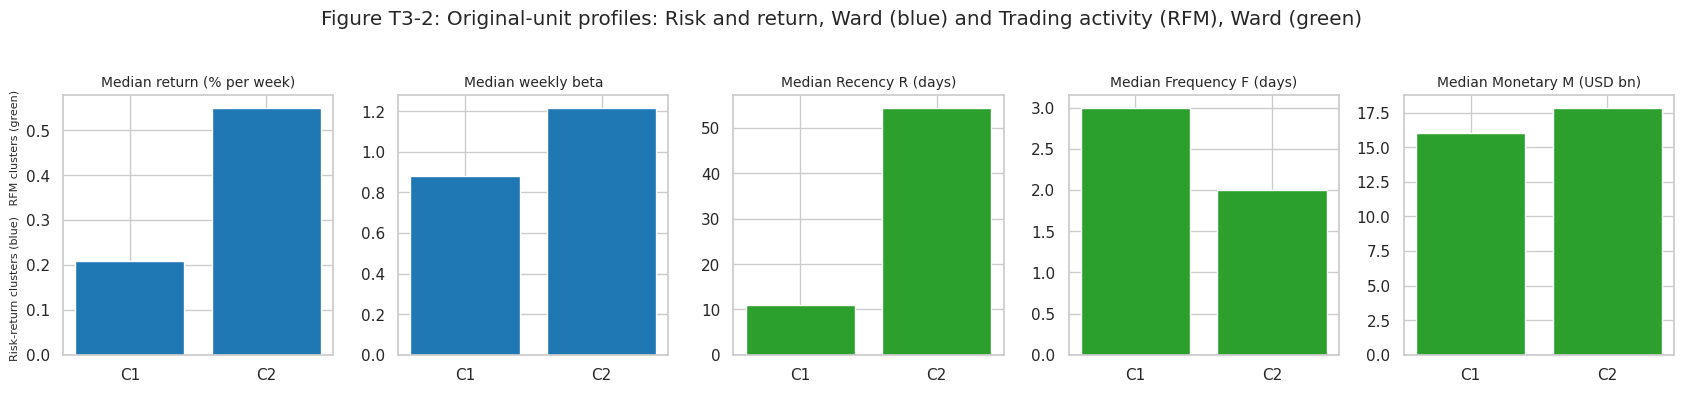

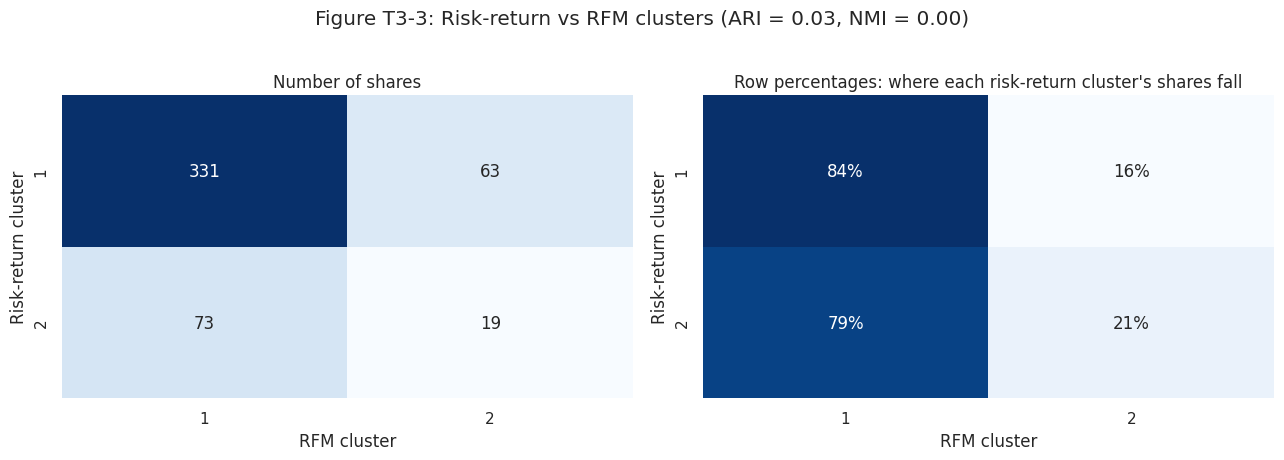

Agreement between the two families of clusters: ARI = 0.029, NMI = 0.002.
ARI near 0 means they are largely independent segmentations: trading activity does not identify risk and return groups, or the reverse.


In [ ]:
# Figure T3-2: original-unit medians, risk-return clusters beside RFM clusters
med_rr = disp.groupby(assign[T3_RR].to_numpy()).median()
med_rfm = disp.groupby(assign[T3_RFM].to_numpy()).median()
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, col_, src_, label in [(axes[0], "Return_%_per_week", med_rr, "Median return (% per week)"), (axes[1], "Beta", med_rr, "Median weekly beta"),
                              (axes[2], "R_days", med_rfm, "Median Recency R (days)"), (axes[3], "F_days", med_rfm, "Median Frequency F (days)"),
                              (axes[4], "M_USD_bn", med_rfm, "Median Monetary M (USD bn)")]:
    ax.bar([f"C{i_}" for i_ in src_.index], src_[col_], color="tab:blue" if src_ is med_rr else "tab:green")
    ax.set_title(label, fontsize=10)
axes[0].set_ylabel("Risk-return clusters (blue)   RFM clusters (green)", fontsize=8)
plt.suptitle(f"Figure T3-2: Original-unit profiles: {SOLUTIONS[T3_RR][0]} (blue) and {SOLUTIONS[T3_RFM][0]} (green)", y=1.03)
plt.tight_layout(); plt.savefig(f"{FIG}/t3_fig2_profiles.png", dpi=150, bbox_inches="tight"); plt.show()

# Figure T3-3: do the two families of clusters group the same shares?
ct_x = pd.crosstab(assign[T3_RR], assign[T3_RFM])
ari_x = adjusted_rand_score(assign[T3_RR], assign[T3_RFM]); nmi_x = normalized_mutual_info_score(assign[T3_RR], assign[T3_RFM])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(ct_x, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set(xlabel="RFM cluster", ylabel="Risk-return cluster", title="Number of shares")
sns.heatmap(ct_x.div(ct_x.sum(axis=1), axis=0), annot=True, fmt=".0%", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set(xlabel="RFM cluster", ylabel="Risk-return cluster", title="Row percentages: where each risk-return cluster's shares fall")
plt.suptitle(f"Figure T3-3: Risk-return vs RFM clusters (ARI = {ari_x:.2f}, NMI = {nmi_x:.2f})", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t3_fig3_riskreturn_vs_rfm.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Agreement between the two families of clusters: ARI = {ari_x:.3f}, NMI = {nmi_x:.3f}.")
print("ARI near 0 means they are largely independent segmentations: trading activity does not identify risk and return groups, or the reverse.")
ct_x.to_csv(f"{DATA}/t3_riskreturn_vs_rfm_counts.csv")

##  Task 3.2.2 Sensitivity findings and business uses



In [ ]:
sens_rows = [
    ("corr(R, F)", pear.loc["R", "F"]), ("corr(R, log1p_M)", pear.loc["R", "log1p_M"]), ("corr(F, log1p_M)", pear.loc["F", "log1p_M"]),
    ("Share of RFM variance on first principal axis (33.3% = independent)", 100 * eig[0] / 3),
    ("VIF R", vif["R"]), ("VIF F", vif["F"]), ("VIF log1p_M", vif["log1p_M"]),
    ("eta^2 R, Ward RFM", eta.loc["R", "RFM_Ward"]), ("eta^2 F, Ward RFM", eta.loc["F", "RFM_Ward"]), ("eta^2 log1p_M, Ward RFM", eta.loc["log1p_M", "RFM_Ward"]),
    (f"ARI: Ward RFM vs Ward R and F only (k = {final_k['act_ward']})", ari_rf),
    ("eta^2 of log1p_M across RFM clusters (M included)", eta_m["RFM_Ward (with M)"]),
    ("eta^2 of log1p_M across R and F only clusters (M removed)", eta_m["RF_only_Ward (M removed)"]),
]
sens_sheet = pd.DataFrame(sens_rows, columns=["Measure", "Value"]); sens_sheet["Value"] = sens_sheet["Value"].astype(float).round(3)
sens_sheet.to_csv(f"{DATA}/t3_sensitivity_sheet.csv", index=False)
display(sens_sheet)

# Illustration of a descriptive monitoring use: the RFM cluster with the highest median Frequency
top_c = disp.groupby(assign[T3_RFM].to_numpy())["F_days"].median().idxmax()
watch = disp.assign(Security=common["Security"], Sector=common["Sector"], RFM_cluster=assign[T3_RFM], RiskReturn_cluster=assign[T3_RR])
watch = watch[watch["RFM_cluster"] == top_c].sort_values(["F_days", "M_USD_bn"], ascending=False).head(10)
print(f"\nIllustrative monitoring list: highest-frequency RFM cluster (C{top_c}), top 10 by F then M (descriptive, not a signal)")
display(watch[["Security", "Sector", "R_days", "F_days", "M_USD_bn", "Beta", "RiskReturn_cluster"]].round(3))
watch.to_csv(f"{DATA}/t3_monitoring_list_example.csv")

,Measure,Value
0,"corr(R, F)",-0.346
1,"corr(R, log1p_M)",0.152
2,"corr(F, log1p_M)",0.013
3,Share of RFM variance on first principal axis ...,45.794
4,VIF R,1.169
5,VIF F,1.142
6,VIF log1p_M,1.029
7,"eta^2 R, Ward RFM",0.641
8,"eta^2 F, Ward RFM",0.091
9,"eta^2 log1p_M, Ward RFM",0.001



Illustrative monitoring list: highest-frequency RFM cluster (C1), top 10 by F then M (descriptive, not a signal)


,Security,Sector,R_days,F_days,M_USD_bn,Beta,RiskReturn_cluster
Ticker,,,,,,,
CI,Cigna,Health Care,13,8,37.895,0.412,1
HSY,Hershey Company (The),Consumer Staples,20,8,22.735,0.301,1
UNH,UnitedHealth Group,Health Care,14,7,151.308,0.355,1
XEL,Xcel Energy,Utilities,11,7,15.042,0.369,1
FOXA,Fox Corporation (Class A),Communication Services,11,7,9.388,0.461,1
AVGO,Broadcom,Information Technology,11,6,334.039,1.515,2
PLTR,Palantir Technologies,Information Technology,11,6,286.911,2.003,2
HON,Honeywell Technologies,Industrials,15,6,59.072,0.785,1
AJG,Arthur J. Gallagher & Co.,Financials,4,6,28.243,0.726,1


##  Task 3.2.3 Critical evaluation and limitations

Average pairwise correlation of weekly returns, all 486 shares: raw 0.300 | after removing the market component 0.052
Residual correlation, same-sector pairs 0.173 vs different-sector pairs 0.037
A positive same-sector residual correlation means beta alone does not capture how shares move together.



,Solution,Cluster,n,AvgPairCorr,AvgPairCorr_after_market,Random_group_mean,Random_group_p5,Random_group_p95,Equal_weight_vol_over_avg_vol
0,"Risk and return, Ward",1,394,0.297,0.068,0.299,0.295,0.305,0.539
1,"Risk and return, Ward",2,92,0.374,0.061,0.300,0.278,0.322,0.601
2,"Risk and return, K-means",1,343,0.302,0.090,0.300,0.294,0.306,0.542
3,"Risk and return, K-means",2,143,0.372,0.061,0.300,0.284,0.315,0.602
4,"Trading activity (RFM), Ward",1,404,0.306,0.055,0.300,0.295,0.305,0.548
5,"Trading activity (RFM), Ward",2,82,0.266,0.036,0.299,0.278,0.320,0.526
6,"Trading activity (RFM), K-means",1,418,0.305,0.056,0.300,0.296,0.304,0.547
7,"Trading activity (RFM), K-means",2,68,0.271,0.031,0.299,0.273,0.325,0.529


Equal_weight_vol_over_avg_vol near 1 means little risk reduction from holding the cluster together; lower means more diversification.


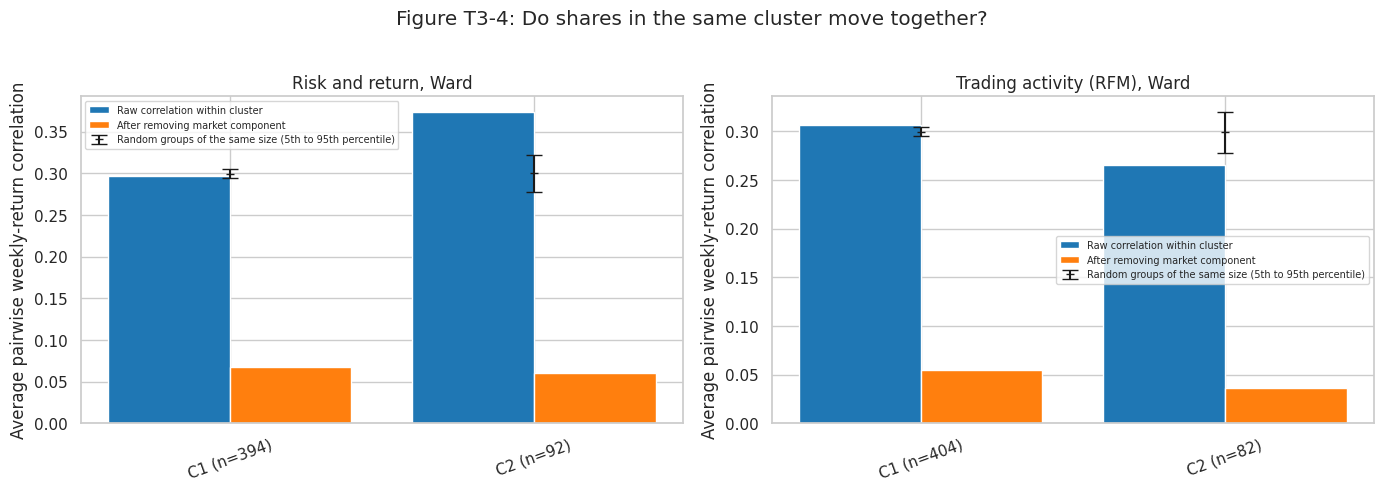

In [ ]:
R_w = wk_ret[common.index]                                  # weekly returns of the common valid shares (Task 1)
n_sh = len(common); iu = np.triu_indices(n_sh, 1)
corr_raw = R_w.corr().to_numpy()
mkt = bench_ret.loc[R_w.index]
resid = (R_w - R_w.mean()) - np.outer(mkt - mkt.mean(), beta.loc[common.index].to_numpy())     # remove each share's market component
corr_res = pd.DataFrame(resid).corr().to_numpy()
rng = np.random.default_rng(SEED)

def avg_pair(cm, idx):
    sub = cm[np.ix_(idx, idx)]; m = len(idx)
    return (sub.sum() - m) / (m * (m - 1)) if m > 1 else np.nan

print(f"Average pairwise correlation of weekly returns, all {n_sh} shares: raw {corr_raw[iu].mean():.3f} | after removing the market component {corr_res[iu].mean():.3f}")
sec_arr = common["Sector"].to_numpy(); same = (sec_arr[:, None] == sec_arr[None, :])[iu]
print(f"Residual correlation, same-sector pairs {corr_res[iu][same].mean():.3f} vs different-sector pairs {corr_res[iu][~same].mean():.3f}")
print("A positive same-sector residual correlation means beta alone does not capture how shares move together.\n")

rows = []
for col, (name, _, _) in SOLUTIONS.items():
    lab = assign[col].to_numpy()
    for c_ in np.unique(lab):
        idx = np.where(lab == c_)[0]
        if len(idx) < 3: continue
        null = np.array([avg_pair(corr_raw, rng.choice(n_sh, len(idx), replace=False)) for _ in range(300)])
        port_vol = R_w.iloc[:, idx].mean(axis=1).std(); mean_vol = R_w.iloc[:, idx].std().mean()
        rows.append({"Solution": name, "Cluster": c_, "n": len(idx), "AvgPairCorr": avg_pair(corr_raw, idx),
                     "AvgPairCorr_after_market": avg_pair(corr_res, idx), "Random_group_mean": null.mean(),
                     "Random_group_p5": np.percentile(null, 5), "Random_group_p95": np.percentile(null, 95),
                     "Equal_weight_vol_over_avg_vol": port_vol / mean_vol})
dep = pd.DataFrame(rows)
dep.to_csv(f"{DATA}/t3_return_dependence.csv", index=False)
display(dep.round(3))
print("Equal_weight_vol_over_avg_vol near 1 means little risk reduction from holding the cluster together; lower means more diversification.")

# Figure T3-4
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, cols_ in [(axes[0], [SOLUTIONS[T3_RR][0]]), (axes[1], [SOLUTIONS[T3_RFM][0]])]:
    d_ = dep[dep["Solution"].isin(cols_)]
    x_ = np.arange(len(d_))
    ax.bar(x_ - 0.2, d_["AvgPairCorr"], width=0.4, label="Raw correlation within cluster", color="tab:blue")
    ax.bar(x_ + 0.2, d_["AvgPairCorr_after_market"], width=0.4, label="After removing market component", color="tab:orange")
    ax.errorbar(x_, d_["Random_group_mean"], yerr=[d_["Random_group_mean"] - d_["Random_group_p5"], d_["Random_group_p95"] - d_["Random_group_mean"]],
                fmt="k_", capsize=6, label="Random groups of the same size (5th to 95th percentile)")
    ax.set_xticks(x_); ax.set_xticklabels([f"C{c_} (n={n_})" for c_, n_ in zip(d_["Cluster"], d_["n"])], rotation=20)
    ax.set_ylabel("Average pairwise weekly-return correlation"); ax.set_title(cols_[0]); ax.legend(fontsize=7)
plt.suptitle("Figure T3-4: Do shares in the same cluster move together?", y=1.02); plt.tight_layout()
plt.savefig(f"{FIG}/t3_fig4_return_dependence.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# Remaining limitation evidence, collected from the earlier sections
ev = []
bc = beta.loc[common.index].corr(beta_close.loc[common.index]); bd = (beta.loc[common.index] - beta_close.loc[common.index]).abs()
ev += [("Price basis: correlation of beta on Adj Close vs Close", bc), ("Price basis: median absolute beta difference", bd.median()),
       ("Price basis: largest absolute beta difference", bd.max())]
ev += [("Beta estimation: median standard error", se.loc[common.index].median()),
       ("Beta estimation: correlation of first-half and second-half beta", b_first.loc[common.index].corr(b_last.loc[common.index]))]
if "Date_added" in sp500.columns:
    added = pd.to_datetime(sp500.set_index("Ticker").loc[common.index, "Date_added"], errors="coerce")
    ev += [("Survivorship: clustering shares that joined the index before 2021 (%)", 100 * (added < pd.Timestamp(START)).mean()),
           ("Survivorship: joined during 2021 to 2024 (%)", 100 * ((added >= pd.Timestamp(START)) & (added < pd.Timestamp(END))).mean()),
           ("Survivorship: joined after the study window (%)", 100 * (added >= pd.Timestamp(END)).mean())]
ev += [("Survivorship: tickers on the list that failed validation (share excluded, %)", 100 * (1 - len(keep) / len(tickers))),
       ("Feature overlap: effective independent dimensions in RFM (of 3)", eig.sum() ** 2 / (eig ** 2).sum()),
       ("Feature overlap: ARI when M is removed", ari_rf)]
liq = disp.groupby(assign[T3_RFM].to_numpy())["M_USD_bn"].median()
ev += [("Liquidity proxy: highest cluster median M (USD bn)", liq.max()), ("Liquidity proxy: lowest cluster median M (USD bn)", liq.min()),
       ("Liquidity proxy: ratio of highest to lowest", liq.max() / liq.min())]
evidence = pd.DataFrame(ev, columns=["Evidence", "Value"]); evidence["Value"] = evidence["Value"].astype(float).round(3)
evidence.to_csv(f"{DATA}/t3_limitations_evidence.csv", index=False)
display(evidence)
print("Traded value (Close x Volume) is a liquidity PROXY only: bid-ask spreads and price impact are not measured.")
print("Clusters describe 2021 to 2024 behaviour of today's S&P 500 members. They do not forecast returns or show reduced portfolio risk.")

,Evidence,Value
0,Price basis: correlation of beta on Adj Close ...,1.000
1,Price basis: median absolute beta difference,0.001
2,Price basis: largest absolute beta difference,0.017
3,Beta estimation: median standard error,0.101
4,Beta estimation: correlation of first-half and...,0.783
5,Survivorship: clustering shares that joined th...,85.185
6,Survivorship: joined during 2021 to 2024 (%),9.671
7,Survivorship: joined after the study window (%),5.144
8,Survivorship: tickers on the list that failed ...,3.380
9,Feature overlap: effective independent dimensi...,2.738


Traded value (Close x Volume) is a liquidity PROXY only: bid-ask spreads and price impact are not measured.
Clusters describe 2021 to 2024 behaviour of today's S&P 500 members. They do not forecast returns or show reduced portfolio risk.


###  Descriptive or predictive? An out of sample test



PASSED: the same recipe on all weeks reproduces the Task 1 weekly beta
PASSED: the two halves do not overlap and cover every week


,k,cluster,n,first_half_return_%,second_half_return_%,p_return_vs_random,first_half_beta,second_half_beta,second_half_vol_%,vol_vs_all_shares,random_group_vol_range
0,2,1,400,0.258,0.321,0.001,0.900,0.827,12.629,0.908,13.6 to 14.2
1,2,2,86,-0.197,0.729,0.001,1.469,1.565,23.110,1.662,12.9 to 15.5


Rank correlation of each share's first-half and second-half mean return: -0.144
Rank correlation of each share's first-half and second-half beta:        0.796
A return correlation near 0 means past return does not carry over; a high beta correlation means beta is a more stable description than return.


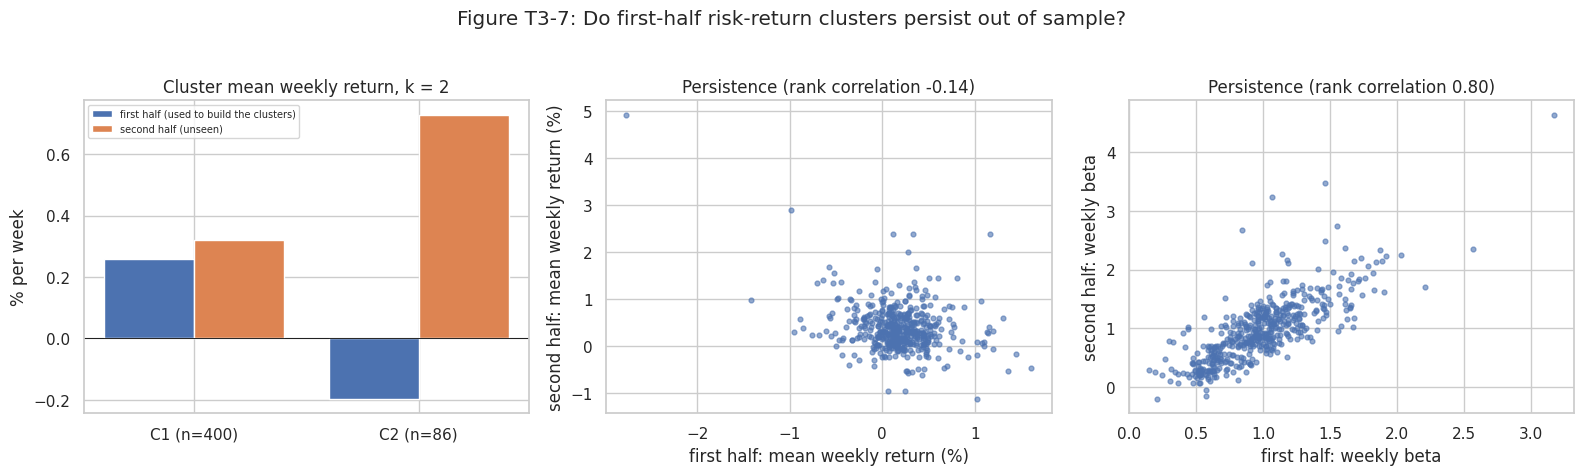

In [ ]:
from scipy.stats import spearmanr
R_all = wk_ret[common.index]; mk = bench_ret.loc[R_all.index]
n_w = len(R_all); half_w = n_w // 2
H1, H2, m1, m2 = R_all.iloc[:half_w], R_all.iloc[half_w:], mk.iloc[:half_w], mk.iloc[half_w:]
def half_feats(Rh, mh):
    return pd.DataFrame({"ret": Rh.mean(), "beta": Rh.apply(lambda s_: s_.cov(mh) / mh.var(ddof=1))})
verify("the same recipe on all weeks reproduces the Task 1 weekly beta", np.allclose(half_feats(R_all, mk)["beta"], beta.loc[common.index]))
F1, F2 = half_feats(H1, m1), half_feats(H2, m2)
verify("the two halves do not overlap and cover every week", len(H1) + len(H2) == n_w and not set(H1.index) & set(H2.index))

rng = np.random.default_rng(SEED); RA2 = H2.to_numpy(); ann = np.sqrt(52)
def port(ids):
    p_ = RA2[:, ids].mean(axis=1)
    return 100 * p_.mean(), 100 * p_.std(ddof=1) * ann
rows = []
for k_ in sorted({2, final_k["rr_ward"]}):
    lab = pd.Series(AgglomerativeClustering(n_clusters=k_, linkage="ward").fit_predict(StandardScaler().fit_transform(F1)), index=F1.index)
    order = F1["beta"].groupby(lab).median().sort_values().index                      # number clusters from lowest to highest first-half beta
    lab = lab.map({c_: i_ + 1 for i_, c_ in enumerate(order)})
    all_ret, all_vol = port(np.arange(len(F1)))
    for c_ in range(1, k_ + 1):
        ids = np.where(lab.to_numpy() == c_)[0]
        if len(ids) < 3: continue
        draws = np.array([port(rng.choice(len(F1), len(ids), replace=False)) for _ in range(1000)])
        r2, v2 = port(ids)
        rows.append({"k": k_, "cluster": c_, "n": len(ids), "first_half_return_%": 100 * F1["ret"].iloc[ids].mean(), "second_half_return_%": r2,
                     "p_return_vs_random": (1 + (np.abs(draws[:, 0] - draws[:, 0].mean()) >= abs(r2 - draws[:, 0].mean())).sum()) / 1001,
                     "first_half_beta": F1["beta"].iloc[ids].median(), "second_half_beta": F2["beta"].iloc[ids].median(),
                     "second_half_vol_%": v2, "vol_vs_all_shares": v2 / all_vol, "random_group_vol_range": f"{np.percentile(draws[:, 1], 2.5):.1f} to {np.percentile(draws[:, 1], 97.5):.1f}"})
oos = pd.DataFrame(rows); oos.to_csv(f"{DATA}/t3_out_of_sample_test.csv", index=False)
rho_ret, rho_beta = spearmanr(F1["ret"], F2["ret"])[0], spearmanr(F1["beta"], F2["beta"])[0]
display(oos.round(3))
print(f"Rank correlation of each share's first-half and second-half mean return: {rho_ret:.3f}")
print(f"Rank correlation of each share's first-half and second-half beta:        {rho_beta:.3f}")
print("A return correlation near 0 means past return does not carry over; a high beta correlation means beta is a more stable description than return.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
k_show = oos["k"].max(); d_ = oos[oos["k"] == k_show]; x_ = np.arange(len(d_))
axes[0].bar(x_ - 0.2, d_["first_half_return_%"], 0.4, label="first half (used to build the clusters)"); axes[0].bar(x_ + 0.2, d_["second_half_return_%"], 0.4, label="second half (unseen)")
axes[0].set_xticks(x_); axes[0].set_xticklabels([f"C{c_} (n={n_})" for c_, n_ in zip(d_["cluster"], d_["n"])]); axes[0].axhline(0, color="black", lw=0.6)
axes[0].set(title=f"Cluster mean weekly return, k = {k_show}", ylabel="% per week"); axes[0].legend(fontsize=7)
for ax_, a_, b_, lab_, rho_ in [(axes[1], F1["ret"] * 100, F2["ret"] * 100, "mean weekly return (%)", rho_ret), (axes[2], F1["beta"], F2["beta"], "weekly beta", rho_beta)]:
    ax_.scatter(a_, b_, s=12, alpha=0.6); ax_.set(xlabel=f"first half: {lab_}", ylabel=f"second half: {lab_}", title=f"Persistence (rank correlation {rho_:.2f})")
plt.suptitle("Figure T3-7: Do first-half risk-return clusters persist out of sample?", y=1.03); plt.tight_layout()
plt.savefig(f"{FIG}/t3_fig7_out_of_sample.png", dpi=150, bbox_inches="tight"); plt.show()

###  The liquidity proxy - how good is Monetary?

Monetary is **traded value** (Close x Volume), a proxy for liquidity. A direct liquidity cost would be spreads and price impact, which this data does not contain.
As a check, the **Amihud measure** (average absolute daily return per dollar traded) is a rough price-impact figure: if Monetary is a good liquidity stand-in, shares with high traded value should show a **small** price move per dollar. The cell also shows what distorts Monetary (market-wide high-volume days) and how concentrated it is.

,Evidence,Value
0,Spearman: Monetary vs Amihud price impact (neg...,-0.936
1,"bootstrap 95% interval, low",-0.948
2,"bootstrap 95% interval, high",-0.921
3,Market-wide high-volume days inside the RFM wi...,2.000
4,Median share of a share's Monetary that comes ...,6.947
5,Spearman: Monetary vs Monetary excluding those...,0.999
6,Shares that change traded-value quartile when ...,2.058
7,Share of total Monetary held by the 10 largest...,36.291
8,Share of total Monetary held by the top 5% of ...,46.128
9,eta^2: log Amihud across the RFM Ward clusters...,0.000


PASSED: Amihud measure equals a hand calculation for the first share
Traded value is a proxy: bid-ask spreads and true price impact are not measured. A strong negative rank correlation supports it; a weak one warns against reading Monetary as liquidity.


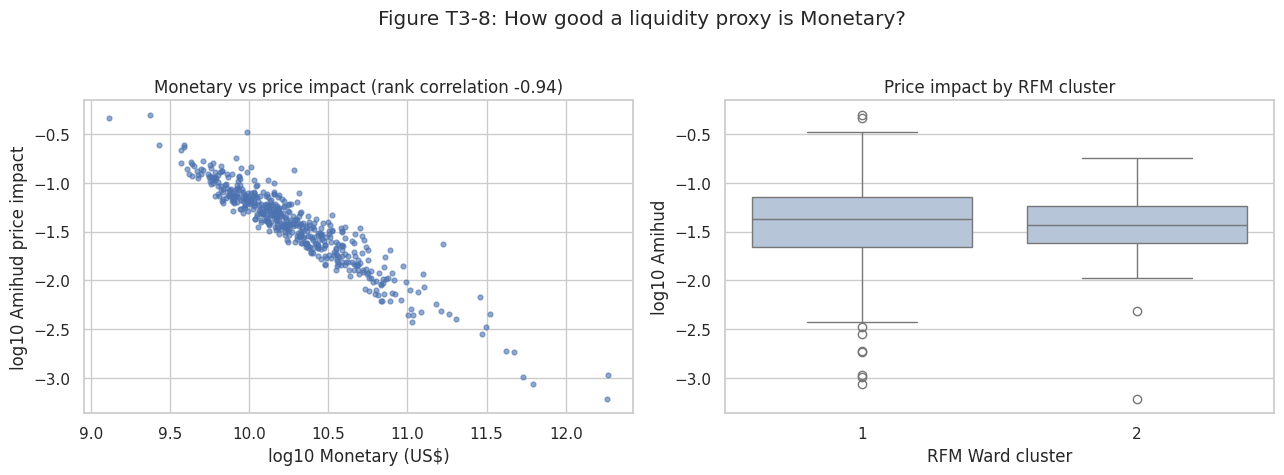

In [ ]:
from scipy.stats import spearmanr
tv = (close.loc[window, common.index] * vol.loc[window, common.index])
ret_w = adj[common.index].pct_change(fill_method=None).loc[window]
amihud = (ret_w.abs() / tv).mean() * 1e9                     # average |daily return| per US$1 billion traded: higher = prices move more per dollar traded
Mv = common["M"]
rho_liq = spearmanr(Mv, amihud)[0]
rb = np.random.default_rng(SEED); nn = len(Mv)
boot = [spearmanr(Mv.to_numpy()[i_], amihud.to_numpy()[i_])[0] for i_ in (rb.integers(0, nn, nn) for _ in range(1000))]
lo_, hi_ = np.percentile(boot, [2.5, 97.5])

breadth = high_volume.mean(axis=1)                            # share of shares flagged each day (Task 1.4)
mkt_days = [d_ for d_ in window if breadth.get(d_, 0) > 0.30]
M_ex = tv.drop(index=mkt_days).sum() if mkt_days else tv.sum()
q_all, q_ex = pd.qcut(Mv.rank(method="first"), 4, labels=False), pd.qcut(M_ex.rank(method="first"), 4, labels=False)
top10 = Mv.nlargest(min(10, nn)).sum() / Mv.sum(); top5 = Mv.nlargest(max(1, int(round(0.05 * nn)))).sum() / Mv.sum()
eta_a = eta_squared(np.log(amihud.clip(lower=1e-12)), assign["RFM_Ward"])
liq = pd.DataFrame([
    ("Spearman: Monetary vs Amihud price impact (negative = Monetary is a sensible liquidity proxy)", rho_liq),
    ("   bootstrap 95% interval, low", lo_), ("   bootstrap 95% interval, high", hi_),
    ("Market-wide high-volume days inside the RFM window (more than 30% of shares flagged)", len(mkt_days)),
    ("Median share of a share's Monetary that comes from those days (%)", 100 * (1 - M_ex / Mv).median() if mkt_days else 0.0),
    ("Spearman: Monetary vs Monetary excluding those days", spearmanr(Mv, M_ex)[0]),
    ("Shares that change traded-value quartile when those days are excluded (%)", 100 * (q_all != q_ex).mean()),
    ("Share of total Monetary held by the 10 largest shares (%)", 100 * top10), ("Share of total Monetary held by the top 5% of shares (%)", 100 * top5),
    ("eta^2: log Amihud across the RFM Ward clusters (do the clusters separate price impact?)", eta_a)], columns=["Evidence", "Value"])
liq["Value"] = liq["Value"].astype(float).round(3); liq.to_csv(f"{DATA}/t3_liquidity_proxy_evidence.csv", index=False); display(liq)
verify("Amihud measure equals a hand calculation for the first share",
       np.isclose(amihud.iloc[0], np.mean([abs(r_) / v_ for r_, v_ in zip(ret_w.iloc[:, 0], tv.iloc[:, 0]) if np.isfinite(r_)]) * 1e9))
print("Traded value is a proxy: bid-ask spreads and true price impact are not measured. A strong negative rank correlation supports it; a weak one warns against reading Monetary as liquidity.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].scatter(np.log10(Mv), np.log10(amihud.clip(lower=1e-12)), s=12, alpha=0.6)
axes[0].set(xlabel="log10 Monetary (US$)", ylabel="log10 Amihud price impact", title=f"Monetary vs price impact (rank correlation {rho_liq:.2f})")
sns.boxplot(x=assign["RFM_Ward"].to_numpy(), y=np.log10(amihud.clip(lower=1e-12)).to_numpy(), ax=axes[1], color="lightsteelblue")
axes[1].set(xlabel="RFM Ward cluster", ylabel="log10 Amihud", title="Price impact by RFM cluster")
plt.suptitle("Figure T3-8: How good a liquidity proxy is Monetary?", y=1.03); plt.tight_layout()
plt.savefig(f"{FIG}/t3_fig8_liquidity_proxy.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
with open(f"{DATA}/README_task3.txt", "w") as f:
    f.write(f"Task 3 evidence: compared {T3_RR} with {T3_RFM}\n")
    f.write("3.1: crm_data_mart.sqlite, data_mart_schema.sql, data_mart_erd.md, data_mart_inventory, data_mart_lineage, data_mart_reproducibility, data_mart_stakeholder_answers\n")
    f.write("3.2: t3_sector_*, t3_riskreturn_vs_rfm_counts, t3_sensitivity_sheet, t3_monitoring_list_example, t3_return_dependence, t3_limitations_evidence, t3_out_of_sample_test, t3_liquidity_proxy_evidence\n")
shutil.make_archive("crm_cw1_all_data", "zip", DATA)
shutil.make_archive("crm_cw1_all_figures", "zip", FIG)
for folder in (DATA, FIG):
    print(f"{folder}: {len(os.listdir(folder))} files")
try:
    from google.colab import files
    files.download("crm_cw1_all_data.zip"); files.download("crm_cw1_all_figures.zip")
except ImportError:
    pass
print("Download zipfile.")

data: 98 files
figures: 36 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download zipfile.
